# AJUSTAR E COLOCAR OS ERROS RESPECTIVOS DE CADA EXOPLAENTA. OS VALORES OBTIDOS N VÃO MUDAR, SÓ O CHI MESMO

# Author: Lena Noack
# GNU General Public License v3.0 (GPL-3.0)
#Interior Structure Model


In [1]:
import numpy as np
import math
import csv
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
from EOS_functions import EOS_rock, EOS_core, EOS_core_mixed
from values import *
from Help_functions import get_Tmelt_MO, get_Tmelt_core, get_Tmelt_water, getphase
from water import getWater


# Start interior structure model with the temperature and pressure equation.

In [3]:
def temp_pla2(T_e, R_e, a):
    t_p=T_e*(R_e/(2*a))**(1/2)
    return t_p

# Units: 1, kg, kg, km, km, dimensionless 
def pressao(P_t, M_p, M_t, R_p, R_t, tipo): 
    if tipo == 1: #Mercury
        beta = 1.05*10**(-13)
    elif tipo == 0:#Venus
        beta = 108.27
    elif tipo == 2:#marte
        beta = 0.0467
    elif tipo==3 or tipo==4 : #Earth
        beta = 1.014
    else:#Any other type, I'll disregard those anyway.
        beta=1
    P=beta*((M_p/M_t)**2)*((R_t/R_p)**4)*P_t
    return P*101325

In [4]:
def interior_structure(M,x_Fe_tot,x_H2O_tot, t, P):
  '''
  input:
   M: Mass in Earth masses
   x_Fe_tot: Iron weigth fraction in percent of the entire planet (core + mantle)
   x_H2O_tot: Water weigth fraction in percent of surface water/ice layer
  return:
   Rp_E - planet radius in Earth radii
   MOI - moment of inertia factor
   radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu - profiles of different planetary properties
   mat - material layers (<0 ices, 0 water, >0 different rock and core layers)
  '''

  '''Set initialization parameters'''
  Dcr = 50e3      # thickness of crustal layer in m
  Dlid = 300e3    # thickness of lithosphere, only used to set upper mantle temperature
  Psurf = P     # atmospheric surface pressure
  Tsurf = t     # potential surface temperature in K
  Tlid = 0.0    #2000 # in K; if set to 0, then mantle melt temp is used at Dlid depth to set Tlid
  DTcmb = -1.0  #1500 # in K, T jump at CMB; if set to neg value (e.g. -1), then jump is calculated via melt temp times -DTcmb
  nr = 500         # radial resolution from center of planet to surface
  tol = 0.001     # Convergence parameter
  maxIter = 20   # max number iterations

  # light elements in the core -> array added for molar fractions Si,C,S,O; e.g. (0.2 S -> Fe0.8S0.2), means weight fraction of 12 wt-% S
  xelem = np.array([0.0,0.0,0.2,0.0]) # initial core-averaged value
  xelem_ic = np.array([0.00,0.00,0.07,0.00]) # fixed inner core value (no real partitioning included yet; outer core value calculated during inner core growth

  X_FeM_mol = 0.1 # iron number in mantle (ratio of Fe-bearing molecules divided by Mg- and Fe-bearing molecules)
  X_H2OM = 0      # water content in mantle in wt-%, only used for el cond profile versions 2-4
  ec_model = 1    # electrical conductivity profiles: 1 - Xu, 2 - mat-dep prof without Fe, 3 - as 2 but with Fe dependence, 4 - as 3 but newer parameters


  '''Distribute iron between core and mantle'''

  x_Fe_tot = x_Fe_tot/100 # weight fraction instead of percent
  x_H2O_tot = x_H2O_tot/100
  M = M * 5.972*10**24 # mass in kg
  Mw = M*x_H2O_tot 
  G = 6.67384*10**(-11) # gravitational constant in m^3 / (kg s^2)

  # Molar masses:
  mMg=24.305; mFe=55.845; mSi=28.0855; mO=15.9994

  XmFe = 2*X_FeM_mol*mFe/(X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) # mantle mass fraction of iron w.r.t. mantle mass

  
  x_Fe = ( x_Fe_tot*M - XmFe*(M-Mw) ) / (M*(1-XmFe)) # core mass fraction w.r.t. total planet mass
  Mc = x_Fe*M
  if Mc<0.0:
      raise ValueError(f"Not enough iron in planet to have {iron_number} as iron number")
      Mc = 0.0
      x_Fe = 0.0
      XmFe = x_Fe_tot*M / (M-Mw) # adapt XmFe such that all iron is in mantle

      #XmFe * (X_FeM_mol*2*(mFe-mMg) + 2*mMg+mSi+4*mO) = 2*X_FeM_mol*mFe
      X_FeM_mol = XmFe*(2*mMg+mSi+4*mO)/(2*mFe-2*(mFe-mMg)*XmFe) # adapt mantle iron number

  Mm = M - Mc - Mw

  '''Initialization routines'''

  rho_c = 11000 # guess for core density in kg/m^3
  rho_m = 4000 # guess for mantle density in kg/m^3
  rho_w = 1000 # guess for water density in kg/m^3
  cp_c = 800 # guess for core heat capacity in J/kg K
  cp_m = 1300 # guess for mantle heat capacity in J/kg K
  cp_w = 4200 # guess for water heat capacity in J/kg K
  alpha_c = 0.00001 # guess for core thermal expansion ceoff. in 1/K
  alpha_m = 0.000025 # guess for mantle thermal expansion ceoff. in 1/K
  alpha_w = 0.00007 # guess for water thermal expansion ceoff. in 1/K

  Rc = ( Mc*3.0 / (4.0*math.pi*rho_c) )**(1/3) # first guess core radius
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius
  Rp = ( Mw*3.0 / (4.0*math.pi*rho_w) + Rm**3 )**(1/3) # first guess planet radius

  # Define arrays
  dr = np.zeros(nr) # distance between radius points
  radius = np.zeros(nr) # vector of radii, first radius is dr
  pressure = np.zeros(nr)
  gravity = np.zeros(nr)
  temperature = np.zeros(nr)
  density = np.zeros(nr)
  alpha = np.zeros(nr)
  cp = np.zeros(nr)
  KT = np.zeros(nr)
  KS = np.zeros(nr)
  mu = np.zeros(nr)
  mass = np.zeros(nr)
  mat = np.zeros(nr)
  elcond = np.zeros(nr)

  # set number of grid points in the three layers (core/mantle/water) based on initial radii, to be kept constant throughout iteration
  nc = int(nr * Rc/Rp)
  if (x_H2O_tot==0):
    nm = nr - nc
    nw = 0
  else:
    nm = int(nr * Rm/Rp) - nc
    nw = nr - nm - nc

  # Initialization of arrays: surface values
  if Mw>0:
    density[nr-1] = rho_w
    alpha[nr-1] = alpha_w
    cp[nr-1] = cp_w
  elif Mm>0:
    density[nr-1] = rho_m
    alpha[nr-1] = alpha_m
    cp[nr-1] = cp_m
  else: # pure iron shell
    density[nr-1] = rho_c
    alpha[nr-1] = alpha_c
    cp[nr-1] = cp_c
    Rc = Rp

  # Initialization of arrays: interpolation over depth
  for i in range(0,nr):
    if i==0:
      r_prev = 0.0
    else:
      r_prev = radius[i-1]
    if i<nc:
      dr[i] = Rc/float(nc)
      density[i] = rho_c
      alpha[i] = alpha_c
      cp[i] = cp_c
    elif i<nc+nm:
      dr[i] = (Rm-Rc)/float(nm)
      density[i] = rho_m
      alpha[i] = alpha_m
      cp[i] = cp_m
    else:
      dr[i] = (Rp-Rm)/float(nw)
      density[i] = rho_w
      alpha[i] = alpha_w
      cp[i] = cp_w
    radius[i] = r_prev + dr[i]


  # pressure and temperature are interpolated from surface downwards
  # gravity has boundary condition 0 in center (and not at surface)
  pressure[nr-1] = Psurf # 1 bar surface pressure
  temperature[nr-1] = Tsurf # surface temperature
  gravity[nr-1] = G*M/Rp**2 # first guess surface gravity
  plid = Dlid*rho_m*gravity[nr-1] # first guess at plid, will be calculated below


  '''Start iteration to determine interior structure'''

  iter = 1
  Store_V_vec_old = []
  Rp_old = 0
  while (abs(Rp-Rp_old) > tol) and (iter < maxIter):
      # store old Rp value to determine convergence
      Rp_old = Rp

      # average values will be re-determined from material properties
      rho_c = 0; rho_m = 0; rho_w = 0; vol_c = 0; vol_m = 0; vol_w = 0

      # update vectors for radius, gravity, pressure and temperature
      for i in range(0,nr):
        if i==0:
          r_prev = 0.0
        else:
          r_prev = radius[i-1]
        if i<nc:
          dr[i] = Rc/float(nc)
        elif i<nc+nm:
          dr[i] = (Rm-Rc)/float(nm)
        else:
          dr[i] = (Rp-Rm)/float(nw)
        radius[i] = r_prev + dr[i]

      
      gravity[0] = radius[0] * 4/3*math.pi*G*density[0]
      for i in range(1,nr):
          gravity[i] = gravity[i-1] + dr[i-1] * (4*math.pi*G*density[i-1] - 2*gravity[i-1]/radius[i-1])

      for i in range(nr-2,-1,-1):
          pressure[i] = pressure[i+1] + dr[i]*gravity[i]*density[i]
          if i>=nc+nm: # ocean layer, we assume here adiabatic profile from the surface
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          elif Rm-radius[i]<Dlid: # in lithosphere
              if Mw>0:
                Ts = temperature[nc+nm]
              else:
                Ts = Tsurf
              if Tlid>0:
                  
                  temperature[i] = Ts + (Tlid-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
              else:
                  temperature[i] = Ts + (get_Tmelt_MO(plid)-Ts)*(radius[nc+nm-1]-radius[i])/Dlid
          elif Rm-radius[i+1]<Dlid: # first grid point in mantle
              if Tlid>0:
                  temperature[i] = Tlid 
              else:
                  temperature[i] = get_Tmelt_MO(plid) 
              plid = pressure[i] 
          elif (i+1==nc):
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
              if DTcmb >= 0:
                  
                  temperature[i] = temperature[i] + DTcmb
              else:
                  
                  temperature[i] = temperature[i] + (get_Tmelt_MO(pressure[i])-temperature[i]) * abs(DTcmb)
          else: 
              temperature[i] = temperature[i+1] + dr[i]*alpha[i+1]/cp[i+1] * gravity[i+1]*temperature[i+1]
          
      Store_V_vec = []
      ric = 0
      for i in range(nr): # from center to surface
          # get correct layer depending on core size, mantle phase transitions, and crust thickness
          # 7 layers in total: 6-core, 5-ppv, 4-pv, 3-ri, 2-wa, 1-ol, 0-cr
          if i < nc:
              # iron core
              if temperature[i]<get_Tmelt_core(pressure[i]):
                mat[i] = 8 # inner core
                ric = radius[i] # updated until outer core is reached
              else:
                mat[i] = 7 # outer core
              arr_species = ['fehcp']
              mole_vec = [1]
          elif i >= nc+nm:
              # water layer
              mat[i] = 0 # liquid water or water ice, phase defined below
              arr_species = ['h2o']
              [Tm,phase] = get_Tmelt_water(pressure[i])
              if temperature[i]<Tm:
                mat[i] = -phase # ice phases stored with negative values
              mole_vec = [1]
          elif pressure[i] >= (127 + 0.006*(temperature[i]-2840))*10**9:
              # post-perovskite
              mat[i] = 6
              arr_species = ['mppv', 'fppv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif pressure[i] >= (22.9 - 0.0025*(temperature[i]-2260))*10**9:
              # perovskite
              mat[i] = 5
              arr_species = ['mgpv', 'fepv','pe','wu']
              mole_vec = [0.5*(1-X_FeM_mol),0.5*(X_FeM_mol),0.5*(1-X_FeM_mol),0.5*(X_FeM_mol)]
          elif (pressure[i] >= (6.2 + 16.7*(1-X_FeM_mol) + 0.005*(temperature[i]-2260))*10**9) & (radius[i] <= Rm-Dcr):
              # ringwoodite
              mat[i] = 4
              arr_species = ['mgri', 'feri']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif (pressure[i] >= (4.92 + 5.4*(1-X_FeM_mol) + 0.0025*temperature[i])*10**9) & (radius[i] <= Rm-Dcr):
              # wadsleyite
              mat[i] = 3
              arr_species = ['mgwa', 'fewa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          elif radius[i] <= Rm-Dcr:
              # olivine
              mat[i] = 2
              arr_species = ['fo', 'fa']
              mole_vec = [1-X_FeM_mol,X_FeM_mol]
          else:
              # crust
              mat[i] = 1
              arr_species = ['an','di','qtz'] #Anorthite Feldspar Ca[Al2Si2]O8; Diopside CaMgSi2O6; Quartz SiO2
              mole_vec = [0.5, 0.25, 0.25]

          # mole fraction to mass fraction
          molmass = np.zeros(len(mole_vec))
          for k,species in enumerate(arr_species):
              res = values(species) # params for species
              molmass[k] = res.M
          mf_vec = mole_vec*molmass / np.sum(mole_vec*molmass)


         
          if mat[i] >= 7:
              if mat[i] == 8:
                xelemc = xelem_ic
              else:
                xelemc = (xelem * radius[nc-1]**3 - xelem_ic*ric**3)/(radius[nc-1]**3-ric**3) 
              
              cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_core_mixed(pressure[i]/10**9,temperature[i],xC=xelemc[1], xSi=xelemc[0], xS=xelemc[2], xO=xelemc[3])

          else:
              if Store_V_vec_old == []:
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec)
              else:
                 
                  cp[i],density[i],alpha[i],KT[i],KS[i],mu[i],V_vec = EOS_rock(pressure[i]/10**9,temperature[i],arr_species,mf_vec,Store_V_vec_old[i])
          Store_V_vec.append(V_vec)

          # check profiles
          # update mass vector (used here only for visualization)
          if i==0:
              mass[i] = 4*math.pi*radius[i]**3*density[i]
          else:
              mass[i] = mass[i-1] + (radius[i]-radius[i-1])*4*math.pi*radius[i]**2*density[i]

          #Get new average densities for radius update
          if i==0:
              vol = 4/3 * math.pi * radius[i]**3
          else:
              vol = 4/3 * math.pi * (radius[i]**3 - radius[i-1]**3)

          if i <= nc:
              rho_c = rho_c + density[i]*vol
              vol_c = vol_c + vol
          elif i <= nc+nm:
              rho_m = rho_m + density[i]*vol
              vol_m = vol_m + vol
          else:
              rho_w = rho_w + density[i]*vol
              vol_w = vol_w + vol

      # Error with surface density for iron incl. light species
      if density[nr-1] < 0:
          density[nr-1] = density[nr-2]

      Store_V_vec_old = Store_V_vec

      if vol_c==0:
          vol_c=1 # in case that no core exists
      if vol_m==0:
          vol_m=1 # in case that no mantle exists
      if vol_w==0:
          vol_w=1 # in case that no water layer exists

      rho_c = rho_c / vol_c
      rho_m = rho_m / vol_m
      rho_w = rho_w / vol_w

      # update radius for core and mantle
      if Mc==0:
        Rc = 0
      else:
        Rc = (3*Mc/(4*math.pi*rho_c))**(1/3)
      if Mm==0:
        Rm = Rc
      else:
        if (rho_m>0.0):
          Rm = (Rc**3 + 3*Mm/(4*math.pi*rho_m))**(1/3)
        else:
          Rm = Rc
      if Mw==0:
        Rp = Rm
      else:
        if (rho_w>0.0): # can happen if surface water layer is smaller than resolution between two uppermost grid points
          Rp = (Rm**3 + 3*Mw/(4*math.pi*rho_w))**(1/3)
        else:
          Rp = Rm

      #print('{0:2d} {1:8.2f} {2:8.2f} {3:7.1f} {4:7.1f}'.format(iter,Rp/1000,Rc/1000,rho_m,rho_c))

      iter=iter+1


  '''Post-processing'''

  # Additional properties computed from final iteration (i.e. without influence on interior structure)

  # seismic velocity profiles
  vP = np.sqrt((KS*10**9+4/3*mu*10**9)/density)*10**-3 # in km/s
  vS = np.sqrt(mu*10**9/density)*10**-3 # in km/s

  # electrical conductivity
  kB = 8.61733e-5
  for i in range(nr):
      T = temperature[i]

      if mat[i]<=0:
          elcond[i] = 1.0e-20
      elif mat[i]<=2: # olivine layer and crust
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.69*math.exp(-1.62/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**4.73*math.exp(-2.31/(kB*T)) \
              + 10.0**2.98*X_FeM_mol*math.exp(-(1.71-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.9*X_H2OM*math.exp(-(0.92-0.16*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==3): # wadsleyite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**3.29*math.exp(-1.29/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 399.0*math.exp(-1.49/(kB*T)) \
              + 7.74*X_H2OM*math.exp(-(0.68-0.02*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.46*X_FeM_mol*math.exp(-(1.45-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.4*X_H2OM*math.exp(-(0.83-0.2*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==4): # ringwoodite layer
          if ec_model==1:
              # Xu dry profile
              elcond[i] = 10.0**2.92*math.exp(-1.16/(kB*T))
          elif ec_model==2:
              # electrical conductivity in upper mantle following Yoshino 2008
              elcond[i] = 838.0*math.exp(-1.36/(kB*T)) \
              + 27.7*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          elif ec_model==3:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with enthalpy and alpha from Yoshino&Katsura 2009
              elcond[i] = 10042*X_FeM_mol*math.exp(-(2.48-2.25*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
          else:
              # electrical conductivity in upper mantle following Yoshino and Katsura 2013 with iron
              elcond[i] = 10.0**2.92*X_FeM_mol*math.exp(-(1.36-2.0*X_FeM_mol**(1.0/3.0))/(kB*T)) \
              + 10.0**1.44*X_H2OM*math.exp(-(1.12-0.67*X_H2OM**(1.0/3.0))/(kB*T))
      elif (mat[i]==5) or (mat[i]==6): # pv or ppv layer
          #  Xu 2000 lower mantle values (for pv, use here the same formula for ppv)
          elcond[i] = 0.6851*10**1.12*math.exp(-0.62/(kB*T)) \
                    + 0.3149*10**2.69*math.exp(-0.85/(kB*T))
      else: # profile not calculated for core, does not matter anyway for induction heating
          elcond[i] = math.nan

  # log10 values; in iron core ec=nan -> log profile is also nan
  elcond = np.log10(elcond)

  # moment of inertia factor

  IntVal = 0
  for i in range(nr):
    IntVal += density[i] * (radius[i]-0.5*dr[i])**4 * dr[i]

  MOI = IntVal * 8*math.pi/(3*M*Rp**2)

  # radius in Earth radii instead of m
  Rc_E = Rc / 6371000
  Rp_E = Rp / 6371000
  Rm_E = Rm / 6371000

  return Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat

# Visualization function

In [5]:
def visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  # add PREM values (radius,density,Vpv,Vsv,Q-kappa,Q-mu,Vph,Vsh,eta)
  PREM = np.loadtxt('PREM500.csv',delimiter=",") # doi:10.17611/DP/10131390
  ax[0,0].plot(PREM[:,0]/1000, PREM[:,1], ':', color='black', alpha=1, label="PREM")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

  # print(mat)

In [6]:
def visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat):

  fig, ax = plt.subplots(5,2, sharex=True,figsize=[12,20])

  ax[0,0].plot(radius/1000, density, color='black', alpha=1, label="model")
  ax[0,0].set_title("Density")
  ax[0,0].set_ylabel("Density in $kg/m^3$")

  ax[1,0].plot(radius/1000, gravity, color='black', alpha=1)
  ax[1,0].set_title("Gravity")
  ax[1,0].set_ylabel("Gravitational acceleration in $m/s^2$")

  ax[0,1].plot(radius/1000, pressure/10**9, color='black', alpha=1)
  ax[0,1].set_title("Pressure")
  ax[0,1].set_ylabel("Pressure in GPa")

  ax[1,1].plot(radius/1000, temperature, color='black', alpha=1)
  ax[1,1].set_title("Temperature")
  ax[1,1].set_ylabel("Temperature in K")

  ax[2,0].plot(radius/1000, alpha*10**5, color='black', alpha=1)
  ax[2,0].set_title("Alpha")
  ax[2,0].set_ylabel("Thermal expansion in $10^{-5}$/K")

  ax[2,1].plot(radius/1000, cp, color='black', alpha=1)
  ax[2,1].set_title("Cp")
  ax[2,1].set_ylabel("Heat capacity in W/mK")

  ax[3,0].plot(radius/1000, mass, color='black', alpha=1)
  ax[3,0].set_title("Mass")
  ax[3,0].set_ylabel("Mass in kg")

  ax[3,1].plot(radius/1000, elcond, color='black', alpha=1)
  ax[3,1].set_title("Electrical Conductivity")
  ax[3,1].set_ylabel("Log10 Electrical Conductivity in S")
  ax[3,1].set_ylim([-4,2])

  ax[4,0].plot(radius/1000, vP, color='black', alpha=1, label='vP')
  ax[4,0].plot(radius/1000, vS, ':', color='black', alpha=1, label='vS')
  ax[4,0].set_title("Seismic velocities")
  ax[4,0].legend()
  ax[4,0].set_ylabel("Velocity in km/s")
  ax[4,0].set_xlabel("Radius in km")

  ax[4,1].plot(radius/1000, KT, color='black', alpha=1, label='KT')
  ax[4,1].plot(radius/1000, KS, ':', color='black', alpha=1, label='KS')
  ax[4,1].plot(radius/1000, mu, '--', color='black', alpha=1, label='mu')
  ax[4,1].legend()
  ax[4,1].set_title("Bulk and shear modulus")
  ax[4,1].set_ylabel("Modulus in GPa")
  ax[4,1].set_xlabel("Radius in km")

  for i in range(5):
    for j in range(2):
      cond = np.where(mat==0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.5, color='DodgerBlue')
      cond = np.where(mat<0)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='RoyalBlue')
      cond = np.where(mat==1)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='brown')
      cond = np.where(mat==2)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='yellow')
      cond = np.where(mat==3)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='orange')
      cond = np.where(mat==4)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='red')
      cond = np.where(mat==5)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='SaddleBrown')
      cond = np.where(mat==6)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='purple')
      cond = np.where(mat==7)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='darkgrey')
      cond = np.where(mat==8)[0]
      if (cond.size>0):
          ax[i,j].axvspan(radius[cond[0]]/1000,radius[cond[-1]]/1000, alpha=0.2, color='black')

  # print(mat)

# Example 1: Earth Reproduction

In [7]:
from astropy import constants as const
from astropy import units as u

# Constantes
r_s = const.R_sun.to(u.au).value.item() #UA
m_s= const.M_sun.to(u.kg).value.item() #kg
T_sol=5772 #K
M_t= const.M_earth.to(u.kg).value.item() #kg
R_t= const.R_earth.to(u.km).value.item() #km
P_t= 1 #atm
UA=1.496e+11#m
R_sol=6.96*10**8 #m

In [8]:
T_p=temp_pla2(T_sol, r_s, 1)
P_p=pressao(1, 1, 1, 1, 1, 3)

In [9]:
T_p, P_p

(278.3297440615529, 102743.55)


1.0000 Earth masses with 38.00% iron leads to planet radius 1.0012 (6378 km) with MOI factor 0.331


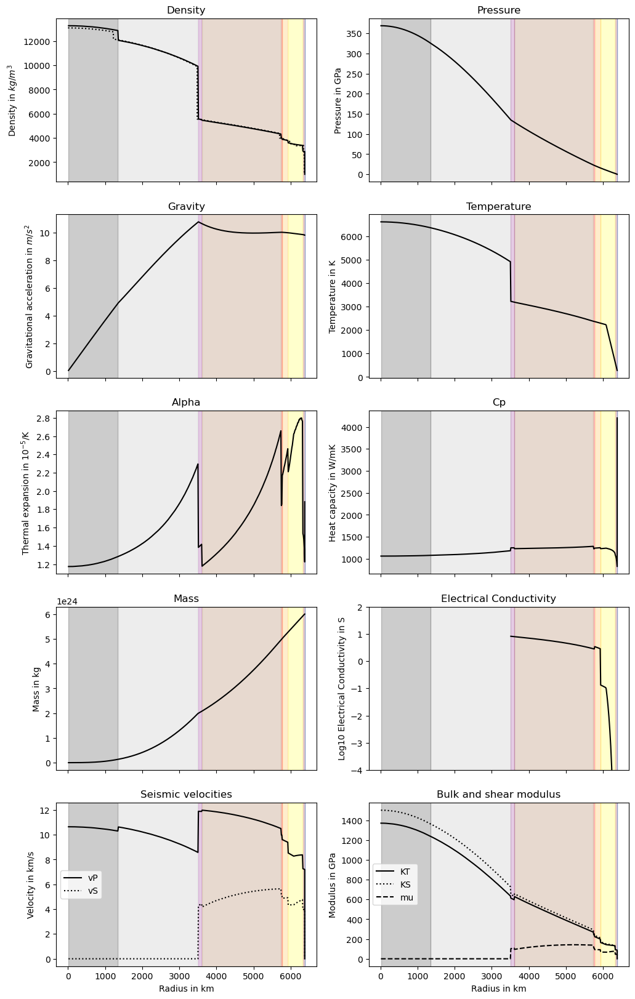

In [10]:
M=1; x_Fe_tot=38; x_H2O_tot=0.023
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)


1.0000 Earth masses with 38.50% iron leads to planet radius 0.9999 (6370 km) with MOI factor 0.330


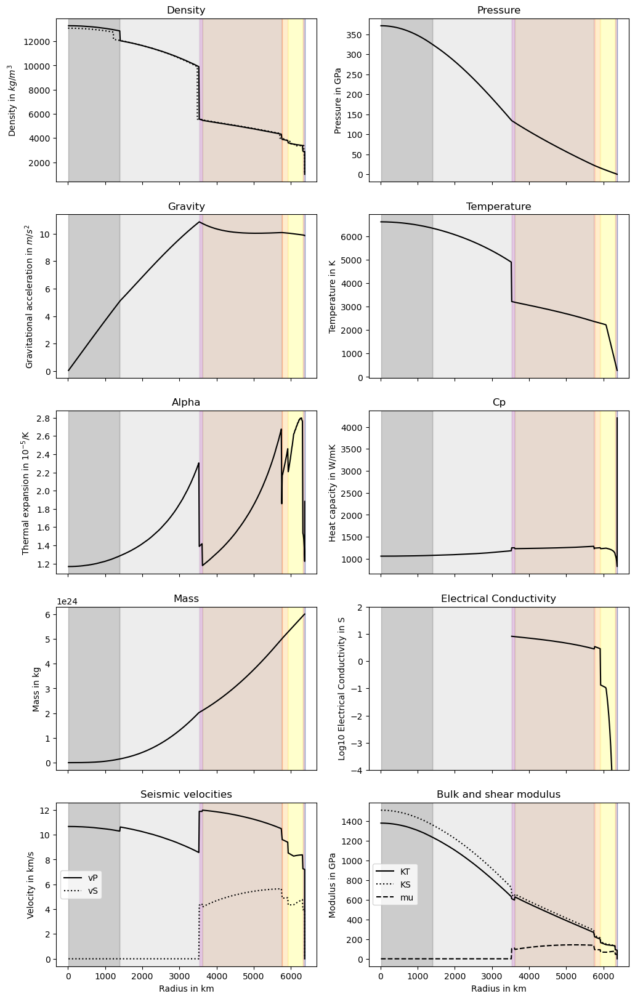

In [11]:
M=1; x_Fe_tot=38.5; x_H2O_tot=0.02
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(M,x_Fe_tot,x_H2O_tot, T_p, P_p)
#print(radius)
print('\n{0:6.4f} Earth masses with {1:5.2f}% iron leads to planet radius {2:6.4f} ({3:d} km) with MOI factor {4:5.3f}'
     .format(M,x_Fe_tot,Rp_E,int(Rp_E*6371),MOI))

visualization_earth(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

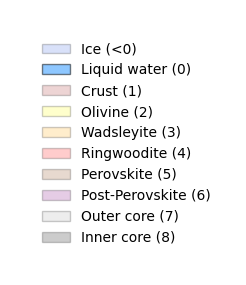

# Optimized likelihood function for estimating Fe and H2O using grid search in the ROWS model.

In [31]:
def grid_search_rows(mass_obs, radius_obs, t, P, 
                     mass_err, radius_err, 
                     fe_range=(10, 70, 5), h2o_range=(0, 90, 5)):
    """
    Grid search - much faster than continuous optimization

    Parameters:

    ----------
    mass_obs : float - observed mass in M_Earth
    radius_obs : float - observed radius in R_Earth
    mass_err : float - uncertainty in mass in M_Earth
    radius_err : float - uncertainty in radius in R_Earth
    fe_range : tuple (min, max, step) - range for Fe in wt%
    h2o_range : tuple (min, max, step) - range for H2O in wt%

    Returns:

    --------
    best_Fe, best_H2O : best values found
    results : dictionary with all search results
    """
  
    fe_values = np.arange(*fe_range)
    h2o_values = np.arange(*h2o_range)
    
    best_err2 = np.inf
    best_Fe = None
    best_H2O = None
    
    results = []
    
    total = len(fe_values) * len(h2o_values)
    count = 0
    
    print(f"Testing {total} combinations.")
    
    early_stop = False
    
    for fe in fe_values:
        if early_stop:
            break
            
        for h2o in h2o_values:
            count += 1
            
            try:
                # Rotate ROWS model
                Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, fe, h2o, t, P)
                
                model_radius = Rp_E
                model_mass = mass[-1]/M_t  
                
                # Calculate the chi-square test to check the model's fit to the data.
                err2 = np.sqrt(((model_radius - radius_obs) / radius_obs)**2 + ((model_mass - mass_obs) / mass_obs)**2)
                
                results.append({
                    'Fe': fe,
                    'H2O': h2o,
                    'err2': err2,
                    'radius': model_radius,
                    'mass': mass_obs
                })
                
                if err2 < best_err2:
                    best_err2 = err2
                    best_Fe = fe
                    best_H2O = h2o
                    
                    # Stopping condition: if err2 < 0.015, we have already found an excellent fit.
                    if best_err2 < 0.015:
                        print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.2f} Excellent fit")
                        early_stop = True
                        break
                
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f}")
                
            except Exception as e:
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> ERRO: {e}")
    
    # Check if any valid results were found.
    if best_Fe is None or best_H2O is None:
        print(f"\n=== No valid match found. ===")
        return None, None, results
    
    print(f"\n=== Best fit ===")
    print(f"x_Fe_tot = {best_Fe:.4f} wt%")
    print(f"x_H2O_tot = {best_H2O:.4f} wt%")
    print(f"Combined relative error mínimo = {best_err2:.4f}")
    
    if early_stop:
        print(f"(Search interrupted - excellent fit found)")
    
    return best_Fe, best_H2O, results



def grid_search_rows2(mass_obs, radius_obs, t, P, 
                     mass_err_obs, radius_err_obs, 
                     fe_range=(10, 70, 5), h2o_range=(0, 90, 5), condition=-1):
    """
    Grid search 2

    Parameters:

    ----------
    mass_obs : float - observed mass in M_Earth
    radius_obs : float - observed radius in R_Earth
    mass_err : float - uncertainty in mass in M_Earth
    radius_err : float - uncertainty in radius in R_Earth
    fe_range : tuple (min, max, step) - range for Fe in wt%
    h2o_range : tuple (min, max, step) - range for H2O in wt%

    Returns:

    --------
    best_Fe, best_H2O : best values found
    results : dictionary with all search results
    """
    fe_values = np.arange(*fe_range)
    h2o_values = np.arange(*h2o_range)

    best_err2 = np.inf
    best_Fe = None
    best_H2O = None

    results = []

    total = len(fe_values) * len(h2o_values)
    count = 0

    print(f"Testing {total} combinations.")
    # I will obtain the best value for the percentage of iron and water, and then test the variation for water with this fixed iron value.
    fe_locked = False
    locked_fe_value = None

    for fe in fe_values:
        # If the iron has already been locked, break
        if fe_locked and fe != locked_fe_value:
            break

        for h2o in h2o_values:

            count += 1

            try:

                Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, fe, h2o, t, P)

                model_radius = Rp_E
                model_mass = mass[-1]/M_t  
                
                # Calculate the  test to check the model's fit to the data.
                err2 =np.sqrt(((model_radius - radius_obs) / radius_obs)**2 + ((model_mass - mass_obs) / mass_obs)**2)

                results.append({
                    'Fe': fe,
                    'H2O': h2o,
                    'err2': err2,
                    'radius': model_radius,
                    'mass': mass_obs
                })

                if err2 < best_err2:
                    best_err2 = err2
                    best_Fe = fe
                    best_H2O = h2o

                # Upon reaching the desired condition, freeze the iron percentage and test the other water values, seeking the best correlation.
                if (err2 < condition) and not fe_locked:
                    fe_locked = True
                    locked_fe_value = fe
                    print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.4f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f} Fe FIXED")

                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> R={model_radius:.3f} R_E, M={model_mass:.4f} M_E, Combined relative error={err2:.4f}")

            except Exception as e:
                print(f"[{count}/{total}] Fe={fe}, H2O={h2o} -> ERRO: {e}")
                continue

        # After testing all H2O with locked iron, break
        if fe_locked:
            break

    if best_Fe is None or best_H2O is None:
        print(f"\n=== No valid match found. ===")
        return None, None, results

    print(f"\n=== Best fit ===")
    print(f"x_Fe_tot = {best_Fe:.4f} wt%")
    print(f"x_H2O_tot = {best_H2O:.4f} wt%")
    print(f"Combined relative error mínimo = {best_err2:.4f}")

    if fe_locked:
        print("(Search finished after fixing Fe and scanning H2O)")

    return best_Fe, best_H2O, results

    
def refine_search(mass_obs, radius_obs, 
                  initial_Fe, initial_H2O, t, P,mass_err, radius_err,
                  delta_Fe=10, delta_H2O=10,
                  step_Fe=1, step_H2O=1):
    """
    Refinement around the best grid search result

    Parameters:

    -----------
    mass_obs: float - observed mass on M_Earth
    radius_obs: float - observed radius on R_Earth
    initial_Fe, initial_H2O: initial values of the coarse search
    mass_err: float - uncertainty in mass
    radius_err: float - uncertainty in radius
    delta_Fe: float - range of +/- around the initial Fe
    delta_H2O: float - range of +/- around the initial H2O
    step_Fe: float - fine-grained search step for Fe
    step_H2O: float - fine-grained search step for H2O
    """
    
    # Check if the initial values are valid
    if initial_Fe is None or initial_H2O is None:
        print("ERROR: Invalid initial values for refinement.")
        return None, None, []
    
        # Ensure valid Fe window/step (the message prints the value actually used)
    if step_Fe <= 0:
        step_Fe = 0.25
        print(f"WARNING: invalid step_Fe, using {step_Fe}")
    if delta_Fe <= 0:
        delta_Fe = 5
        print(f"WARNING: invalid delta_Fe, using {delta_Fe}")

    # Water window proportional to the starting value (overrides the delta_H2O/step_H2O arguments):
    #   H2O = 0  -> searches 0 to 0.25 (step 0.05)
    #   H2O = 10 -> searches ~8.5 to ~11.8 (step 0.3)
    delta_H2O = max(0.25, 0.15 * initial_H2O)
    step_H2O = delta_H2O / 10

    fe_range = (max(0, initial_Fe - delta_Fe),
                min(100, initial_Fe + delta_Fe + step_Fe),
                step_Fe)
    h2o_range = (max(0, initial_H2O - delta_H2O),
                 min(100, initial_H2O + delta_H2O + step_H2O),
                 step_H2O)
    
    print(f"\n=== REFINEMENT ===") 
    print(f"Searching around Fe={initial_Fe:.4f}, H2O={initial_H2O:.4f}") 
    print(f"Range Fe: {fe_range[0]:.4f} to {fe_range[1]-step_Fe:.4f} (step={fe_range[2]:.4f})") 
    print(f"Range H2O: {h2o_range[0]:.4f} to {h2o_range[1]-step_H2O:.4f} (step={h2o_range[2]:.4f})")
    
    # Calculate the number of combinations.
    n_fe = len(np.arange(*fe_range))
    n_h2o = len(np.arange(*h2o_range))
    print(f"Total number of combinations: {n_fe} × {n_h2o} = {n_fe * n_h2o}")

    return grid_search_rows2(mass_obs, radius_obs, t, P, mass_err, radius_err, fe_range, h2o_range)

# Terra

STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.065 R_E, M=1.0036 M_E, χ²=0.0648
[2/216] Fe=10, H2O=5 -> R=1.098 R_E, M=1.0072 M_E, χ²=0.0979
[3/216] Fe=10, H2O=10 -> R=1.119 R_E, M=1.0070 M_E, χ²=0.1188
[4/216] Fe=10, H2O=15 -> R=1.137 R_E, M=1.0070 M_E, χ²=0.1371
[5/216] Fe=10, H2O=20 -> R=1.156 R_E, M=1.0070 M_E, χ²=0.1557
[6/216] Fe=10, H2O=25 -> R=1.172 R_E, M=1.0070 M_E, χ²=0.1725
[7/216] Fe=10, H2O=30 -> R=1.188 R_E, M=1.0070 M_E, χ²=0.1882
[8/216] Fe=10, H2O=35 -> R=1.202 R_E, M=1.0070 M_E, χ²=0.2021
[9/216] Fe=10, H2O=40 -> R=1.217 R_E, M=1.0070 M_E, χ²=0.2168
[10/216] Fe=10, H2O=45 -> R=1.231 R_E, M=1.0069 M_E, χ²=0.2307
[11/216] Fe=10, H2O=50 -> R=1.244 R_E, M=1.0069 M_E, χ²=0.2441
[12/216] Fe=10, H2O=55 -> R=1.257 R_E, M=1.0068 M_E, χ²=0.2569
[13/216] Fe=10, H2O=60 -> R=1.269 R_E, M=1.0067 M_E, χ²=0.2688
[14/216] Fe=10, H2O=65 -> R=1.281 R_E, M=1.0066 M_E, χ²=0.2806
[15/216] Fe=10, H2O=70 -> R=1.292 R_E, M=1.0064 M_E, χ²=0.2922
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.020 R_E, M=1.0052 M_E, χ²=0.0208
[74/216] Fe=30, H2O=5 -> R=1.054 R_E, M=1.0082 M_E, χ²=0.0549
[75/216] Fe=30, H2O=10 -> R=1.076 R_E, M=1.0081 M_E, χ²=0.0762
[76/216] Fe=30, H2O=15 -> R=1.096 R_E, M=1.0082 M_E, χ²=0.0965
[77/216] Fe=30, H2O=20 -> R=1.115 R_E, M=1.0082 M_E, χ²=0.1151
[78/216] Fe=30, H2O=25 -> R=1.132 R_E, M=1.0082 M_E, χ²=0.1318
[79/216] Fe=30, H2O=30 -> R=1.147 R_E, M=1.0083 M_E, χ²=0.1472
[80/216] Fe=30, H2O=35 -> R=1.163 R_E, M=1.0083 M_E, χ²=0.1628
[81/216] Fe=30, H2O=40 -> R=1.177 R_E, M=1.0082 M_E, χ²=0.1772
[82/216] Fe=30, H2O=45 -> R=1.191 R_E, M=1.0082 M_E, χ²=0.1909
[83/216] Fe=30, H2O=50 -> R=1.203 R_E, M=1.0081 M_E, χ²=0.2036
[84/216] Fe=30, H2O=55 -> R=1.216 R_E, M=1.0080 M_E, χ²=0.2161
[85/216] Fe=30, H2O=60 -> R=1.228 R_E, M=1.0078 M_E, χ²=0.2283
[86/216] Fe=30, H2O=65 -> R=1.240 R_E, M=1.0076 M_E, χ²=0.2403
[87/216] Fe=30, H2O=70 -> R=1.251 R_E, M=1.0072 M_E, χ²=0.2507
[88/216] Fe=30, H2O=75 -> R=1.276 R_E, M=0.9402 M_E, χ²=0

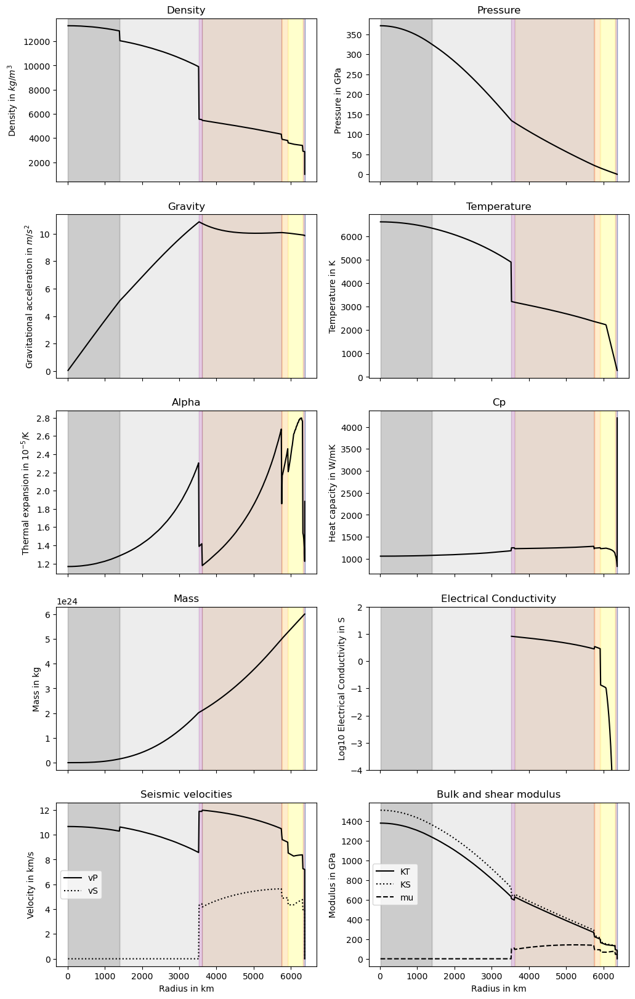

In [40]:
# To  terra 
T_p=temp_pla2(T_sol, r_s, 1.0); P_p=pressao(P_t, M_t, M_t, R_t, R_t, 3)
if __name__ == "__main__":
    mass_obs = 1.00
    mass_err=0.0001
    radius_obs = 1.00
    radius_err=0.0011
    temp_obs = T_p
    P_p=P_p
    # STEP 1: Coarse search (quick - few points)
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 
    
    # STEP 2: Refinement (around the best)
    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 38.5, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [10]:
T_p=temp_pla2(T_sol, r_s, 1.0); P_p=pressao(P_t, M_t, M_t, R_t, R_t, 3)

mass_obs = 1.00
mass_err=0.0001
radius_obs = 1.00
radius_err=0.0011
temp_obs = T_p
P_p=P_p

4896.620814628851 3213.4410291049194 2109567.7836663276 11145.459057012808 1119.0121138799182 4896.620814628851


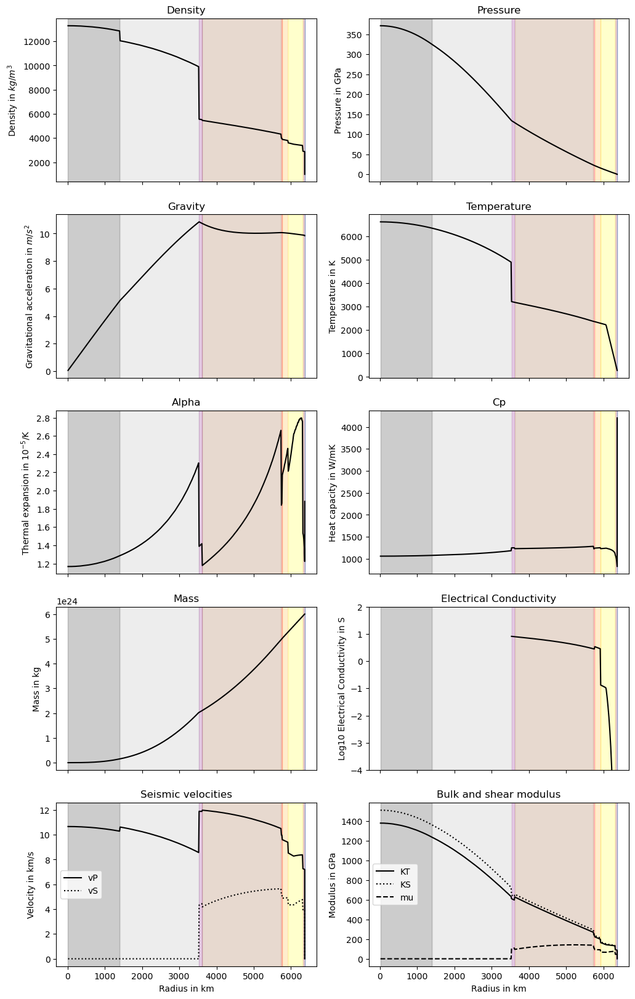

In [11]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 38.5, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

# APPLICATION FOR OTHER TERRESTRIAL OR SUPERTERRANEAN TYPE EXOPLANTS

STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.089 R_E, M=1.0839 M_E, χ²=0.0569
[2/216] Fe=10, H2O=5 -> R=1.123 R_E, M=1.0878 M_E, χ²=0.0903
[3/216] Fe=10, H2O=10 -> R=1.144 R_E, M=1.0876 M_E, χ²=0.1106
[4/216] Fe=10, H2O=15 -> R=1.163 R_E, M=1.0876 M_E, χ²=0.1293
[5/216] Fe=10, H2O=20 -> R=1.182 R_E, M=1.0876 M_E, χ²=0.1475
[6/216] Fe=10, H2O=25 -> R=1.199 R_E, M=1.0876 M_E, χ²=0.1642
[7/216] Fe=10, H2O=30 -> R=1.214 R_E, M=1.0876 M_E, χ²=0.1788
[8/216] Fe=10, H2O=35 -> R=1.229 R_E, M=1.0876 M_E, χ²=0.1936
[9/216] Fe=10, H2O=40 -> R=1.244 R_E, M=1.0875 M_E, χ²=0.2079
[10/216] Fe=10, H2O=45 -> R=1.258 R_E, M=1.0875 M_E, χ²=0.2216
[11/216] Fe=10, H2O=50 -> R=1.272 R_E, M=1.0874 M_E, χ²=0.2348
[12/216] Fe=10, H2O=55 -> R=1.284 R_E, M=1.0874 M_E, χ²=0.2469
[13/216] Fe=10, H2O=60 -> R=1.296 R_E, M=1.0873 M_E, χ²=0.2587
[14/216] Fe=10, H2O=65 -> R=1.308 R_E, M=1.0871 M_E, χ²=0.2703
[15/216] Fe=10, H2O=70 -> R=1.320 R_E, M=1.0870 M_E, χ²=0.2818
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.043 R_E, M=1.0857 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0134
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 27.0000 to 33.0000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 5 × 11 = 55
Testing 55 combinations.
[1/55] Fe=27.0, H2O=0.0 -> R=1.050 R_E, M=1.0855 M_E, χ²=0.0198
[2/55] Fe=27.0, H2O=0.025 -> R=1.049 R_E, M=1.0852 M_E, χ²=0.0191
[3/55] Fe=27.0, H2O=0.05 -> R=1.049 R_E, M=1.0849 M_E, χ²=0.0189
[4/55] Fe=27.0, H2O=0.07500000000000001 -> R=1.049 R_E, M=1.0847 M_E, χ²=0.0188
[5/55] Fe=27.0, H2O=0.1 -> R=1.049 R_E, M=1.0844 M_E, χ²=0.0187
[6/55] Fe=27.0, H2O=0.125 -> R=1.049 R_E, M=1.0841 M_E, χ²=0.0185
[7/55] Fe=27.0, H2O=0.15000000000000002 -> R=1.052 R_E, M=1.0883 M_E, χ²=0.0227
[8/55] Fe=27.0, H2O=0.17500000000000002 -> R=1.052 R_E, M=1.0888 M_E, χ²=0.0233
[9

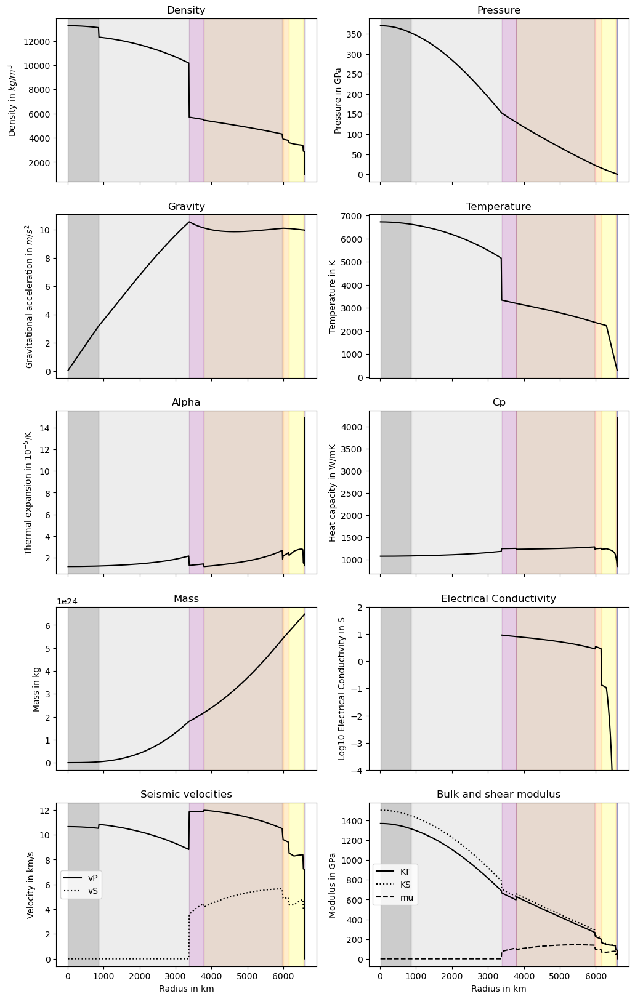

In [44]:
# To  GJ1002 b
if __name__ == "__main__":
    mass_obs = 1.08 
    mass_err=0.13
    radius_obs = 1.03
    radius_err=0.2*radius_obs
    temp_obs = 288
    P_p=1.05*10**5
    
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.1*best_Fe, delta_H2O=0.1*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  


    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [12]:
mass_obs = 1.08 
radius_obs = 1.03
temp_obs = 288
P_p=1.05*10**5

In [13]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

0.13288981803696975
0.5128716414864293
11482.89213944592
5152.454318660663 3334.9987046439187 2496268.9301872877 11482.89213944592 1118.6963792855427 5152.454318660663


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.162 R_E, M=1.3650 M_E, χ²=0.0569
[2/216] Fe=10, H2O=5 -> R=1.197 R_E, M=1.3697 M_E, χ²=0.0880
[3/216] Fe=10, H2O=10 -> R=1.219 R_E, M=1.3695 M_E, χ²=0.1085
[4/216] Fe=10, H2O=15 -> R=1.240 R_E, M=1.3695 M_E, χ²=0.1278
[5/216] Fe=10, H2O=20 -> R=1.260 R_E, M=1.3695 M_E, χ²=0.1453
[6/216] Fe=10, H2O=25 -> R=1.276 R_E, M=1.3695 M_E, χ²=0.1600
[7/216] Fe=10, H2O=30 -> R=1.293 R_E, M=1.3695 M_E, χ²=0.1756
[8/216] Fe=10, H2O=35 -> R=1.309 R_E, M=1.3695 M_E, χ²=0.1901
[9/216] Fe=10, H2O=40 -> R=1.324 R_E, M=1.3694 M_E, χ²=0.2038
[10/216] Fe=10, H2O=45 -> R=1.338 R_E, M=1.3694 M_E, χ²=0.2169
[11/216] Fe=10, H2O=50 -> R=1.352 R_E, M=1.3693 M_E, χ²=0.2290
[12/216] Fe=10, H2O=55 -> R=1.365 R_E, M=1.3692 M_E, χ²=0.2409
[13/216] Fe=10, H2O=60 -> R=1.378 R_E, M=1.3691 M_E, χ²=0.2526
[14/216] Fe=10, H2O=65 -> R=1.390 R_E, M=1.3689 M_E, χ²=0.2641
[15/216] Fe=10, H2O=70 -> R=1.403 R_E, M=1.3687 M_E, χ²=0.2753
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.113 R_E, M=1.3672 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0131
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 27.0000 to 33.0000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 5 × 11 = 55
Testing 55 combinations.
[1/55] Fe=27.0, H2O=0.0 -> R=1.121 R_E, M=1.3669 M_E, χ²=0.0195
[2/55] Fe=27.0, H2O=0.025 -> R=1.120 R_E, M=1.3666 M_E, χ²=0.0187
[3/55] Fe=27.0, H2O=0.05 -> R=1.120 R_E, M=1.3663 M_E, χ²=0.0185
[4/55] Fe=27.0, H2O=0.07500000000000001 -> R=1.120 R_E, M=1.3659 M_E, χ²=0.0184
[5/55] Fe=27.0, H2O=0.1 -> R=1.120 R_E, M=1.3656 M_E, χ²=0.0183
[6/55] Fe=27.0, H2O=0.125 -> R=1.119 R_E, M=1.3652 M_E, χ²=0.0181
[7/55] Fe=27.0, H2O=0.15000000000000002 -> R=1.124 R_E, M=1.3711 M_E, χ²=0.0230
[8/55] Fe=27.0, H2O=0.17500000000000002 -> R=1.124 R_E, M=1.3718 M_E, χ²=0.0237
[9

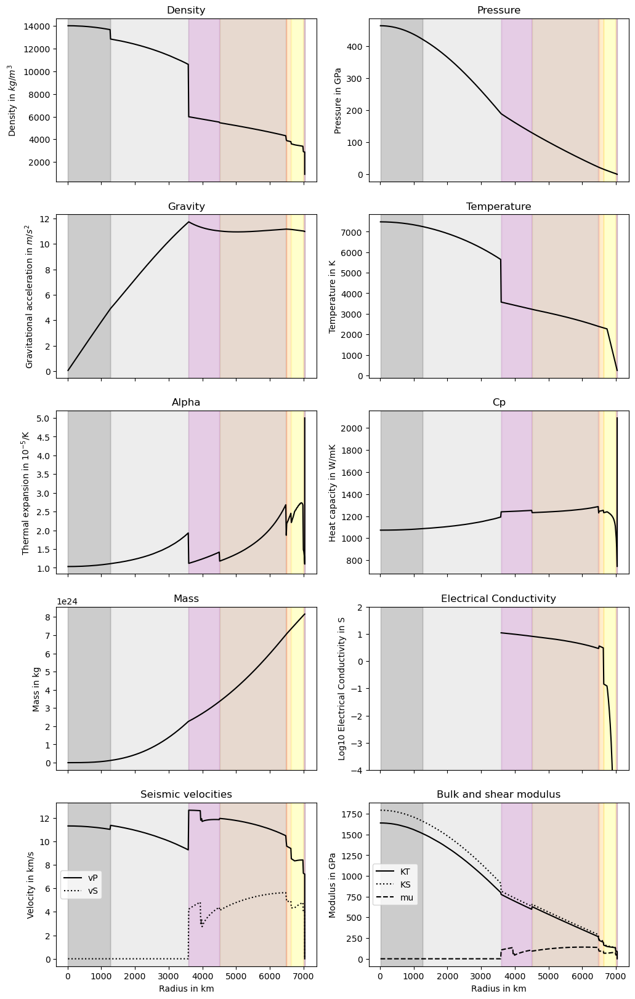

In [46]:
# To  GJ 1002 C
if __name__ == "__main__":
    mass_obs = 1.36
    radius_obs = 1.1
    temp_obs = 242
    P_p=1.28*10**5
    
    mass_err=0.17
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.1*best_Fe, delta_H2O=0.1*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  


Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [14]:
mass_obs = 1.36
radius_obs = 1.1
temp_obs = 242
P_p=1.28*10**5

In [15]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5647.774895247234 3570.309658900427 2305045.555585765 11916.286658502717 1126.6734796135206 5647.774895247234


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.246 R_E, M=1.7464 M_E, χ²=0.0561
[2/216] Fe=10, H2O=5 -> R=1.288 R_E, M=1.7533 M_E, χ²=0.0920
[3/216] Fe=10, H2O=10 -> R=1.312 R_E, M=1.7527 M_E, χ²=0.1124
[4/216] Fe=10, H2O=15 -> R=1.335 R_E, M=1.7525 M_E, χ²=0.1318
[5/216] Fe=10, H2O=20 -> R=1.354 R_E, M=1.7524 M_E, χ²=0.1478
[6/216] Fe=10, H2O=25 -> R=1.373 R_E, M=1.7524 M_E, χ²=0.1641
[7/216] Fe=10, H2O=30 -> R=1.391 R_E, M=1.7523 M_E, χ²=0.1793
[8/216] Fe=10, H2O=35 -> R=1.407 R_E, M=1.7523 M_E, χ²=0.1928
[9/216] Fe=10, H2O=40 -> R=1.422 R_E, M=1.7522 M_E, χ²=0.2055
[10/216] Fe=10, H2O=45 -> R=1.437 R_E, M=1.7521 M_E, χ²=0.2179
[11/216] Fe=10, H2O=50 -> R=1.451 R_E, M=1.7520 M_E, χ²=0.2299
[12/216] Fe=10, H2O=55 -> R=1.465 R_E, M=1.7519 M_E, χ²=0.2418
[13/216] Fe=10, H2O=60 -> R=1.479 R_E, M=1.7517 M_E, χ²=0.2535
[14/216] Fe=10, H2O=65 -> R=1.493 R_E, M=1.7515 M_E, χ²=0.2650
[15/216] Fe=10, H2O=70 -> R=1.506 R_E, M=1.7513 M_E, χ²=0.2764
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.193 R_E, M=1.7493 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0121
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 27.0000 to 33.0000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 5 × 11 = 55
Testing 55 combinations.
[1/55] Fe=27.0, H2O=0.0 -> R=1.201 R_E, M=1.7490 M_E, χ²=0.0184
[2/55] Fe=27.0, H2O=0.025 -> R=1.200 R_E, M=1.7486 M_E, χ²=0.0176
[3/55] Fe=27.0, H2O=0.05 -> R=1.200 R_E, M=1.7481 M_E, χ²=0.0174
[4/55] Fe=27.0, H2O=0.07500000000000001 -> R=1.200 R_E, M=1.7477 M_E, χ²=0.0173
[5/55] Fe=27.0, H2O=0.1 -> R=1.200 R_E, M=1.7472 M_E, χ²=0.0171
[6/55] Fe=27.0, H2O=0.125 -> R=1.200 R_E, M=1.7468 M_E, χ²=0.0170
[7/55] Fe=27.0, H2O=0.15000000000000002 -> R=1.204 R_E, M=1.7542 M_E, χ²=0.0218
[8/55] Fe=27.0, H2O=0.17500000000000002 -> R=1.204 R_E, M=1.7551 M_E, χ²=0.0225
[9

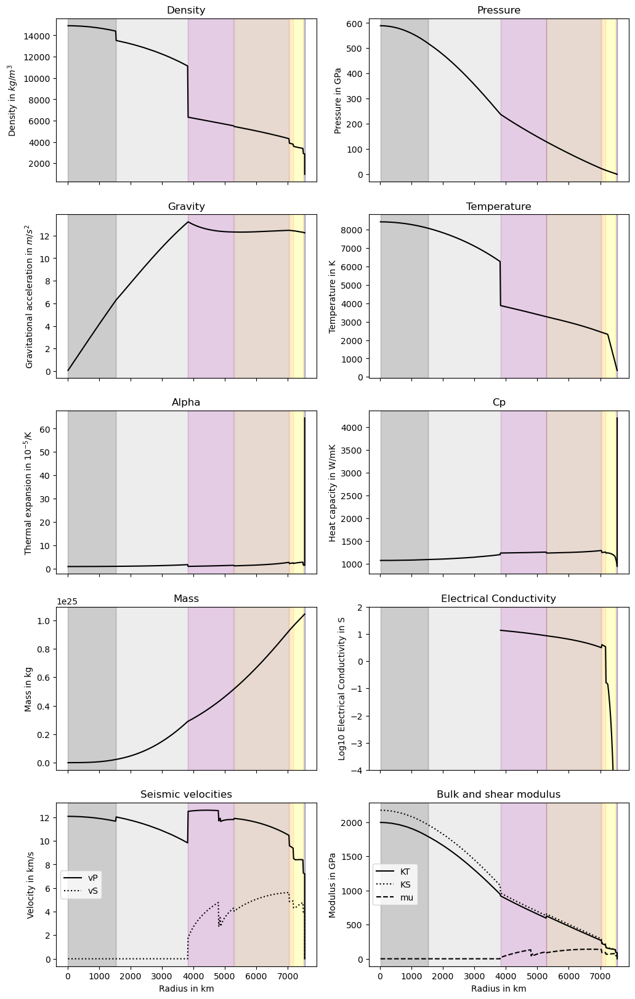

In [49]:
# To  GJ 1061 C
if __name__ == "__main__":
    mass_obs = 1.74
    radius_obs = 1.18
    temp_obs = 354
    P_p=1.58*10**5
    mass_err=0.13
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.1*best_Fe, delta_H2O=0.1*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [16]:
mass_obs = 1.74
radius_obs = 1.18
temp_obs = 354
P_p=1.58*10**5

In [17]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

6273.681386349028 3880.422218814487 2271525.1679143477 12507.696659159767 1132.3448625782255 6273.681386349028


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.226 R_E, M=1.6460 M_E, χ²=0.0566
[2/216] Fe=10, H2O=5 -> R=1.263 R_E, M=1.6520 M_E, χ²=0.0889
[3/216] Fe=10, H2O=10 -> R=1.287 R_E, M=1.6517 M_E, χ²=0.1100
[4/216] Fe=10, H2O=15 -> R=1.309 R_E, M=1.6516 M_E, χ²=0.1291
[5/216] Fe=10, H2O=20 -> R=1.329 R_E, M=1.6516 M_E, χ²=0.1455
[6/216] Fe=10, H2O=25 -> R=1.347 R_E, M=1.6516 M_E, χ²=0.1614
[7/216] Fe=10, H2O=30 -> R=1.365 R_E, M=1.6515 M_E, χ²=0.1765
[8/216] Fe=10, H2O=35 -> R=1.381 R_E, M=1.6515 M_E, χ²=0.1904
[9/216] Fe=10, H2O=40 -> R=1.395 R_E, M=1.6514 M_E, χ²=0.2030
[10/216] Fe=10, H2O=45 -> R=1.410 R_E, M=1.6513 M_E, χ²=0.2153
[11/216] Fe=10, H2O=50 -> R=1.424 R_E, M=1.6513 M_E, χ²=0.2273
[12/216] Fe=10, H2O=55 -> R=1.437 R_E, M=1.6511 M_E, χ²=0.2392
[13/216] Fe=10, H2O=60 -> R=1.451 R_E, M=1.6510 M_E, χ²=0.2508
[14/216] Fe=10, H2O=65 -> R=1.464 R_E, M=1.6508 M_E, χ²=0.2623
[15/216] Fe=10, H2O=70 -> R=1.477 R_E, M=1.6506 M_E, χ²=0.2736
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.173 R_E, M=1.6487 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0125
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.185 R_E, M=1.6483 M_E, χ²=0.0223
[2/77] Fe=25.5, H2O=0.025 -> R=1.184 R_E, M=1.6479 M_E, χ²=0.0215
[3/77] Fe=25.5, H2O=0.05 -> R=1.184 R_E, M=1.6475 M_E, χ²=0.0213
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.184 R_E, M=1.6471 M_E, χ²=0.0212
[5/77] Fe=25.5, H2O=0.1 -> R=1.184 R_E, M=1.6466 M_E, χ²=0.0211
[6/77] Fe=25.5, H2O=0.125 -> R=1.184 R_E, M=1.6462 M_E, χ²=0.0209
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.188 R_E, M=1.6530 M_E, χ²=0.0253
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.188 R_E, M=1.6538 M_E, χ²=0.0259
[9

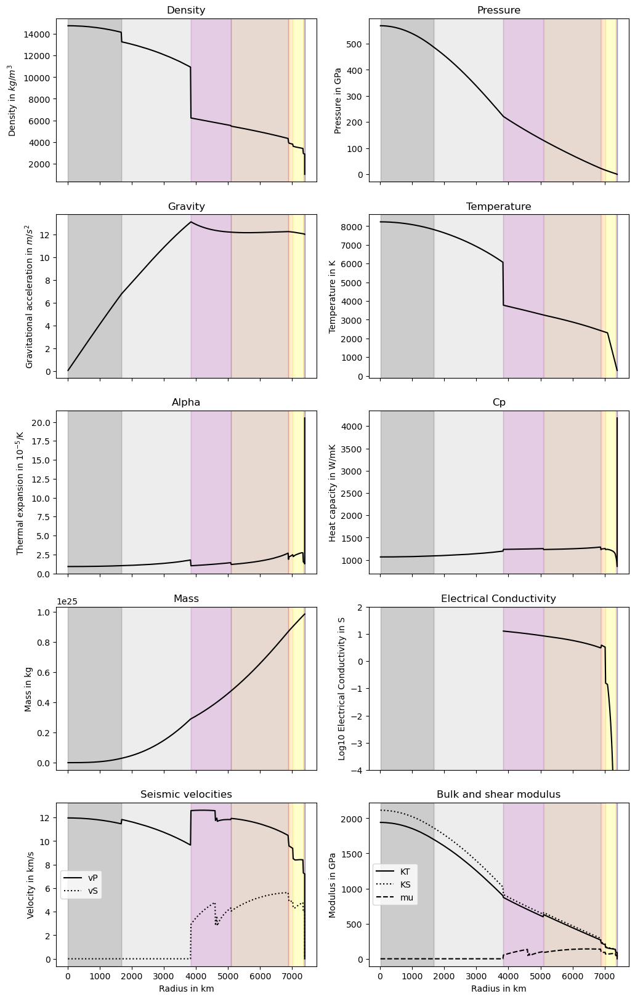

In [52]:
# To GJ 1061 D
if __name__ == "__main__":
    mass_obs = 1.64
    radius_obs = 1.16
    temp_obs = 293
    
    P_p=1.51*10**5
    mass_err=0.21
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [18]:
mass_obs = 1.64
radius_obs = 1.16
temp_obs = 293
    
P_p=1.51*10**5

In [19]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.40, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

6074.636360513052 3778.954572759573 2155686.4588058908 12285.026858992416 1131.7871043830744 6074.636360513052


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.433 R_E, M=2.9007 M_E, χ²=0.0514
[2/216] Fe=10, H2O=5 -> R=1.478 R_E, M=2.9120 M_E, χ²=0.0224
[3/216] Fe=10, H2O=10 -> R=1.508 R_E, M=2.9112 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 10.0000 wt%
χ² mínimo = 0.0075
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=10.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 8.5000 to 11.5000 (step=0.1500)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=8.5 -> R=1.504 R_E, M=2.9107 M_E, χ²=0.0082
[2/154] Fe=8.5, H2O=8.65 -> R=1.505 R_E, M=2.9107 M_E, χ²=0.0080
[3/154] Fe=8.5, H2O=8.8 -> R=1.506 R_E, M=2.9106 M_E, χ²=0.0077
[4/154] Fe=8.5, H2O=8.950000000000001 -> R=1.506 R_E, M=2.9108 M_E, χ²=0.0076
[5/154] Fe=8.5, H2O=9.100000000000001 -> R=1.507 R_E, M=2.9107 M_E, χ²=0.0074
[6/154] Fe=8.5, H2O=9.250000000000002 -> R=1

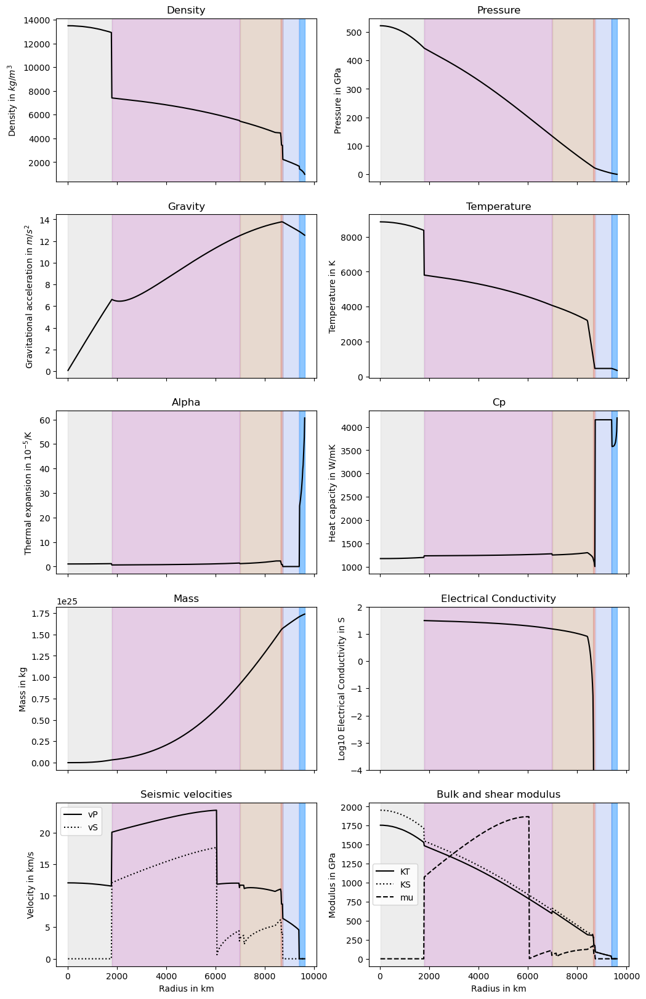

In [55]:
# To  GJ 273 B
if __name__ == "__main__":
    mass_obs = 2.89
    radius_obs = 1.51
    temp_obs = 347
    
    P_p=1.63*10**5
    mass_err=0.27
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [20]:
mass_obs = 2.89
radius_obs = 1.51
temp_obs = 347
    
P_p=1.63*10**5

In [22]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 9.7, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8375.73051722814 5807.328804807673 1779106.8772141684 13316.152627153106 1180.4332207924408 8375.73051722814


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.299 R_E, M=2.0274 M_E, χ²=0.0563
[2/216] Fe=10, H2O=5 -> R=1.341 R_E, M=2.0353 M_E, χ²=0.0908
[3/216] Fe=10, H2O=10 -> R=1.368 R_E, M=2.0347 M_E, χ²=0.1120
[4/216] Fe=10, H2O=15 -> R=1.391 R_E, M=2.0345 M_E, χ²=0.1308
[5/216] Fe=10, H2O=20 -> R=1.411 R_E, M=2.0344 M_E, χ²=0.1471
[6/216] Fe=10, H2O=25 -> R=1.430 R_E, M=2.0344 M_E, χ²=0.1629
[7/216] Fe=10, H2O=30 -> R=1.448 R_E, M=2.0343 M_E, χ²=0.1771
[8/216] Fe=10, H2O=35 -> R=1.464 R_E, M=2.0342 M_E, χ²=0.1903
[9/216] Fe=10, H2O=40 -> R=1.479 R_E, M=2.0342 M_E, χ²=0.2030
[10/216] Fe=10, H2O=45 -> R=1.495 R_E, M=2.0341 M_E, χ²=0.2152
[11/216] Fe=10, H2O=50 -> R=1.509 R_E, M=2.0340 M_E, χ²=0.2272
[12/216] Fe=10, H2O=55 -> R=1.524 R_E, M=2.0338 M_E, χ²=0.2390
[13/216] Fe=10, H2O=60 -> R=1.538 R_E, M=2.0336 M_E, χ²=0.2507
[14/216] Fe=10, H2O=65 -> R=1.552 R_E, M=2.0334 M_E, χ²=0.2622
[15/216] Fe=10, H2O=70 -> R=1.566 R_E, M=2.0331 M_E, χ²=0.2734
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_3676\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.243 R_E, M=2.0309 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0118
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.256 R_E, M=2.0303 M_E, χ²=0.0216
[2/77] Fe=25.5, H2O=0.025 -> R=1.255 R_E, M=2.0298 M_E, χ²=0.0207
[3/77] Fe=25.5, H2O=0.05 -> R=1.255 R_E, M=2.0293 M_E, χ²=0.0206
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.255 R_E, M=2.0288 M_E, χ²=0.0204
[5/77] Fe=25.5, H2O=0.1 -> R=1.254 R_E, M=2.0283 M_E, χ²=0.0203
[6/77] Fe=25.5, H2O=0.125 -> R=1.254 R_E, M=2.0278 M_E, χ²=0.0201
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.259 R_E, M=2.0365 M_E, χ²=0.0249
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.260 R_E, M=2.0376 M_E, χ²=0.0255
[9

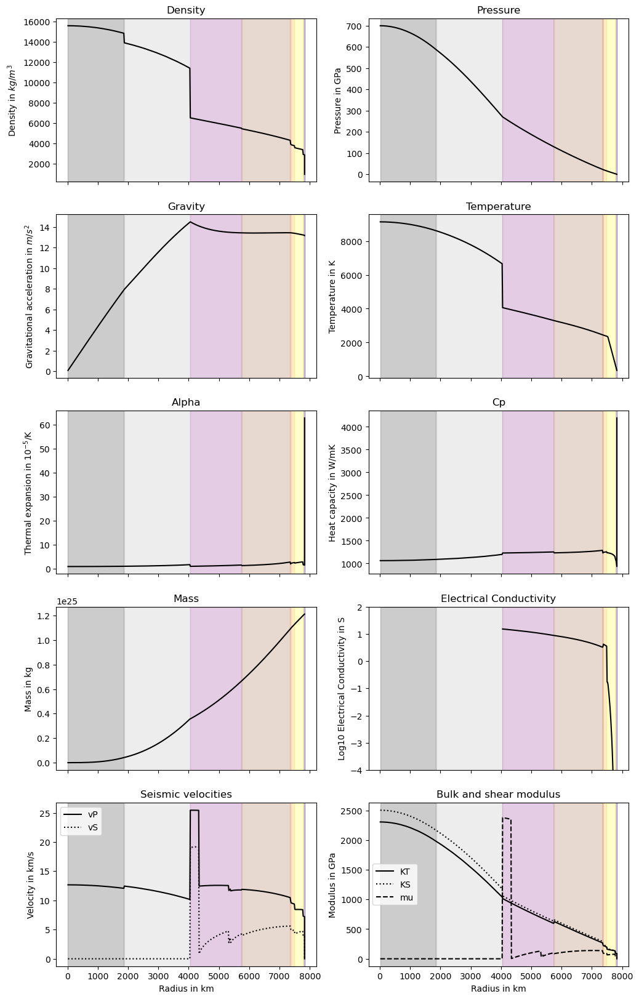

In [58]:
# To  GJ 3323 B
if __name__ == "__main__":
    mass_obs = 2.02
    radius_obs = 1.23
    temp_obs = 351
    
    P_p=1.81*10**5
    mass_err=0.26
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [23]:
mass_obs = 2.02
radius_obs = 1.23
temp_obs = 351
    
P_p=1.81*10**5

In [24]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,34.50 , 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

6655.606611064248 4060.9201801949275 2163873.3105170634 12840.110539487097 1134.549617278881 6655.606611064248


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.602 R_E, M=4.4166 M_E, χ²=0.1700
[2/216] Fe=10, H2O=5 -> R=1.653 R_E, M=4.4338 M_E, χ²=0.1439
[3/216] Fe=10, H2O=10 -> R=1.683 R_E, M=4.4325 M_E, χ²=0.1281
[4/216] Fe=10, H2O=15 -> R=1.710 R_E, M=4.4318 M_E, χ²=0.1145
[5/216] Fe=10, H2O=20 -> R=1.731 R_E, M=4.4316 M_E, χ²=0.1031
[6/216] Fe=10, H2O=25 -> R=1.752 R_E, M=4.4315 M_E, χ²=0.0925
[7/216] Fe=10, H2O=30 -> R=1.772 R_E, M=4.4314 M_E, χ²=0.0820
[8/216] Fe=10, H2O=35 -> R=1.792 R_E, M=4.4314 M_E, χ²=0.0720
[9/216] Fe=10, H2O=40 -> R=1.811 R_E, M=4.4313 M_E, χ²=0.0618
[10/216] Fe=10, H2O=45 -> R=1.831 R_E, M=4.4311 M_E, χ²=0.0520
[11/216] Fe=10, H2O=50 -> R=1.850 R_E, M=4.4308 M_E, χ²=0.0423
[12/216] Fe=10, H2O=55 -> R=1.868 R_E, M=4.4305 M_E, χ²=0.0328
[13/216] Fe=10, H2O=60 -> R=1.886 R_E, M=4.4301 M_E, χ²=0.0236
[14/216] Fe=10, H2O=65 -> R=1.905 R_E, M=4.4295 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 65.0000 wt%
χ² m

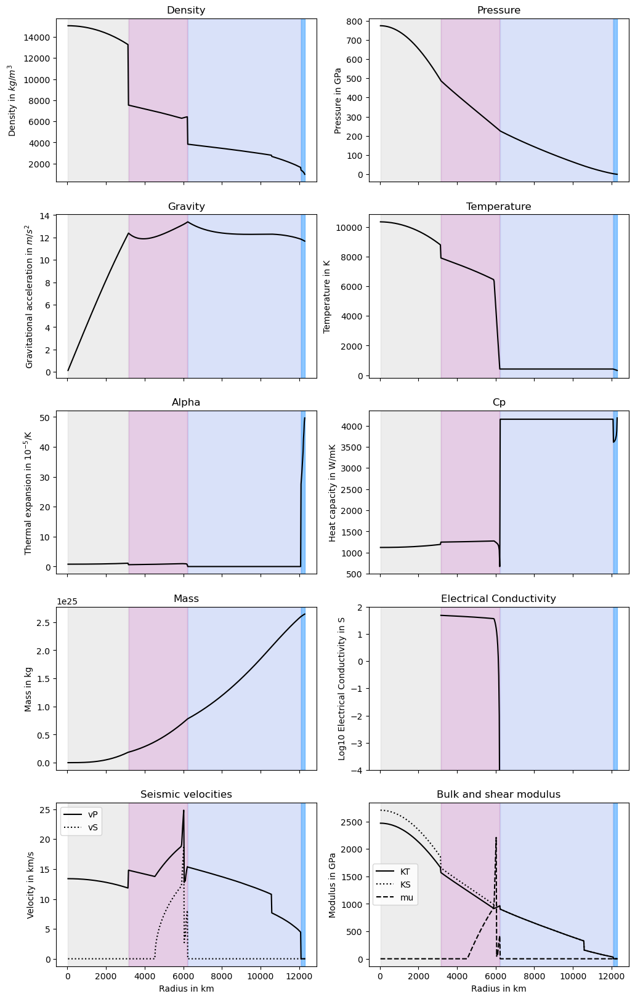

In [61]:
# To  GJ 682 B
if __name__ == "__main__":
    mass_obs = 4.4
    radius_obs = 1.93
    temp_obs = 329
    
    P_p=1.41*10**5
    mass_err=3.7
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [25]:
mass_obs = 4.4
radius_obs = 1.93
temp_obs = 329
    
P_p=1.41*10**5

In [26]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 70.85, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8787.924878285798 7904.108832537537 3136372.0747848977 14471.951148696726 1145.1043727976694 8787.924878285798


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.589 R_E, M=4.2861 M_E, χ²=0.1636
[2/216] Fe=10, H2O=5 -> R=1.638 R_E, M=4.3023 M_E, χ²=0.1383
[3/216] Fe=10, H2O=10 -> R=1.668 R_E, M=4.3012 M_E, χ²=0.1224
[4/216] Fe=10, H2O=15 -> R=1.694 R_E, M=4.3006 M_E, χ²=0.1087
[5/216] Fe=10, H2O=20 -> R=1.716 R_E, M=4.3004 M_E, χ²=0.0972
[6/216] Fe=10, H2O=25 -> R=1.736 R_E, M=4.3004 M_E, χ²=0.0865
[7/216] Fe=10, H2O=30 -> R=1.756 R_E, M=4.3003 M_E, χ²=0.0761
[8/216] Fe=10, H2O=35 -> R=1.776 R_E, M=4.3003 M_E, χ²=0.0659
[9/216] Fe=10, H2O=40 -> R=1.795 R_E, M=4.3002 M_E, χ²=0.0558
[10/216] Fe=10, H2O=45 -> R=1.814 R_E, M=4.3000 M_E, χ²=0.0458
[11/216] Fe=10, H2O=50 -> R=1.833 R_E, M=4.2998 M_E, χ²=0.0362
[12/216] Fe=10, H2O=55 -> R=1.851 R_E, M=4.2995 M_E, χ²=0.0268
[13/216] Fe=10, H2O=60 -> R=1.869 R_E, M=4.2991 M_E, χ²=0.0177
[14/216] Fe=10, H2O=65 -> R=1.887 R_E, M=4.2986 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 65.0000 wt%
χ² m

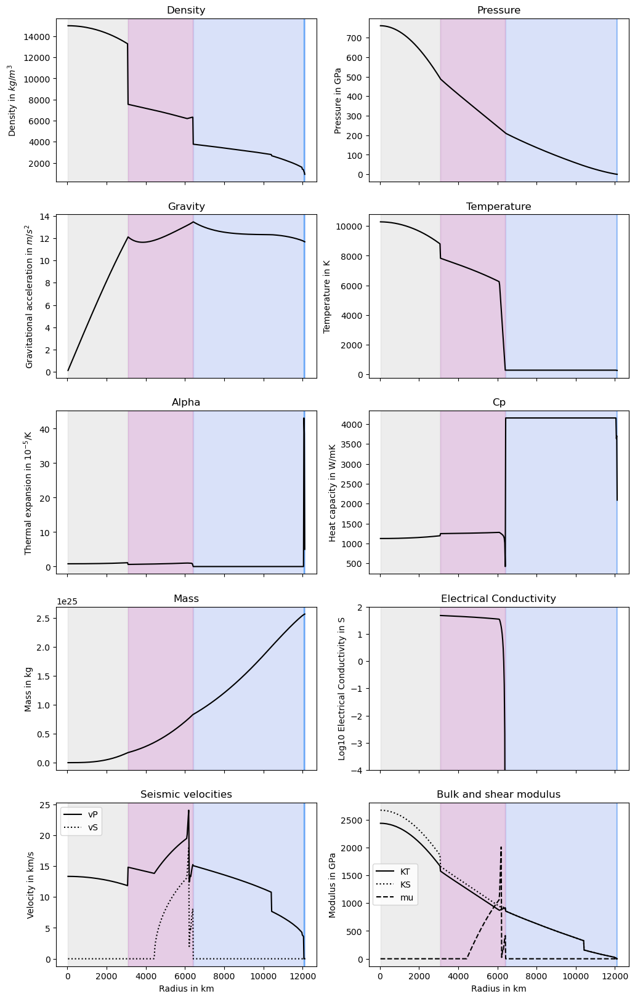

In [9]:
# To  K2-288 B b
if __name__ == "__main__":
    mass_obs = 4.27
    radius_obs = 1.9
    temp_obs = 273
    
    P_p=1.42*10**5
    mass_err=0.2*mass_obs
    radius_err=0.3
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [27]:
mass_obs = 4.27
radius_obs = 1.9
temp_obs = 273
    
P_p=1.42*10**5

In [28]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 67.925, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8799.172022317538 7829.9185343223435 3069730.6874407814 14429.382575912463 1147.0304582986796 8799.172022317538


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.331 R_E, M=2.2182 M_E, χ²=0.0322
[2/216] Fe=10, H2O=5 -> R=1.374 R_E, M=2.2267 M_E, χ²=0.0659
[3/216] Fe=10, H2O=10 -> R=1.401 R_E, M=2.2261 M_E, χ²=0.0866
[4/216] Fe=10, H2O=15 -> R=1.424 R_E, M=2.2258 M_E, χ²=0.1042
[5/216] Fe=10, H2O=20 -> R=1.446 R_E, M=2.2258 M_E, χ²=0.1208
[6/216] Fe=10, H2O=25 -> R=1.465 R_E, M=2.2257 M_E, χ²=0.1359
[7/216] Fe=10, H2O=30 -> R=1.482 R_E, M=2.2256 M_E, χ²=0.1492
[8/216] Fe=10, H2O=35 -> R=1.499 R_E, M=2.2256 M_E, χ²=0.1618
[9/216] Fe=10, H2O=40 -> R=1.514 R_E, M=2.2255 M_E, χ²=0.1741
[10/216] Fe=10, H2O=45 -> R=1.530 R_E, M=2.2254 M_E, χ²=0.1861
[11/216] Fe=10, H2O=50 -> R=1.545 R_E, M=2.2253 M_E, χ²=0.1977
[12/216] Fe=10, H2O=55 -> R=1.560 R_E, M=2.2251 M_E, χ²=0.2092
[13/216] Fe=10, H2O=60 -> R=1.575 R_E, M=2.2249 M_E, χ²=0.2207
[14/216] Fe=10, H2O=65 -> R=1.589 R_E, M=2.2247 M_E, χ²=0.2320
[15/216] Fe=10, H2O=70 -> R=1.603 R_E, M=2.2243 M_E, χ²=0.2431
[16/216] Fe=10, H2

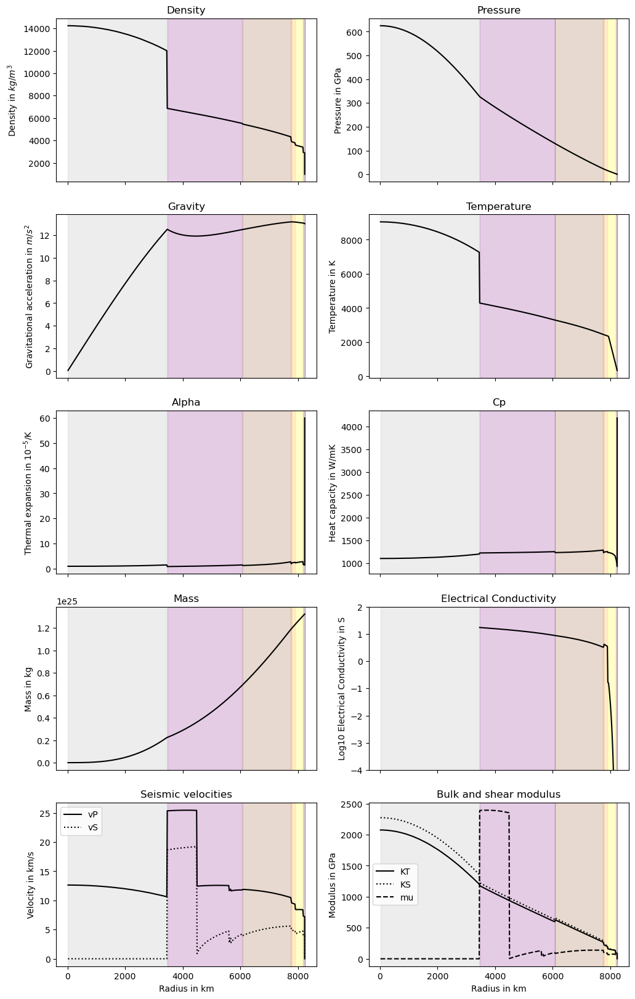

In [12]:
# To  K2-72 e
if __name__ == "__main__":
    mass_obs = 2.21
    radius_obs = 1.29
    temp_obs = 346
    
    P_p=1.79*10**5
    mass_err=0.2*mass_obs
    radius_err=0.14
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [29]:
mass_obs = 2.21
radius_obs = 1.29
temp_obs = 346
    
P_p=1.79*10**5

In [30]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 23.0, 0.125, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

7263.863212320954 4290.933449202728 3446850.2270293827 13510.346708268944 1133.9960931274854 7263.863212320954


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.383 R_E, M=2.5494 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0126
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=0.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=8.5, H2O=0.0 -> R=1.388 R_E, M=2.5488 M_E, χ²=0.0095
[2/77] Fe=8.5, H2O=0.025 -> R=1.386 R_E, M=2.5481 M_E, χ²=0.0102
[3/77] Fe=8.5, H2O=0.05 -> R=1.386 R_E, M=2.5475 M_E, χ²=0.0102
[4/77] Fe=8.5, H2O=0.07500000000000001 -> R=1.386 R_E, M=2.5469 M_E, χ²=0.0102
[5/77] Fe=8.5, H2O=0.1 -> R=1.386 R_E, M=2.5462 M_E, χ²=0.0102
[6/77] Fe=8.5, H2O=0.125 -> R=1.386 R_E, M=2.5456 M_E, χ²=0.0102
[7/77] Fe=8.5, H2O=0.15000000000000002 -> R=1.391 R_E, M=2.5568 M_E, χ²=0.0095
[8/77] Fe=8.5, H2O=0.17500000000000002 -> R

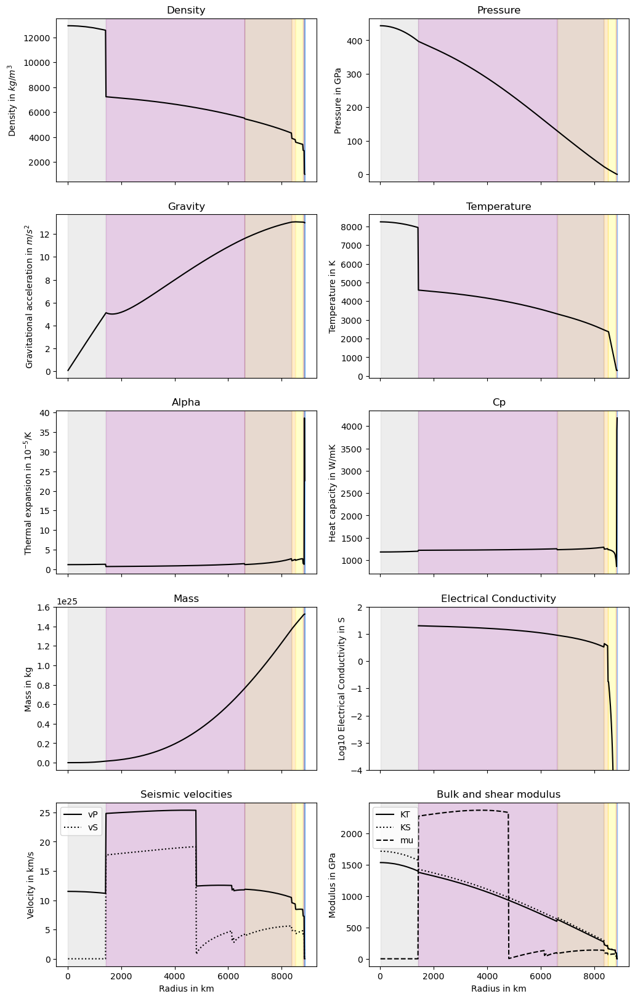

In [15]:
# To  Kepler 1229 b
if __name__ == "__main__":
    mass_obs = 2.54
    radius_obs = 1.4
    temp_obs = 295
    
    P_p=1.7*10**5
    mass_err=0.2*mass_obs
    radius_err=0.13
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [31]:
mass_obs = 2.54
radius_obs = 1.4
temp_obs = 295
    
P_p=1.7*10**5

In [32]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,8.50 , 0.15, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.15893550636900086
12821.75709439883


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=0.832 R_E, M=0.4315 M_E, χ²=0.0440
[2/216] Fe=10, H2O=5 -> R=0.862 R_E, M=0.4332 M_E, χ²=0.0824
[3/216] Fe=10, H2O=10 -> R=0.883 R_E, M=0.4331 M_E, χ²=0.1077
[4/216] Fe=10, H2O=15 -> R=0.898 R_E, M=0.4331 M_E, χ²=0.1273
[5/216] Fe=10, H2O=20 -> R=0.913 R_E, M=0.4331 M_E, χ²=0.1458
[6/216] Fe=10, H2O=25 -> R=0.926 R_E, M=0.4331 M_E, χ²=0.1619
[7/216] Fe=10, H2O=30 -> R=0.939 R_E, M=0.4331 M_E, χ²=0.1780
[8/216] Fe=10, H2O=35 -> R=0.951 R_E, M=0.4331 M_E, χ²=0.1934
[9/216] Fe=10, H2O=40 -> R=0.963 R_E, M=0.4331 M_E, χ²=0.2085
[10/216] Fe=10, H2O=45 -> R=0.975 R_E, M=0.4330 M_E, χ²=0.2236
[11/216] Fe=10, H2O=50 -> R=0.987 R_E, M=0.4330 M_E, χ²=0.2383
[12/216] Fe=10, H2O=55 -> R=0.998 R_E, M=0.4330 M_E, χ²=0.2528
[13/216] Fe=10, H2O=60 -> R=1.010 R_E, M=0.4329 M_E, χ²=0.2667
[14/216] Fe=10, H2O=65 -> R=1.020 R_E, M=0.4329 M_E, χ²=0.2803
[15/216] Fe=10, H2O=70 -> R=1.031 R_E, M=0.4328 M_E, χ²=0.2932
[16/216] Fe=10, H2

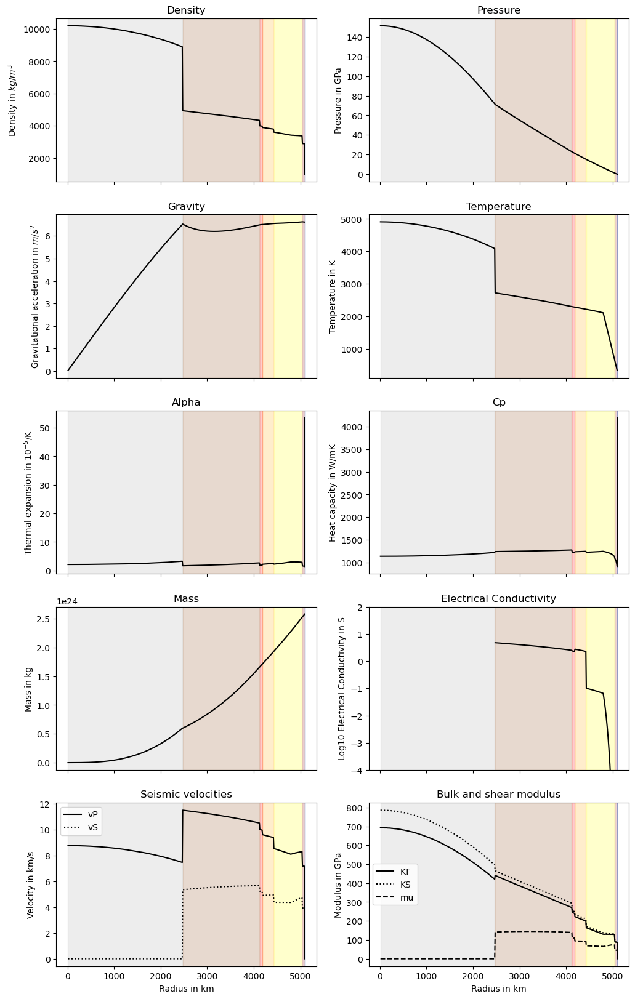

In [18]:
# To  Kepler-138 e 
if __name__ == "__main__":
    mass_obs = 0.43
    radius_obs = 0.797
    temp_obs = 335
    
    P_p=0.46*10**5
    mass_err=0.21
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [33]:
mass_obs = 0.43
radius_obs = 0.797
temp_obs = 335
P_p=0.46*10**5

In [34]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 28.75, 0.125, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

4084.5642970776253 2721.276482518438 2464621.6570337373 9776.810877305883 1166.1106778790565 4084.5642970776253


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.544 R_E, M=3.8343 M_E, χ²=0.1329
[2/216] Fe=10, H2O=5 -> R=1.594 R_E, M=3.8495 M_E, χ²=0.1050
[3/216] Fe=10, H2O=10 -> R=1.623 R_E, M=3.8483 M_E, χ²=0.0884
[4/216] Fe=10, H2O=15 -> R=1.649 R_E, M=3.8476 M_E, χ²=0.0738
[5/216] Fe=10, H2O=20 -> R=1.671 R_E, M=3.8474 M_E, χ²=0.0615
[6/216] Fe=10, H2O=25 -> R=1.691 R_E, M=3.8473 M_E, χ²=0.0503
[7/216] Fe=10, H2O=30 -> R=1.710 R_E, M=3.8472 M_E, χ²=0.0398
[8/216] Fe=10, H2O=35 -> R=1.729 R_E, M=3.8472 M_E, χ²=0.0294
[9/216] Fe=10, H2O=40 -> R=1.748 R_E, M=3.8471 M_E, χ²=0.0195
[10/216] Fe=10, H2O=45 -> R=1.766 R_E, M=3.8469 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 45.0000 wt%
χ² mínimo = 0.0106
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=45.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 38.2500 to 51.7500 (step=0.6750)
Total number of combinatio

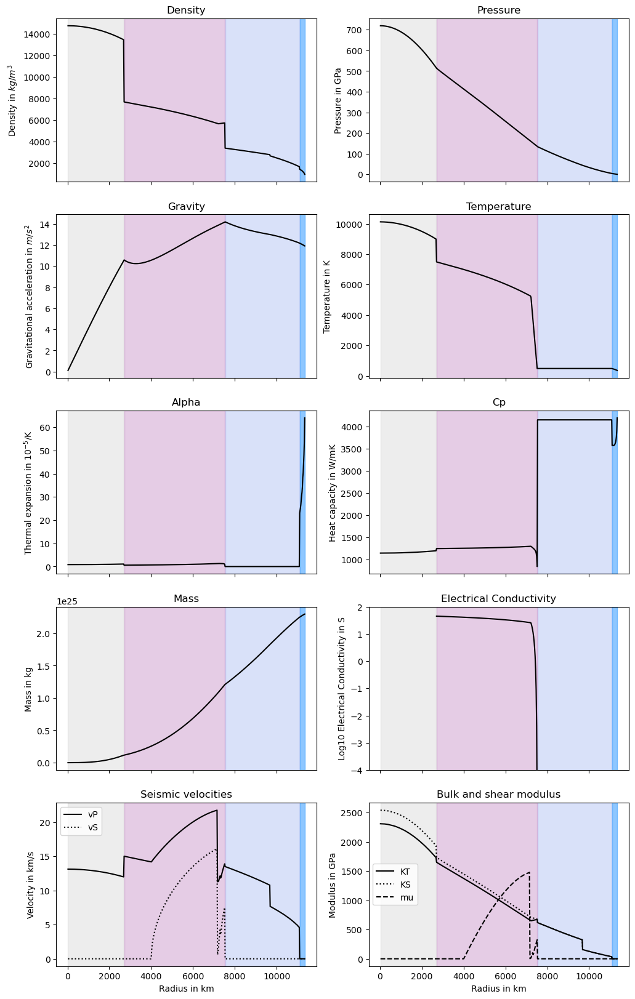

In [21]:
# To  Kepler 1410 b
if __name__ == "__main__":
    mass_obs = 3.82
    radius_obs = 1.78
    temp_obs = 353
    
    P_p=1.47*10**5
    mass_err=0.2*mass_obs
    radius_err=0.14
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)     

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [35]:
mass_obs = 3.82
radius_obs = 1.78
temp_obs = 353
P_p=1.47*10**5

In [36]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 47.70, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8997.35454015711 7493.197507844988 2683997.842925786 14315.472021934198 1156.7233086259193 8997.35454015711


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.544 R_E, M=3.8343 M_E, χ²=0.1329
[2/216] Fe=10, H2O=5 -> R=1.592 R_E, M=3.8491 M_E, χ²=0.1059
[3/216] Fe=10, H2O=10 -> R=1.622 R_E, M=3.8481 M_E, χ²=0.0892
[4/216] Fe=10, H2O=15 -> R=1.648 R_E, M=3.8475 M_E, χ²=0.0746
[5/216] Fe=10, H2O=20 -> R=1.669 R_E, M=3.8473 M_E, χ²=0.0625
[6/216] Fe=10, H2O=25 -> R=1.690 R_E, M=3.8472 M_E, χ²=0.0513
[7/216] Fe=10, H2O=30 -> R=1.709 R_E, M=3.8472 M_E, χ²=0.0405
[8/216] Fe=10, H2O=35 -> R=1.728 R_E, M=3.8471 M_E, χ²=0.0301
[9/216] Fe=10, H2O=40 -> R=1.746 R_E, M=3.8470 M_E, χ²=0.0203
[10/216] Fe=10, H2O=45 -> R=1.765 R_E, M=3.8469 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 45.0000 wt%
χ² mínimo = 0.0112
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=45.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 38.2500 to 51.7500 (step=0.6750)
Total number of combinatio

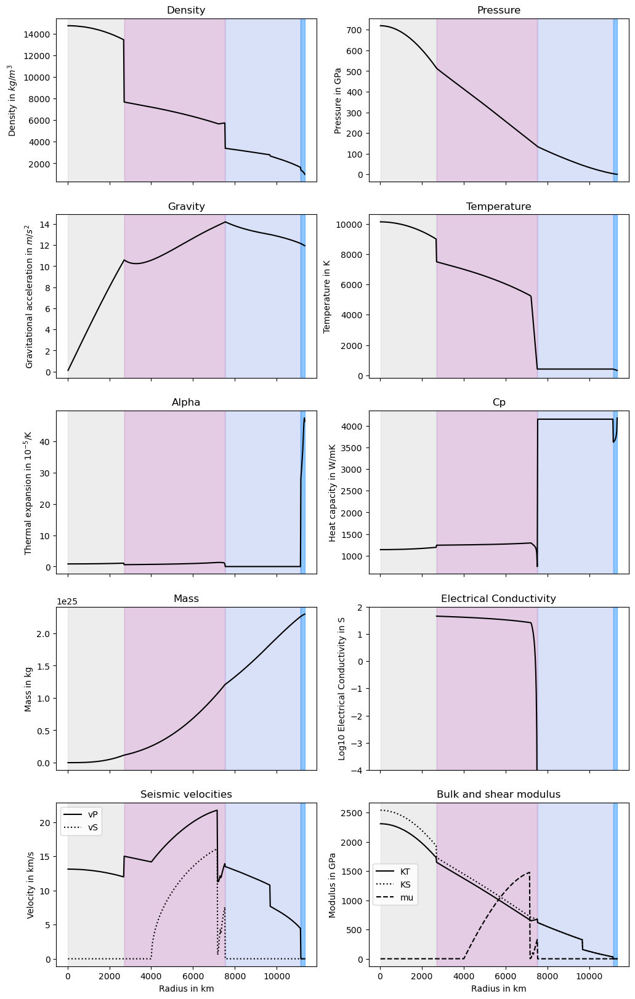

In [9]:
# To  Kepler 1544 b
if __name__ == "__main__":
    mass_obs = 3.82
    radius_obs = 1.78
    temp_obs = 324
    
    P_p=1.47*10**5
    mass_err=0.2*mass_obs
    radius_err=0.09
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [37]:
mass_obs = 3.82
radius_obs = 1.78
temp_obs = 324
    
P_p=1.47*10**5

In [38]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 47.70, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

0.0
0.2364121943176445
14315.575475581472


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.651 R_E, M=4.9587 M_E, χ²=0.2026
[2/216] Fe=10, H2O=5 -> R=1.704 R_E, M=4.9784 M_E, χ²=0.1770
[3/216] Fe=10, H2O=10 -> R=1.735 R_E, M=4.9767 M_E, χ²=0.1618
[4/216] Fe=10, H2O=15 -> R=1.761 R_E, M=4.9759 M_E, χ²=0.1493
[5/216] Fe=10, H2O=20 -> R=1.784 R_E, M=4.9756 M_E, χ²=0.1385
[6/216] Fe=10, H2O=25 -> R=1.805 R_E, M=4.9756 M_E, χ²=0.1281
[7/216] Fe=10, H2O=30 -> R=1.826 R_E, M=4.9755 M_E, χ²=0.1180
[8/216] Fe=10, H2O=35 -> R=1.847 R_E, M=4.9754 M_E, χ²=0.1080
[9/216] Fe=10, H2O=40 -> R=1.867 R_E, M=4.9753 M_E, χ²=0.0982
[10/216] Fe=10, H2O=45 -> R=1.887 R_E, M=4.9751 M_E, χ²=0.0886
[11/216] Fe=10, H2O=50 -> R=1.907 R_E, M=4.9748 M_E, χ²=0.0791
[12/216] Fe=10, H2O=55 -> R=1.926 R_E, M=4.9744 M_E, χ²=0.0699
[13/216] Fe=10, H2O=60 -> R=1.945 R_E, M=4.9739 M_E, χ²=0.0608
[14/216] Fe=10, H2O=65 -> R=1.964 R_E, M=4.9733 M_E, χ²=0.0518
[15/216] Fe=10, H2O=70 -> R=1.982 R_E, M=4.9726 M_E, χ²=0.0429
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_19940\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.576 R_E, M=4.9678 M_E, χ²=0.2385
[74/216] Fe=30, H2O=5 -> R=1.631 R_E, M=4.9841 M_E, χ²=0.2124
[75/216] Fe=30, H2O=10 -> R=1.663 R_E, M=4.9830 M_E, χ²=0.1968
[76/216] Fe=30, H2O=15 -> R=1.688 R_E, M=4.9826 M_E, χ²=0.1847
[77/216] Fe=30, H2O=20 -> R=1.712 R_E, M=4.9826 M_E, χ²=0.1733
[78/216] Fe=30, H2O=25 -> R=1.735 R_E, M=4.9826 M_E, χ²=0.1621
[79/216] Fe=30, H2O=30 -> R=1.757 R_E, M=4.9826 M_E, χ²=0.1513
[80/216] Fe=30, H2O=35 -> R=1.779 R_E, M=4.9826 M_E, χ²=0.1408
[81/216] Fe=30, H2O=40 -> R=1.800 R_E, M=4.9824 M_E, χ²=0.1305
[82/216] Fe=30, H2O=45 -> R=1.821 R_E, M=4.9822 M_E, χ²=0.1205
[83/216] Fe=30, H2O=50 -> R=1.841 R_E, M=4.9817 M_E, χ²=0.1108
[84/216] Fe=30, H2O=55 -> R=1.861 R_E, M=4.9811 M_E, χ²=0.1012
[85/216] Fe=30, H2O=60 -> R=1.881 R_E, M=4.9802 M_E, χ²=0.0918
[86/216] Fe=30, H2O=65 -> R=1.900 R_E, M=4.9791 M_E, χ²=0.0826
[87/216] Fe=30, H2O=70 -> R=1.917 R_E, M=4.9766 M_E, χ²=0.0741
[88/216] Fe=30, H2O=75 -> R=1.958 R_E, M=4.6422 M_E, χ²=0

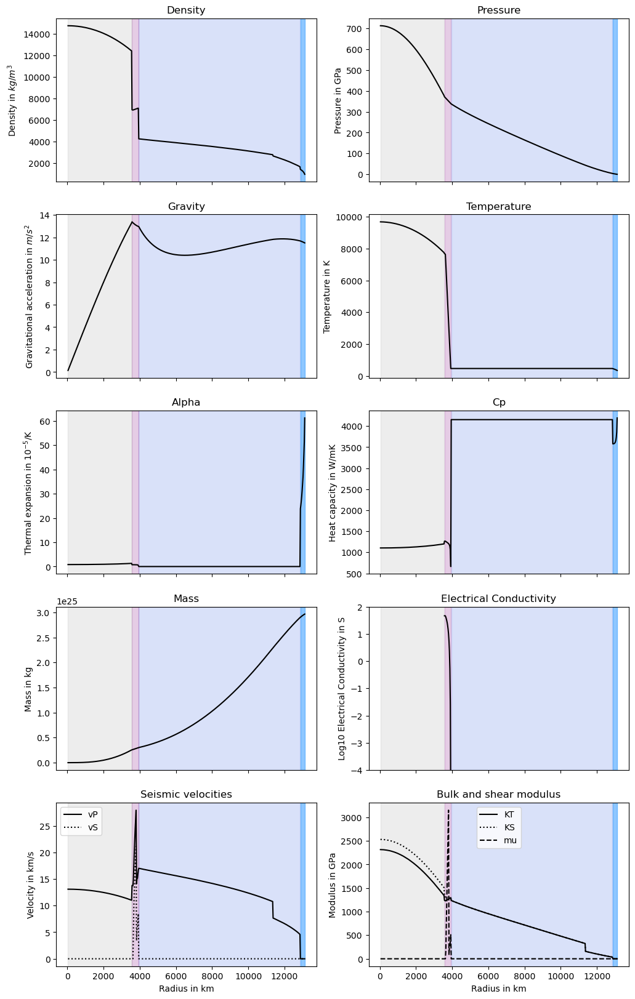

In [9]:
# To  Kepler 1606 b
if __name__ == "__main__":

    mass_obs = 4.94
    radius_obs = 2.07
    temp_obs = 348
    
    P_p=1.35*10**5
    mass_err=0.2*mass_obs
    radius_err=0.23
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [39]:
mass_obs = 4.94
radius_obs = 2.07
temp_obs = 348
    
P_p=1.35*10**5

In [40]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 90.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

7750.670486526422 7686.880210489805 3547648.172822497 13982.941072518386 1133.2574320688166 7750.670486526422


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.579 R_E, M=4.1756 M_E, χ²=0.1558
[2/216] Fe=10, H2O=5 -> R=1.630 R_E, M=4.1923 M_E, χ²=0.1284
[3/216] Fe=10, H2O=10 -> R=1.661 R_E, M=4.1909 M_E, χ²=0.1123
[4/216] Fe=10, H2O=15 -> R=1.687 R_E, M=4.1902 M_E, χ²=0.0982
[5/216] Fe=10, H2O=20 -> R=1.709 R_E, M=4.1899 M_E, χ²=0.0866
[6/216] Fe=10, H2O=25 -> R=1.729 R_E, M=4.1898 M_E, χ²=0.0757
[7/216] Fe=10, H2O=30 -> R=1.749 R_E, M=4.1898 M_E, χ²=0.0650
[8/216] Fe=10, H2O=35 -> R=1.769 R_E, M=4.1897 M_E, χ²=0.0546
[9/216] Fe=10, H2O=40 -> R=1.787 R_E, M=4.1896 M_E, χ²=0.0448
[10/216] Fe=10, H2O=45 -> R=1.807 R_E, M=4.1894 M_E, χ²=0.0347
[11/216] Fe=10, H2O=50 -> R=1.825 R_E, M=4.1892 M_E, χ²=0.0250
[12/216] Fe=10, H2O=55 -> R=1.843 R_E, M=4.1889 M_E, χ²=0.0158
[13/216] Fe=10, H2O=60 -> R=1.861 R_E, M=4.1885 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 60.0000 wt%
χ² mínimo = 0.0082
(Search interrupted - excellent fit found)

 STE

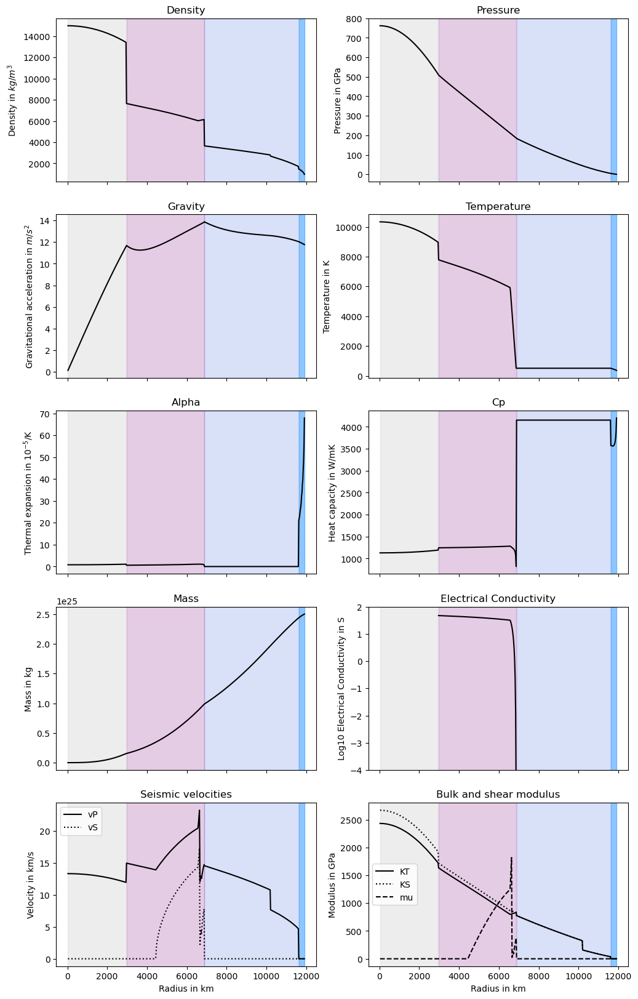

In [13]:
# To  Kepler-1638 b
if __name__ == "__main__":
    mass_obs = 4.16
    radius_obs = 1.87
    temp_obs = 360
    
    P_p=1.44*10**5
    mass_err=0.2*mass_obs
    radius_err=0.33
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [41]:
mass_obs = 4.16
radius_obs = 1.87
temp_obs = 360
    
P_p=1.44*10**5

In [42]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 60.90, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8968.447188043285 7787.645114189285 2945525.434214868 14473.554567137493 1149.821791035189 8968.447188043285


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.122 R_E, M=1.2044 M_E, χ²=0.0584
[2/216] Fe=10, H2O=5 -> R=1.160 R_E, M=1.2090 M_E, χ²=0.0944
[3/216] Fe=10, H2O=10 -> R=1.182 R_E, M=1.2087 M_E, χ²=0.1149
[4/216] Fe=10, H2O=15 -> R=1.202 R_E, M=1.2085 M_E, χ²=0.1342
[5/216] Fe=10, H2O=20 -> R=1.221 R_E, M=1.2085 M_E, χ²=0.1520
[6/216] Fe=10, H2O=25 -> R=1.238 R_E, M=1.2085 M_E, χ²=0.1680
[7/216] Fe=10, H2O=30 -> R=1.254 R_E, M=1.2085 M_E, χ²=0.1829
[8/216] Fe=10, H2O=35 -> R=1.270 R_E, M=1.2085 M_E, χ²=0.1980
[9/216] Fe=10, H2O=40 -> R=1.285 R_E, M=1.2084 M_E, χ²=0.2121
[10/216] Fe=10, H2O=45 -> R=1.299 R_E, M=1.2084 M_E, χ²=0.2257
[11/216] Fe=10, H2O=50 -> R=1.312 R_E, M=1.2083 M_E, χ²=0.2380
[12/216] Fe=10, H2O=55 -> R=1.325 R_E, M=1.2082 M_E, χ²=0.2500
[13/216] Fe=10, H2O=60 -> R=1.338 R_E, M=1.2081 M_E, χ²=0.2619
[14/216] Fe=10, H2O=65 -> R=1.350 R_E, M=1.2079 M_E, χ²=0.2736
[15/216] Fe=10, H2O=70 -> R=1.362 R_E, M=1.2078 M_E, χ²=0.2851
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_19940\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.074 R_E, M=1.2063 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0146
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.085 R_E, M=1.2060 M_E, χ²=0.0245
[2/77] Fe=25.5, H2O=0.025 -> R=1.085 R_E, M=1.2057 M_E, χ²=0.0237
[3/77] Fe=25.5, H2O=0.05 -> R=1.085 R_E, M=1.2054 M_E, χ²=0.0236
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.084 R_E, M=1.2051 M_E, χ²=0.0234
[5/77] Fe=25.5, H2O=0.1 -> R=1.084 R_E, M=1.2048 M_E, χ²=0.0233
[6/77] Fe=25.5, H2O=0.125 -> R=1.084 R_E, M=1.2045 M_E, χ²=0.0232
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.088 R_E, M=1.2093 M_E, χ²=0.0273
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.088 R_E, M=1.2099 M_E, χ²=0.0279
[9

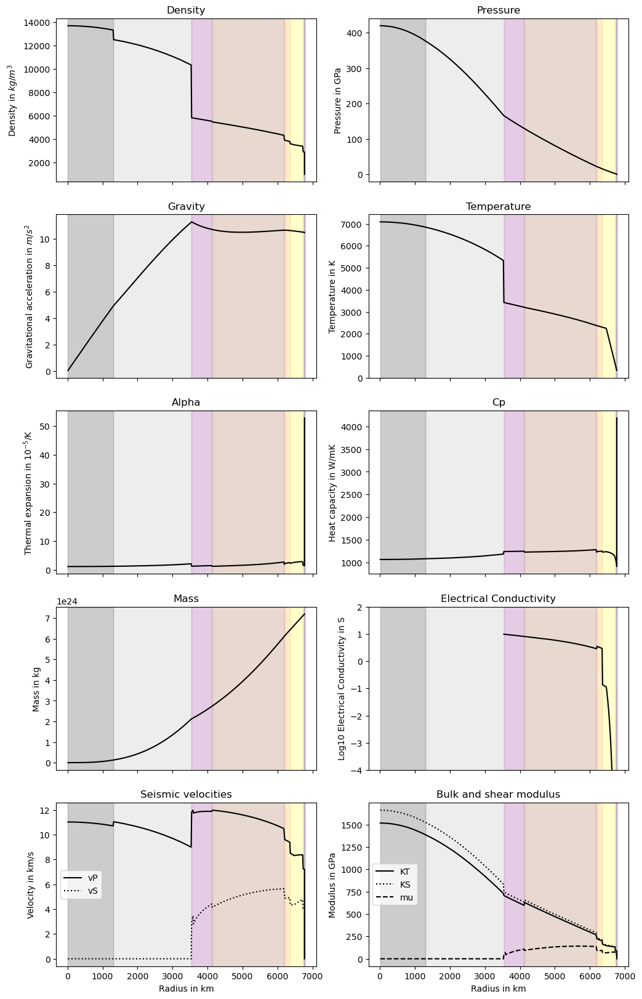

In [16]:
# To  Kepler-1649 c
if __name__ == "__main__":
    mass_obs = 1.2
    radius_obs = 1.06
    temp_obs = 334
    
    P_p=1.16*10**5
    mass_err=0.2*mass_obs
    radius_err=0.15
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [44]:
mass_obs = 1.2
radius_obs = 1.06
temp_obs = 334
    
P_p=1.16*10**5

In [45]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5332.436112510599 3423.448649393016 2213499.0508544724 11589.675759618647 1123.314973043312 5332.436112510599


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.471 R_E, M=3.2019 M_E, χ²=0.0805
[2/216] Fe=10, H2O=5 -> R=1.517 R_E, M=3.2142 M_E, χ²=0.0525
[3/216] Fe=10, H2O=10 -> R=1.547 R_E, M=3.2133 M_E, χ²=0.0342
[4/216] Fe=10, H2O=15 -> R=1.571 R_E, M=3.2129 M_E, χ²=0.0195
[5/216] Fe=10, H2O=20 -> R=1.593 R_E, M=3.2127 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 20.0000 wt%
χ² mínimo = 0.0084
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=20.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 17.0000 to 23.0000 (step=0.3000)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=17.0 -> R=1.585 R_E, M=3.2122 M_E, χ²=0.0117
[2/154] Fe=8.5, H2O=17.3 -> R=1.586 R_E, M=3.2122 M_E, χ²=0.0110
[3/154] Fe=8.5, H2O=17.6 -> R=1.588 R_E, M=3.2122 M_E, χ²=0.0104
[4/154] Fe=8.5, H2O=17.900000000000002 -> R=1.589 R_E, M=3.2122 M_E, χ²=0

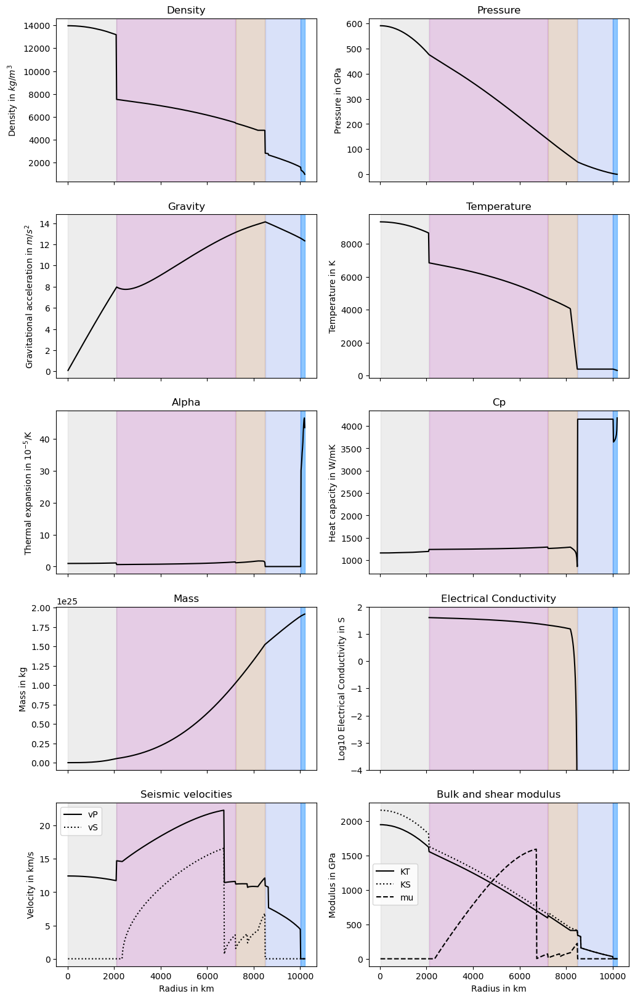

In [19]:
# To  Kepler-1652 b
if __name__ == "__main__":
    mass_obs = 3.19
    radius_obs = 1.6
    temp_obs = 320
    
    P_p=1.57*10**5
    mass_err=0.2*mass_obs
    radius_err=0.18
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [46]:
mass_obs = 3.19
radius_obs = 1.6
temp_obs = 320
    
P_p=1.57*10**5

In [47]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 20.0, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8671.80636491009 6815.599915362055 2076544.9421648863 13697.631110006896 1172.9162781272705 8671.80636491009


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.240 R_E, M=1.7163 M_E, χ²=0.0600
[2/216] Fe=10, H2O=5 -> R=1.276 R_E, M=1.7223 M_E, χ²=0.0908
[3/216] Fe=10, H2O=10 -> R=1.301 R_E, M=1.7217 M_E, χ²=0.1121
[4/216] Fe=10, H2O=15 -> R=1.323 R_E, M=1.7220 M_E, χ²=0.1312
[5/216] Fe=10, H2O=20 -> R=1.342 R_E, M=1.7220 M_E, χ²=0.1476
[6/216] Fe=10, H2O=25 -> R=1.361 R_E, M=1.7220 M_E, χ²=0.1634
[7/216] Fe=10, H2O=30 -> R=1.379 R_E, M=1.7220 M_E, χ²=0.1784
[8/216] Fe=10, H2O=35 -> R=1.394 R_E, M=1.7219 M_E, χ²=0.1919
[9/216] Fe=10, H2O=40 -> R=1.409 R_E, M=1.7219 M_E, χ²=0.2046
[10/216] Fe=10, H2O=45 -> R=1.424 R_E, M=1.7218 M_E, χ²=0.2170
[11/216] Fe=10, H2O=50 -> R=1.438 R_E, M=1.7217 M_E, χ²=0.2290
[12/216] Fe=10, H2O=55 -> R=1.452 R_E, M=1.7216 M_E, χ²=0.2408
[13/216] Fe=10, H2O=60 -> R=1.465 R_E, M=1.7214 M_E, χ²=0.2524
[14/216] Fe=10, H2O=65 -> R=1.479 R_E, M=1.7212 M_E, χ²=0.2639
[15/216] Fe=10, H2O=70 -> R=1.492 R_E, M=1.7210 M_E, χ²=0.2751
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_19940\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.187 R_E, M=1.7191 M_E, χ²=0.0154
[74/216] Fe=30, H2O=5 -> R=1.224 R_E, M=1.7242 M_E, χ²=0.0471
[75/216] Fe=30, H2O=10 -> ERRO: cannot access local variable 'rho' where it is not associated with a value
[76/216] Fe=30, H2O=15 -> R=1.273 R_E, M=1.7241 M_E, χ²=0.0887
[77/216] Fe=30, H2O=20 -> R=1.293 R_E, M=1.7242 M_E, χ²=0.1055
[78/216] Fe=30, H2O=25 -> R=1.312 R_E, M=1.7242 M_E, χ²=0.1218
[79/216] Fe=30, H2O=30 -> R=1.329 R_E, M=1.7242 M_E, χ²=0.1360
[80/216] Fe=30, H2O=35 -> R=1.345 R_E, M=1.7242 M_E, χ²=0.1494
[81/216] Fe=30, H2O=40 -> R=1.360 R_E, M=1.7242 M_E, χ²=0.1625
[82/216] Fe=30, H2O=45 -> R=1.375 R_E, M=1.7241 M_E, χ²=0.1751
[83/216] Fe=30, H2O=50 -> R=1.389 R_E, M=1.7240 M_E, χ²=0.1875
[84/216] Fe=30, H2O=55 -> R=1.403 R_E, M=1.7238 M_E, χ²=0.1997
[85/216] Fe=30, H2O=60 -> R=1.418 R_E, M=1.7235 M_E, χ²=0.2118
[86/216] Fe=30, H2O=65 -> R=1.431 R_E, M=1.7232 M_E, χ²=0.2234
[87/216] Fe=30, H2O=70 -> R=1.444 R_E, M=1.7224 M_E, χ²=0.2342
[88/216] Fe=3

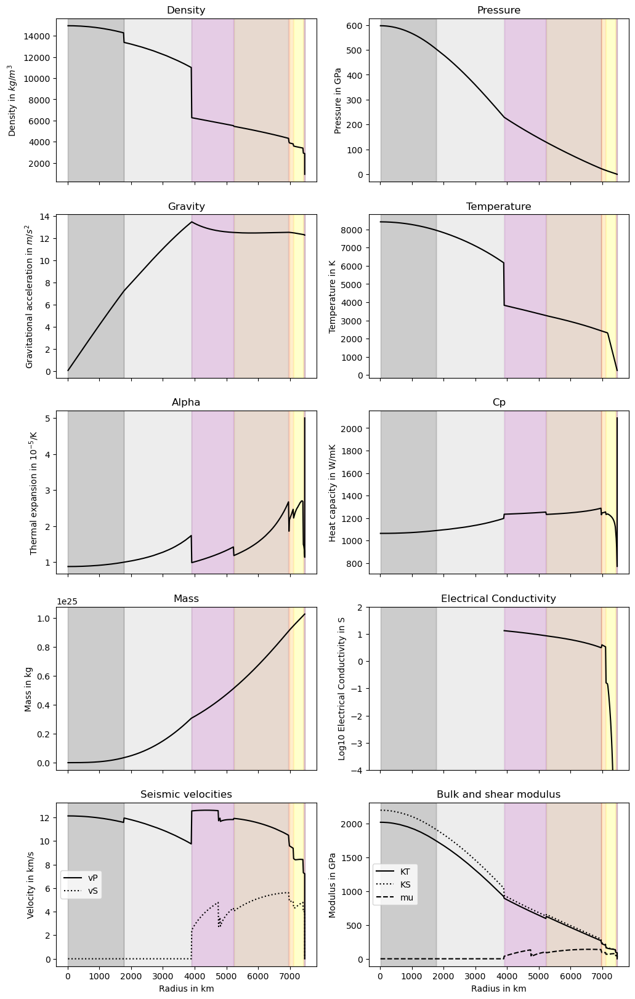

In [22]:
# To  Kepler-186 f
if __name__ == "__main__":
    mass_obs = 1.71
    radius_obs = 1.17
    temp_obs = 253
    
    P_p=1.58*10**5
    mass_err=0.2*mass_obs
    radius_err=0.08
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [50]:
mass_obs = 1.71
radius_obs = 1.17
temp_obs = 253
    
P_p=1.58*10**5

In [51]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 35.0, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

6168.0885606877255 3831.0190139026204 2116145.341183925 12363.222127807981 1132.6293073325367 6168.0885606877255


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.559 R_E, M=3.9849 M_E, χ²=0.1433
[2/216] Fe=10, H2O=5 -> R=1.608 R_E, M=4.0003 M_E, χ²=0.1168
[3/216] Fe=10, H2O=10 -> R=1.638 R_E, M=3.9992 M_E, χ²=0.1002
[4/216] Fe=10, H2O=15 -> R=1.664 R_E, M=3.9986 M_E, χ²=0.0860
[5/216] Fe=10, H2O=20 -> R=1.686 R_E, M=3.9984 M_E, χ²=0.0739
[6/216] Fe=10, H2O=25 -> R=1.706 R_E, M=3.9983 M_E, χ²=0.0629
[7/216] Fe=10, H2O=30 -> R=1.726 R_E, M=3.9982 M_E, χ²=0.0524
[8/216] Fe=10, H2O=35 -> R=1.745 R_E, M=3.9982 M_E, χ²=0.0419
[9/216] Fe=10, H2O=40 -> R=1.763 R_E, M=3.9981 M_E, χ²=0.0319
[10/216] Fe=10, H2O=45 -> R=1.782 R_E, M=3.9979 M_E, χ²=0.0220
[11/216] Fe=10, H2O=50 -> R=1.800 R_E, M=3.9977 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 50.0000 wt%
χ² mínimo = 0.0129
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=50.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H

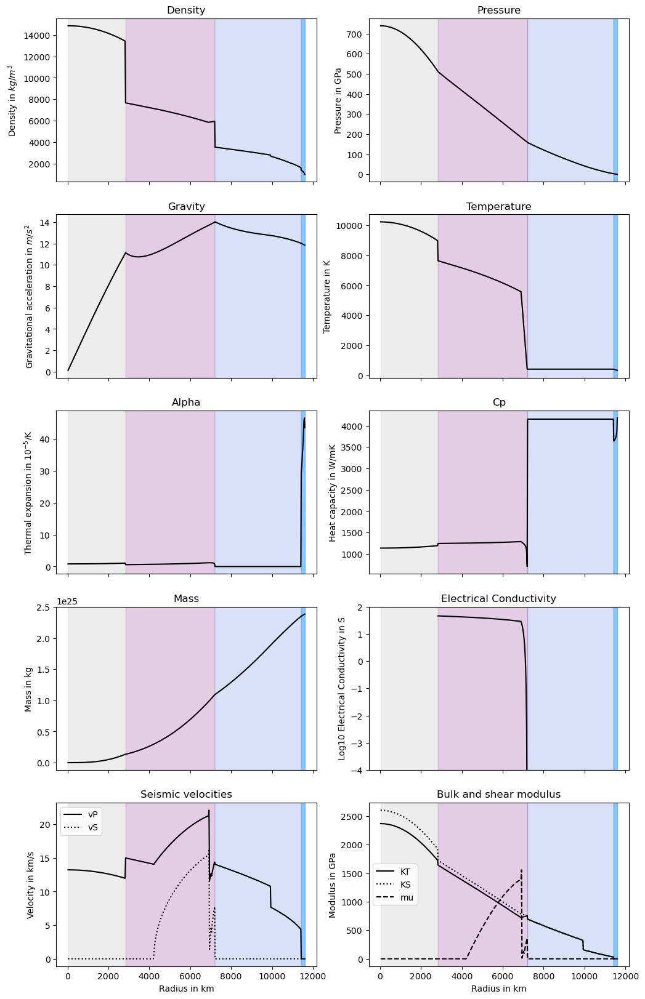

In [25]:
# To  Kepler-283 c
if __name__ == "__main__":
    mass_obs = 3.97
    radius_obs = 1.82
    temp_obs = 320
    
    P_p=1.46*10**5
    mass_err=0.2*mass_obs
    radius_err=0.12
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [52]:
mass_obs = 3.97
radius_obs = 1.82
temp_obs = 320   
P_p=1.46*10**5

In [53]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 54.50, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8978.559632505989 7631.123554890851 2815671.4806877007 14389.333619377763 1153.3368205203942 8978.559632505989


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.442 R_E, M=2.9710 M_E, χ²=0.0578
[2/216] Fe=10, H2O=5 -> R=1.489 R_E, M=2.9828 M_E, χ²=0.0281
[3/216] Fe=10, H2O=10 -> R=1.518 R_E, M=2.9818 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 10.0000 wt%
χ² mínimo = 0.0107
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=10.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 8.5000 to 11.5000 (step=0.1500)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=8.5 -> R=1.515 R_E, M=2.9814 M_E, χ²=0.0123
[2/154] Fe=8.5, H2O=8.65 -> R=1.515 R_E, M=2.9813 M_E, χ²=0.0120
[3/154] Fe=8.5, H2O=8.8 -> R=1.516 R_E, M=2.9812 M_E, χ²=0.0115
[4/154] Fe=8.5, H2O=8.950000000000001 -> R=1.517 R_E, M=2.9813 M_E, χ²=0.0110
[5/154] Fe=8.5, H2O=9.100000000000001 -> R=1.518 R_E, M=2.9813 M_E, χ²=0.0107
[6/154] Fe=8.5, H2O=9.250000000000002 -> R=1

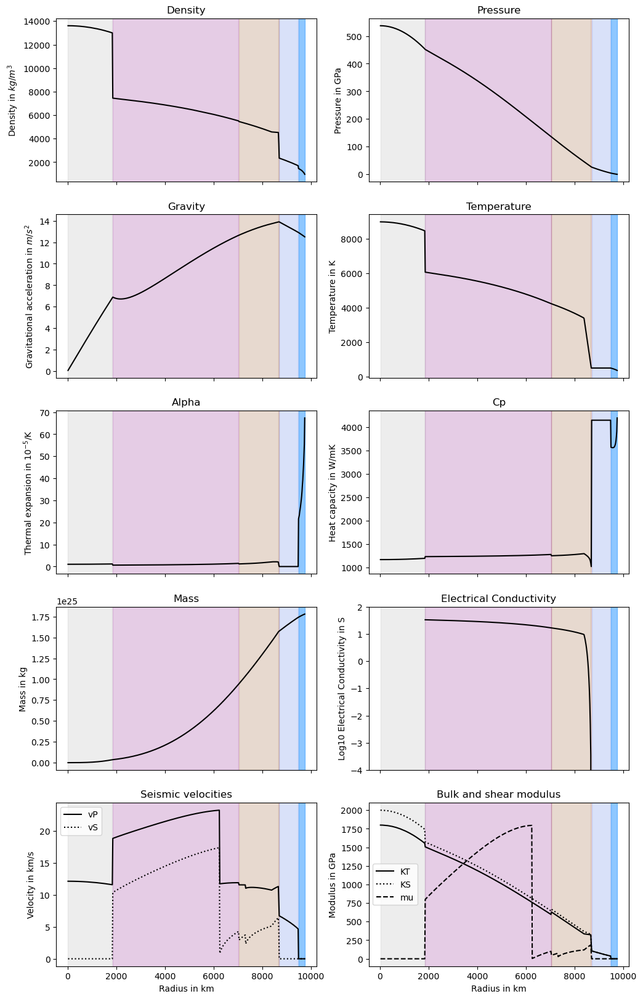

In [54]:
# To  Kepler-296 e
if __name__ == "__main__":
    mass_obs = 2.96
    radius_obs = 1.53
    temp_obs = 359
    
    P_p=1.62*10**5
    mass_err=0.2*mass_obs
    radius_err=0.27
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [96]:
mass_obs = 2.96
radius_obs = 1.53
temp_obs = 359
    
P_p=1.62*10**5

In [97]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 11.65, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8453.066178823303 6055.131923953738 1841982.3255093028 13407.205261717618 1178.8400834556803 8453.066178823303


[3/216] Fe=10, H2O=10 -> R=1.628 R_E, M=3.9185 M_E, χ²=0.0956
[4/216] Fe=10, H2O=15 -> R=1.655 R_E, M=3.9180 M_E, χ²=0.0810
[5/216] Fe=10, H2O=20 -> R=1.676 R_E, M=3.9177 M_E, χ²=0.0691
[6/216] Fe=10, H2O=25 -> R=1.696 R_E, M=3.9177 M_E, χ²=0.0580
[7/216] Fe=10, H2O=30 -> R=1.716 R_E, M=3.9176 M_E, χ²=0.0475
[8/216] Fe=10, H2O=35 -> R=1.735 R_E, M=3.9176 M_E, χ²=0.0370
[9/216] Fe=10, H2O=40 -> R=1.753 R_E, M=3.9175 M_E, χ²=0.0270
[10/216] Fe=10, H2O=45 -> R=1.772 R_E, M=3.9173 M_E, χ²=0.0173
[11/216] Fe=10, H2O=50 -> R=1.790 R_E, M=3.9171 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 50.0000 wt%
χ² mínimo = 0.0090
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=50.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 42.5000 to 57.5000 (step=0.7500)
Total number of combinations: 7 × 21 = 147
Testing 147 combinations.
[1/147] Fe=8.5, H2O=42.5 -> R=1.767 R_E, M=3.9167 M_E, χ²=0.0196

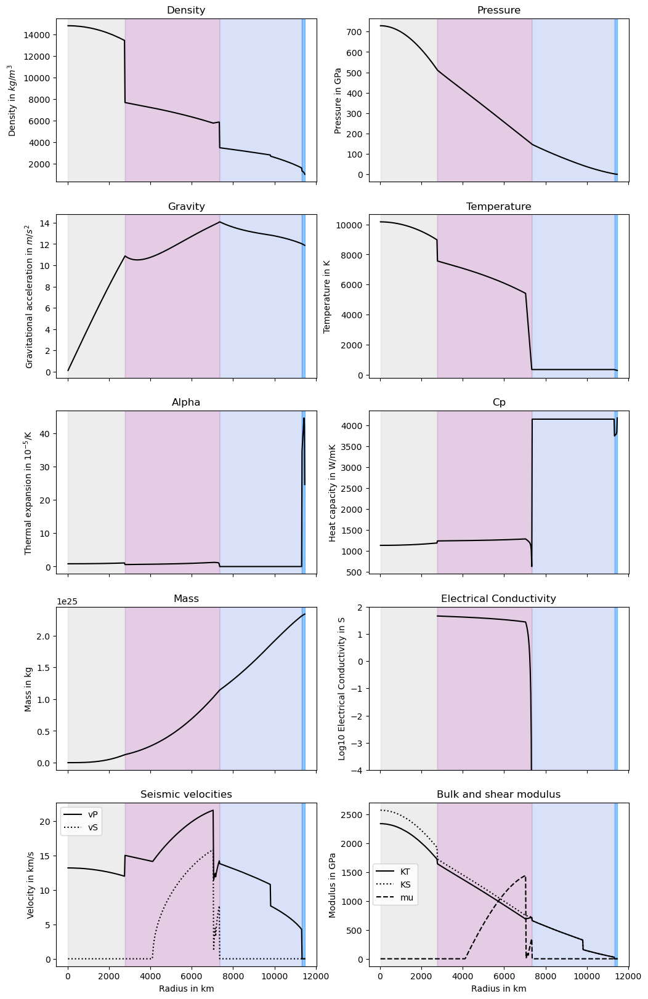

In [31]:
# To  Kepler-296 f
if __name__ == "__main__":
    mass_obs = 3.89
    radius_obs = 1.8
    temp_obs = 297
    
    P_p=1.46*10**5
    mass_err=0.2*mass_obs
    radius_err=0.31
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)
print(Ric/(radius_obs*R_t*1000))
print(Rc/(radius_obs*R_t*1000))
print(rho_core_mean)

In [56]:
mass_obs = 3.89
radius_obs = 1.8
temp_obs = 297
    
P_p=1.46*10**5

In [57]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 51.50, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8976.448099262396 7567.885112080838 2755665.7615434485 14346.441438836051 1154.9524811598767 8976.448099262396


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.575 R_E, M=4.1355 M_E, χ²=0.1534
[2/216] Fe=10, H2O=5 -> R=1.626 R_E, M=4.1519 M_E, χ²=0.1263
[3/216] Fe=10, H2O=10 -> R=1.656 R_E, M=4.1505 M_E, χ²=0.1101
[4/216] Fe=10, H2O=15 -> R=1.682 R_E, M=4.1499 M_E, χ²=0.0960
[5/216] Fe=10, H2O=20 -> R=1.704 R_E, M=4.1496 M_E, χ²=0.0843
[6/216] Fe=10, H2O=25 -> R=1.724 R_E, M=4.1495 M_E, χ²=0.0735
[7/216] Fe=10, H2O=30 -> R=1.744 R_E, M=4.1494 M_E, χ²=0.0629
[8/216] Fe=10, H2O=35 -> R=1.763 R_E, M=4.1494 M_E, χ²=0.0525
[9/216] Fe=10, H2O=40 -> R=1.782 R_E, M=4.1493 M_E, χ²=0.0425
[10/216] Fe=10, H2O=45 -> R=1.801 R_E, M=4.1491 M_E, χ²=0.0325
[11/216] Fe=10, H2O=50 -> R=1.819 R_E, M=4.1489 M_E, χ²=0.0229
[12/216] Fe=10, H2O=55 -> R=1.838 R_E, M=4.1486 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 55.0000 wt%
χ² mínimo = 0.0139
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000

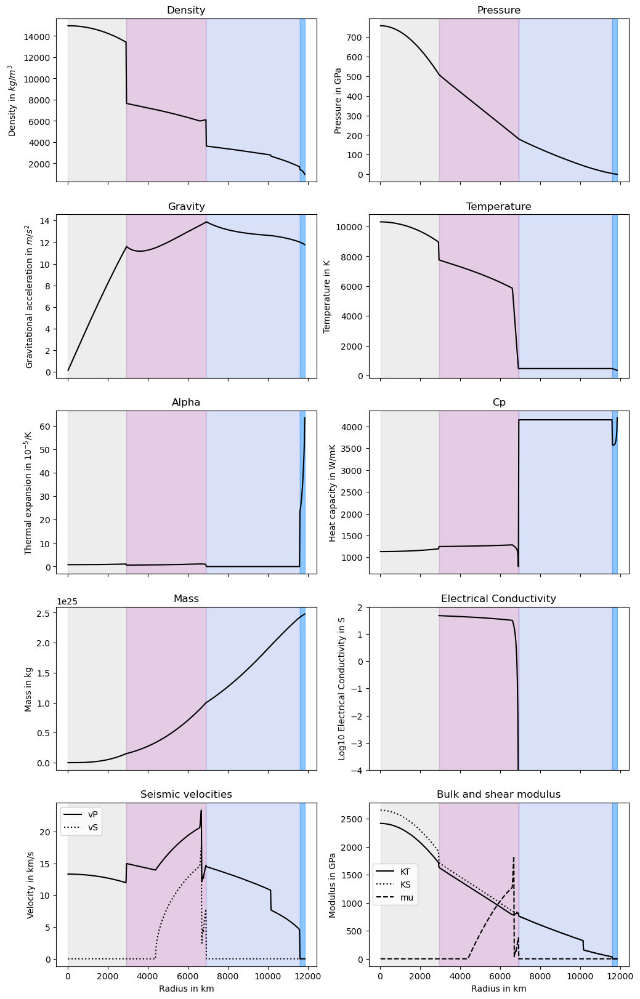

In [34]:
# To  Kepler-440 b
if __name__ == "__main__":

    mass_obs = 4.12
    radius_obs = 1.86
    temp_obs = 352
    
    P_p=1.44*10**5
    mass_err=0.2*mass_obs
    radius_err=0.24
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [58]:
mass_obs = 4.12
radius_obs = 1.86
temp_obs = 352
    
P_p=1.44*10**5

In [59]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 59.950 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8960.86513619926 7756.597174943436 2924334.7269048956 14452.10155551754 1150.436966565899 8960.86513619926


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.488 R_E, M=3.3424 M_E, χ²=0.0927
[2/216] Fe=10, H2O=5 -> R=1.532 R_E, M=3.3547 M_E, χ²=0.0664
[3/216] Fe=10, H2O=10 -> R=1.561 R_E, M=3.3540 M_E, χ²=0.0484
[4/216] Fe=10, H2O=15 -> R=1.586 R_E, M=3.3537 M_E, χ²=0.0336
[5/216] Fe=10, H2O=20 -> R=1.608 R_E, M=3.3535 M_E, χ²=0.0208
[6/216] Fe=10, H2O=25 -> R=1.628 R_E, M=3.3535 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 25.0000 wt%
χ² mínimo = 0.0104
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=25.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 21.2500 to 28.7500 (step=0.3750)
Total number of combinations: 7 × 21 = 147
Testing 147 combinations.
[1/147] Fe=8.5, H2O=21.25 -> R=1.618 R_E, M=3.3529 M_E, χ²=0.0153
[2/147] Fe=8.5, H2O=21.625 -> R=1.619 R_E, M=3.3529 M_E, χ²=0.0144
[3/147] Fe=8.5, H2O=22.0 -> R=1.620 R_E, M=3.3529 M_E, χ²=0.0137
[4/147] 

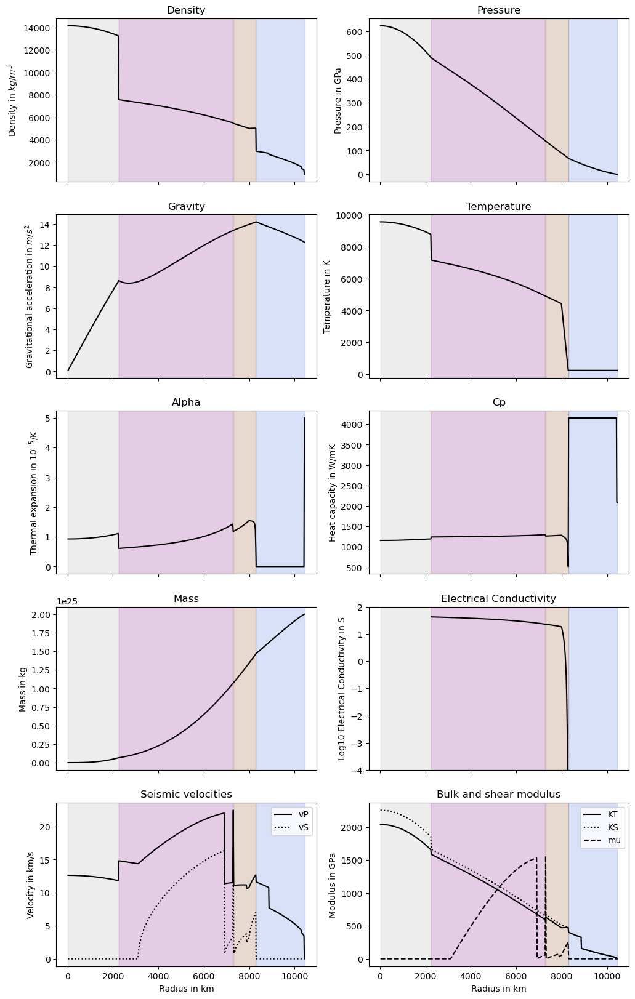

In [37]:
# To  Kepler-441 b
if __name__ == "__main__":
    mass_obs = 3.33
    radius_obs = 1.64
    temp_obs = 247
    
    P_p=1.55*10**5
    mass_err=0.2*mass_obs
    radius_err=0.24
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [60]:
mass_obs = 3.33
radius_obs = 1.64
temp_obs = 247
    
P_p=1.55*10**5

In [61]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs,8.50 , 26.875, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8772.834915974845 7156.975723536055 2240560.8302981453 13866.212945713814 1168.7348243152583 8772.834915974845


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.356 R_E, M=2.3687 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0122
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=0.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=8.5, H2O=0.0 -> R=1.360 R_E, M=2.3681 M_E, χ²=0.0153
[2/77] Fe=8.5, H2O=0.025 -> R=1.359 R_E, M=2.3675 M_E, χ²=0.0144
[3/77] Fe=8.5, H2O=0.05 -> R=1.359 R_E, M=2.3669 M_E, χ²=0.0143
[4/77] Fe=8.5, H2O=0.07500000000000001 -> R=1.359 R_E, M=2.3664 M_E, χ²=0.0141
[5/77] Fe=8.5, H2O=0.1 -> R=1.359 R_E, M=2.3658 M_E, χ²=0.0140
[6/77] Fe=8.5, H2O=0.125 -> R=1.358 R_E, M=2.3652 M_E, χ²=0.0139
[7/77] Fe=8.5, H2O=0.15000000000000002 -> R=1.363 R_E, M=2.3756 M_E, χ²=0.0181
[8/77] Fe=8.5, H2O=0.17500000000000002 -> R

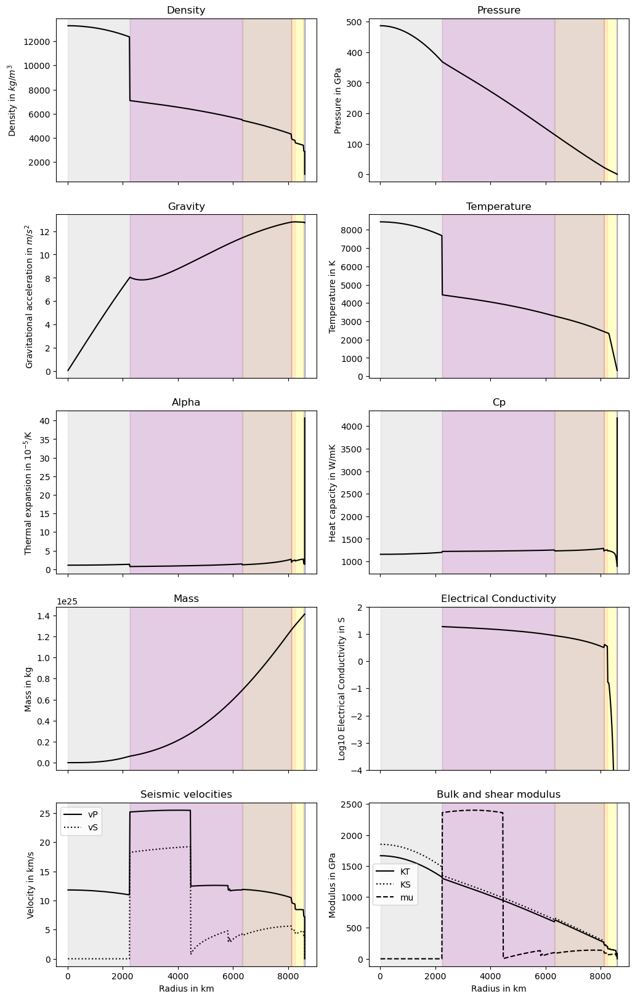

In [40]:
# To Kepler-442 b
if __name__ == "__main__":
    mass_obs = 2.36
    radius_obs = 1.34
    temp_obs = 316
    
    P_p=1.75*10**5
    mass_err=0.2*mass_obs
    radius_err=0.18
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [62]:
mass_obs = 2.36
radius_obs = 1.34
temp_obs = 316
    
P_p=1.75*10**5

In [63]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 11.5, 0.125, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

7680.021705507703 4442.40267343793 2244171.6887202994 12975.735106128092 1171.841689942327 7680.021705507703


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.483 R_E, M=3.3023 M_E, χ²=0.0900
[2/216] Fe=10, H2O=5 -> R=1.530 R_E, M=3.3151 M_E, χ²=0.0616
[3/216] Fe=10, H2O=10 -> R=1.559 R_E, M=3.3141 M_E, χ²=0.0439
[4/216] Fe=10, H2O=15 -> R=1.585 R_E, M=3.3137 M_E, χ²=0.0286
[5/216] Fe=10, H2O=20 -> R=1.607 R_E, M=3.3135 M_E, χ²=0.0160
[6/216] Fe=10, H2O=25 -> R=1.626 R_E, M=3.3134 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 25.0000 wt%
χ² mínimo = 0.0075
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=25.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 21.2500 to 28.7500 (step=0.3750)
Total number of combinations: 7 × 21 = 147
Testing 147 combinations.
[1/147] Fe=8.5, H2O=21.25 -> R=1.616 R_E, M=3.3128 M_E, χ²=0.0109
[2/147] Fe=8.5, H2O=21.625 -> R=1.618 R_E, M=3.3128 M_E, χ²=0.0102
[3/147] Fe=8.5, H2O=22.0 -> R=1.619 R_E, M=3.3128 M_E, χ²=0.0096
[4/147] 

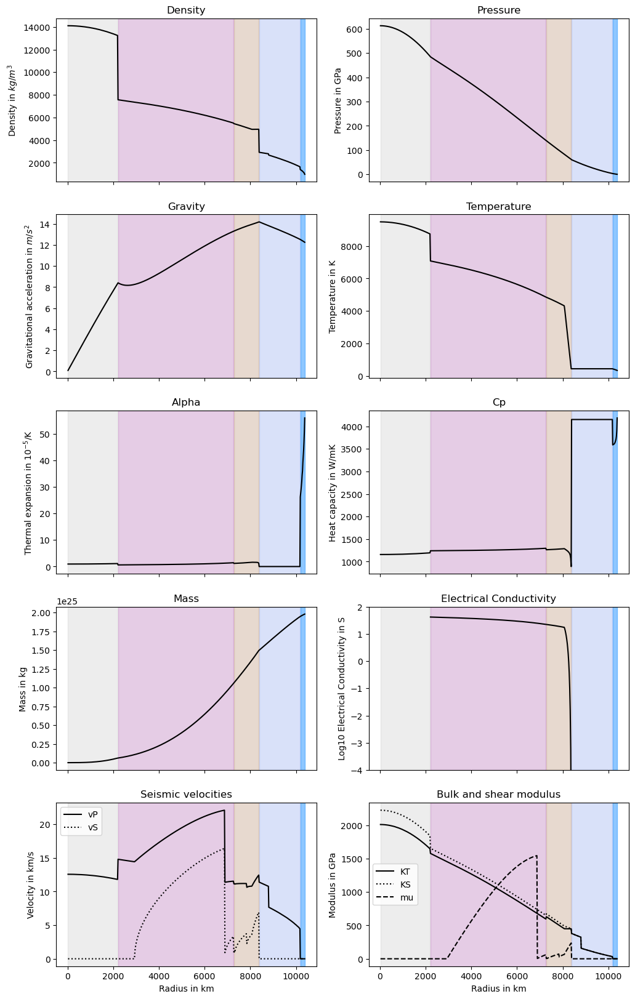

In [43]:
# To  Kepler-452 b
if __name__ == "__main__":
    mass_obs = 3.29
    radius_obs = 1.63
    temp_obs = 339
    
    P_p=1.55*10**5
    mass_err=0.2*mass_obs
    radius_err=0.23
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [64]:
mass_obs = 3.29
radius_obs = 1.63
temp_obs = 339
    
P_p=1.55*10**5

In [65]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 24.625 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8748.67431897925 7081.851962608501 2189495.826372799 13819.03128729095 1170.0156952051825 8748.67431897925


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.420 R_E, M=2.8104 M_E, χ²=0.0406
[2/216] Fe=10, H2O=5 -> R=1.465 R_E, M=2.8213 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 5.0000 wt%
χ² mínimo = 0.0125
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=5.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 4.2500 to 5.7500 (step=0.0750)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=4.25 -> R=1.465 R_E, M=2.8211 M_E, χ²=0.0127
[2/154] Fe=8.5, H2O=4.325 -> R=1.466 R_E, M=2.8209 M_E, χ²=0.0122
[3/154] Fe=8.5, H2O=4.4 -> R=1.466 R_E, M=2.8210 M_E, χ²=0.0119
[4/154] Fe=8.5, H2O=4.4750000000000005 -> R=1.466 R_E, M=2.8208 M_E, χ²=0.0118
[5/154] Fe=8.5, H2O=4.550000000000001 -> R=1.467 R_E, M=2.8209 M_E, χ²=0.0115
[6/154] Fe=8.5, H2O=4.625000000000001 -> R=1.468 R_E, M=2.8211 M_E, χ²=0.0112
[7/154] Fe=8.5, H2O=4.700000

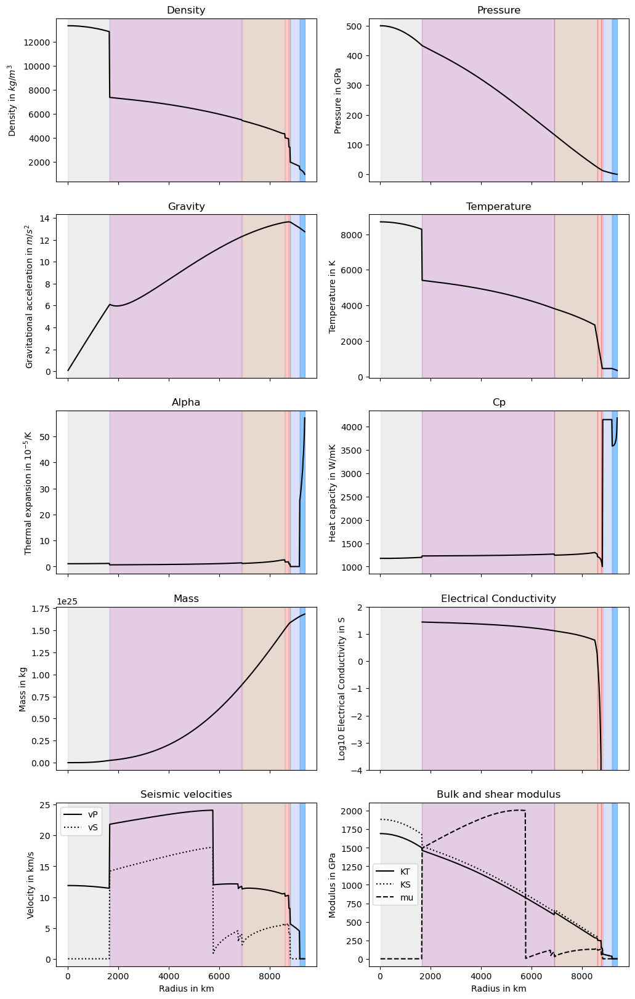

In [46]:
# To  L 98-59 f
if __name__ == "__main__":
    mass_obs = 2.8
    radius_obs = 1.48
    temp_obs = 341
    
    P_p=1.66*10**5
    mass_err=0.3
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [66]:
mass_obs = 2.8
radius_obs = 1.48
temp_obs = 341
    
P_p=1.66*10**5

In [67]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 5.825, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8282.414020922966 5408.674389388355 1652826.3947165937 13186.924106727314 1183.2066790390172 8282.414020922966


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.705 R_E, M=5.6213 M_E, χ²=0.0151
[2/216] Fe=10, H2O=5 -> R=1.760 R_E, M=5.6437 M_E, χ²=0.0189
[3/216] Fe=10, H2O=10 -> R=1.792 R_E, M=5.6418 M_E, χ²=0.0366
[4/216] Fe=10, H2O=15 -> R=1.817 R_E, M=5.6408 M_E, χ²=0.0510
[5/216] Fe=10, H2O=20 -> R=1.841 R_E, M=5.6406 M_E, χ²=0.0644
[6/216] Fe=10, H2O=25 -> R=1.863 R_E, M=5.6406 M_E, χ²=0.0775
[7/216] Fe=10, H2O=30 -> R=1.885 R_E, M=5.6404 M_E, χ²=0.0900
[8/216] Fe=10, H2O=35 -> R=1.907 R_E, M=5.6404 M_E, χ²=0.1025
[9/216] Fe=10, H2O=40 -> R=1.928 R_E, M=5.6402 M_E, χ²=0.1148
[10/216] Fe=10, H2O=45 -> R=1.949 R_E, M=5.6400 M_E, χ²=0.1268
[11/216] Fe=10, H2O=50 -> R=1.969 R_E, M=5.6396 M_E, χ²=0.1385
[12/216] Fe=10, H2O=55 -> R=1.989 R_E, M=5.6392 M_E, χ²=0.1500
[13/216] Fe=10, H2O=60 -> R=2.009 R_E, M=5.6386 M_E, χ²=0.1615
[14/216] Fe=10, H2O=65 -> R=2.028 R_E, M=5.6379 M_E, χ²=0.1726
[15/216] Fe=10, H2O=70 -> R=2.048 R_E, M=5.6370 M_E, χ²=0.1837
[16/216] Fe=10, H2

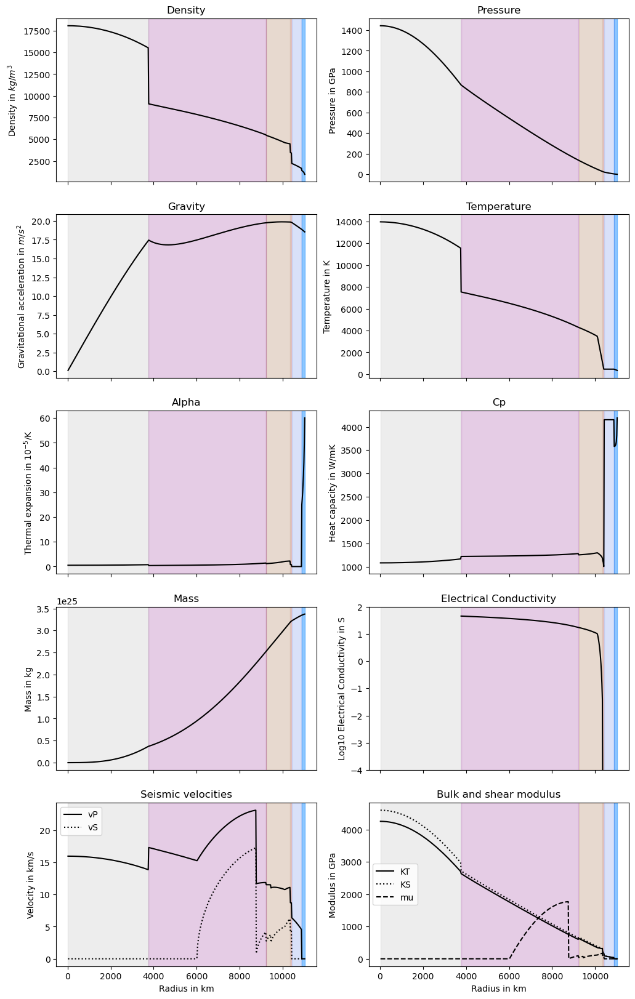

In [49]:
# To  LHS 1140 b
if __name__ == "__maian__":
    mass_obs = 5.6
    radius_obs = 1.73
    temp_obs = 346
    
    P_p=3.55*10**5
    mass_err=0.19
    radius_err=0.025
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [68]:
mass_obs = 5.6
radius_obs = 1.73
temp_obs = 346

P_p=3.55*10**5

In [69]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 17.25, 4.70 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

11560.829944562804 7537.997947275904 3748831.9597879397 17224.832202514353 1107.6296164410624 11560.829944562804


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.081 R_E, M=1.0588 M_E, χ²=0.0601
[2/216] Fe=10, H2O=5 -> R=1.114 R_E, M=1.0625 M_E, χ²=0.0926
[3/216] Fe=10, H2O=10 -> R=1.135 R_E, M=1.0624 M_E, χ²=0.1131
[4/216] Fe=10, H2O=15 -> R=1.154 R_E, M=1.0624 M_E, χ²=0.1319
[5/216] Fe=10, H2O=20 -> R=1.173 R_E, M=1.0624 M_E, χ²=0.1502
[6/216] Fe=10, H2O=25 -> R=1.190 R_E, M=1.0624 M_E, χ²=0.1669
[7/216] Fe=10, H2O=30 -> R=1.205 R_E, M=1.0624 M_E, χ²=0.1817
[8/216] Fe=10, H2O=35 -> R=1.220 R_E, M=1.0624 M_E, χ²=0.1962
[9/216] Fe=10, H2O=40 -> R=1.235 R_E, M=1.0623 M_E, χ²=0.2107
[10/216] Fe=10, H2O=45 -> R=1.249 R_E, M=1.0623 M_E, χ²=0.2244
[11/216] Fe=10, H2O=50 -> R=1.262 R_E, M=1.0622 M_E, χ²=0.2376
[12/216] Fe=10, H2O=55 -> R=1.275 R_E, M=1.0622 M_E, χ²=0.2499
[13/216] Fe=10, H2O=60 -> R=1.287 R_E, M=1.0621 M_E, χ²=0.2619
[14/216] Fe=10, H2O=65 -> R=1.299 R_E, M=1.0620 M_E, χ²=0.2736
[15/216] Fe=10, H2O=70 -> R=1.311 R_E, M=1.0618 M_E, χ²=0.2850
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_24996\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.036 R_E, M=1.0605 M_E, χ²=0.0164
[74/216] Fe=30, H2O=5 -> R=1.070 R_E, M=1.0636 M_E, χ²=0.0496
[75/216] Fe=30, H2O=10 -> R=1.092 R_E, M=1.0636 M_E, χ²=0.0711
[76/216] Fe=30, H2O=15 -> R=1.113 R_E, M=1.0636 M_E, χ²=0.0911
[77/216] Fe=30, H2O=20 -> R=1.132 R_E, M=1.0637 M_E, χ²=0.1096
[78/216] Fe=30, H2O=25 -> R=1.148 R_E, M=1.0637 M_E, χ²=0.1255
[79/216] Fe=30, H2O=30 -> R=1.164 R_E, M=1.0637 M_E, χ²=0.1414
[80/216] Fe=30, H2O=35 -> R=1.180 R_E, M=1.0637 M_E, χ²=0.1568
[81/216] Fe=30, H2O=40 -> R=1.194 R_E, M=1.0637 M_E, χ²=0.1712
[82/216] Fe=30, H2O=45 -> R=1.208 R_E, M=1.0637 M_E, χ²=0.1842
[83/216] Fe=30, H2O=50 -> R=1.221 R_E, M=1.0636 M_E, χ²=0.1968
[84/216] Fe=30, H2O=55 -> R=1.233 R_E, M=1.0634 M_E, χ²=0.2092
[85/216] Fe=30, H2O=60 -> R=1.246 R_E, M=1.0633 M_E, χ²=0.2213
[86/216] Fe=30, H2O=65 -> R=1.258 R_E, M=1.0631 M_E, χ²=0.2333
[87/216] Fe=30, H2O=70 -> R=1.269 R_E, M=1.0626 M_E, χ²=0.2438
[88/216] Fe=30, H2O=75 -> R=1.295 R_E, M=0.9920 M_E, χ²=0

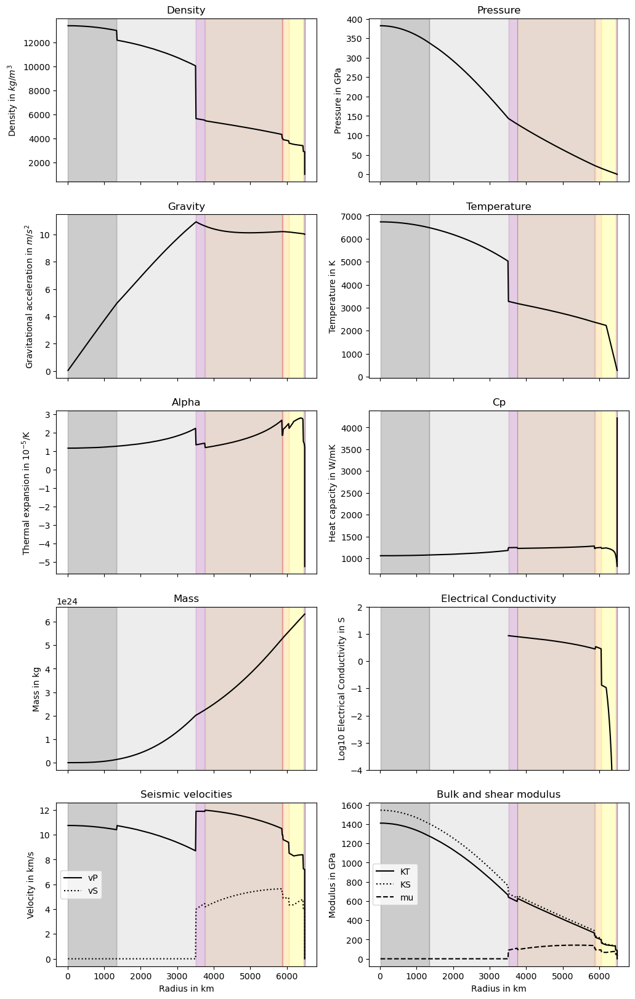

In [9]:
# To Proxima Cen b  
if __name__ == "__main__":
    mass_obs = 1.055
    radius_obs = 1.02
    temp_obs = 274
    
    P_p=1.04*10**5
    mass_err=0.055
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [70]:
mass_obs = 1.055
radius_obs = 1.02
temp_obs = 274
    
P_p=1.04*10**5

In [71]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 36.75, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5026.9287114236995 3275.4244226957967 2147412.0588143915 11280.48544259486 1119.7846704211674 5026.9287114236995


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.172 R_E, M=1.4051 M_E, χ²=0.0560
[2/216] Fe=10, H2O=5 -> R=1.212 R_E, M=1.4106 M_E, χ²=0.0922
[3/216] Fe=10, H2O=10 -> R=1.235 R_E, M=1.4102 M_E, χ²=0.1132
[4/216] Fe=10, H2O=15 -> R=1.257 R_E, M=1.4100 M_E, χ²=0.1323
[5/216] Fe=10, H2O=20 -> R=1.276 R_E, M=1.4100 M_E, χ²=0.1497
[6/216] Fe=10, H2O=25 -> R=1.293 R_E, M=1.4100 M_E, χ²=0.1649
[7/216] Fe=10, H2O=30 -> R=1.310 R_E, M=1.4099 M_E, χ²=0.1807
[8/216] Fe=10, H2O=35 -> R=1.327 R_E, M=1.4099 M_E, χ²=0.1953
[9/216] Fe=10, H2O=40 -> R=1.342 R_E, M=1.4099 M_E, χ²=0.2090
[10/216] Fe=10, H2O=45 -> R=1.356 R_E, M=1.4098 M_E, χ²=0.2214
[11/216] Fe=10, H2O=50 -> R=1.369 R_E, M=1.4097 M_E, χ²=0.2335
[12/216] Fe=10, H2O=55 -> R=1.382 R_E, M=1.4096 M_E, χ²=0.2455
[13/216] Fe=10, H2O=60 -> R=1.396 R_E, M=1.4094 M_E, χ²=0.2573
[14/216] Fe=10, H2O=65 -> R=1.408 R_E, M=1.4093 M_E, χ²=0.2690
[15/216] Fe=10, H2O=70 -> R=1.421 R_E, M=1.4091 M_E, χ²=0.2804
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_24996\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.122 R_E, M=1.4074 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0123
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.134 R_E, M=1.4070 M_E, χ²=0.0218
[2/77] Fe=25.5, H2O=0.025 -> R=1.133 R_E, M=1.4067 M_E, χ²=0.0211
[3/77] Fe=25.5, H2O=0.05 -> R=1.133 R_E, M=1.4063 M_E, χ²=0.0210
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.133 R_E, M=1.4060 M_E, χ²=0.0208
[5/77] Fe=25.5, H2O=0.1 -> R=1.133 R_E, M=1.4056 M_E, χ²=0.0207
[6/77] Fe=25.5, H2O=0.125 -> R=1.132 R_E, M=1.4053 M_E, χ²=0.0206
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.136 R_E, M=1.4111 M_E, χ²=0.0250
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.137 R_E, M=1.4117 M_E, χ²=0.0256
[9

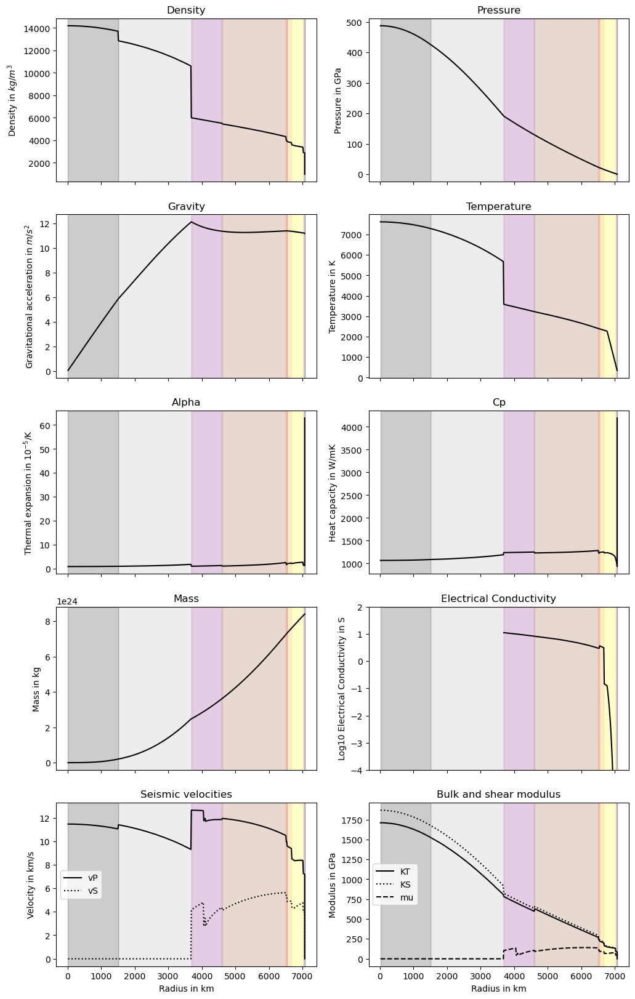

In [12]:
# To  Ross 128 b
if __name__ == "__main__":
    mass_obs = 1.4
    radius_obs = 1.11
    temp_obs = 351
    
    P_p=1.31*10**5
    mass_err=0.21
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [72]:
mass_obs = 1.4
radius_obs = 1.11
temp_obs = 351
    
P_p=1.31*10**5

In [73]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.1, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5677.207817695816 3588.182497086219 2159091.041406229 11905.907316032271 1128.0454574199591 5677.207817695816


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.562 R_E, M=4.0150 M_E, χ²=0.1462
[2/216] Fe=10, H2O=5 -> R=1.612 R_E, M=4.0308 M_E, χ²=0.1193
[3/216] Fe=10, H2O=10 -> R=1.642 R_E, M=4.0295 M_E, χ²=0.1028
[4/216] Fe=10, H2O=15 -> R=1.669 R_E, M=4.0289 M_E, χ²=0.0884
[5/216] Fe=10, H2O=20 -> R=1.690 R_E, M=4.0287 M_E, χ²=0.0766
[6/216] Fe=10, H2O=25 -> R=1.710 R_E, M=4.0286 M_E, χ²=0.0657
[7/216] Fe=10, H2O=30 -> R=1.730 R_E, M=4.0285 M_E, χ²=0.0551
[8/216] Fe=10, H2O=35 -> R=1.749 R_E, M=4.0285 M_E, χ²=0.0447
[9/216] Fe=10, H2O=40 -> R=1.768 R_E, M=4.0284 M_E, χ²=0.0347
[10/216] Fe=10, H2O=45 -> R=1.787 R_E, M=4.0282 M_E, χ²=0.0248
[11/216] Fe=10, H2O=50 -> R=1.805 R_E, M=4.0280 M_E, χ²=0.0154
[12/216] Fe=10, H2O=55 -> R=1.823 R_E, M=4.0277 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 55.0000 wt%
χ² mínimo = 0.0079
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000

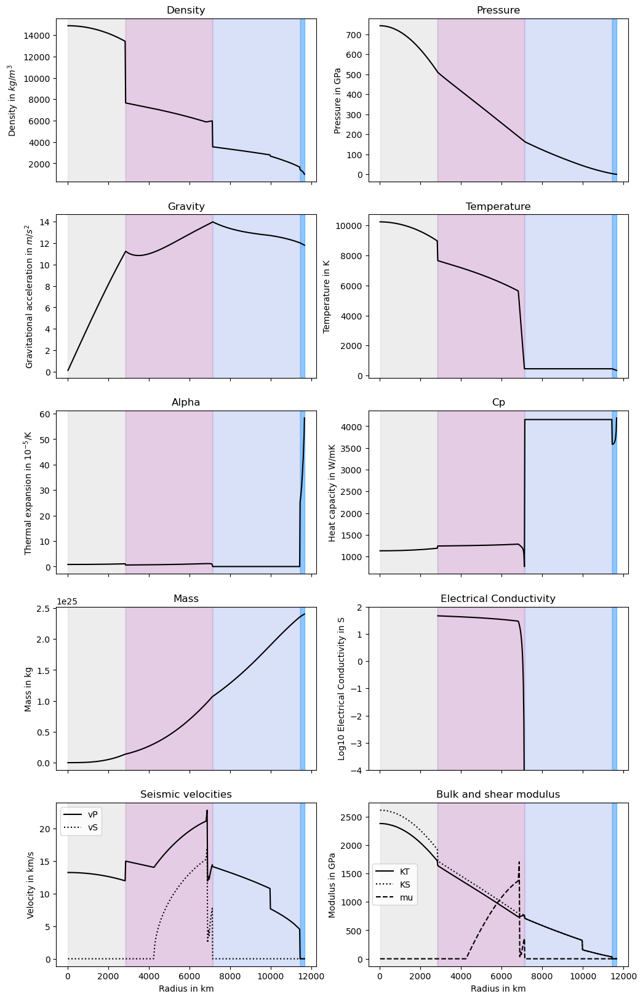

In [15]:
# Para  Ross 508 b
if __name__ == "__main__":
    mass_obs = 4
    radius_obs = 1.83
    temp_obs = 343
    
    P_p=1.45*10**5
    mass_err=0.55
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [74]:
mass_obs = 4
radius_obs = 1.83
temp_obs = 343
    
P_p=1.45*10**5

In [75]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5, 52.825, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

9060.713704872705 7657.258738829632 2795007.802630218 14441.571273235475 1153.456198567383 9060.713704872705


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.528 R_E, M=3.6938 M_E, χ²=0.1217
[2/216] Fe=10, H2O=5 -> R=1.577 R_E, M=3.7081 M_E, χ²=0.0943
[3/216] Fe=10, H2O=10 -> R=1.606 R_E, M=3.7071 M_E, χ²=0.0773
[4/216] Fe=10, H2O=15 -> R=1.633 R_E, M=3.7065 M_E, χ²=0.0621
[5/216] Fe=10, H2O=20 -> R=1.654 R_E, M=3.7063 M_E, χ²=0.0499
[6/216] Fe=10, H2O=25 -> R=1.674 R_E, M=3.7062 M_E, χ²=0.0386
[7/216] Fe=10, H2O=30 -> R=1.693 R_E, M=3.7061 M_E, χ²=0.0280
[8/216] Fe=10, H2O=35 -> R=1.712 R_E, M=3.7061 M_E, χ²=0.0178
[9/216] Fe=10, H2O=40 -> R=1.730 R_E, M=3.7060 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 40.0000 wt%
χ² mínimo = 0.0091
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=40.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 34.0000 to 46.0000 (step=0.6000)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=

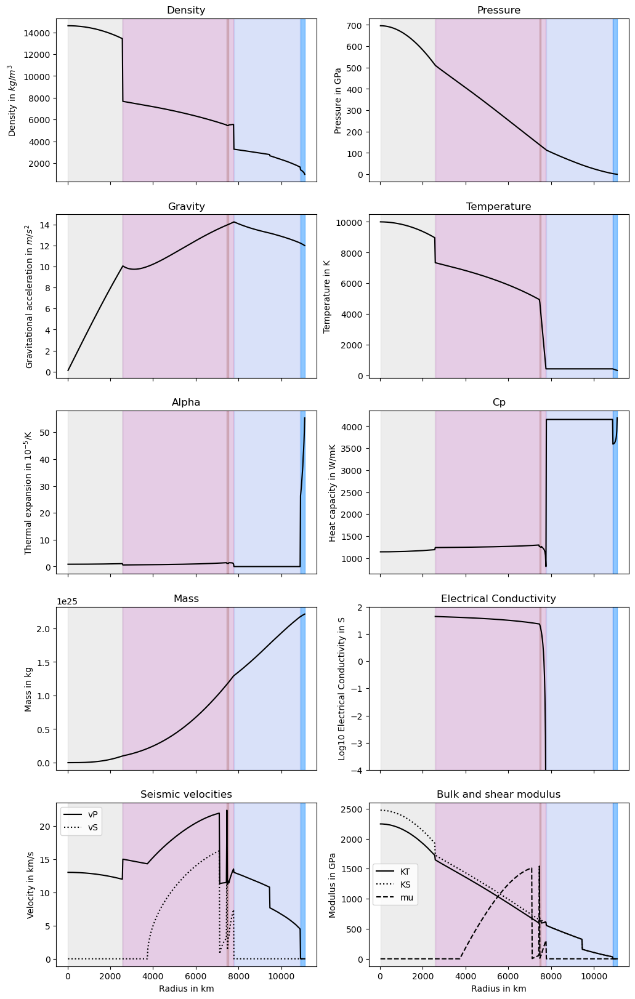

In [18]:
# To  TOI-1266 d
if __name__ == "__main__":
    mass_obs = 3.68
    radius_obs = 1.74
    temp_obs = 338
    
    P_p=1.5*10**5
    mass_err=1.11
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")



visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [76]:
mass_obs = 3.68
radius_obs = 1.74
temp_obs = 338
    
P_p=1.5*10**5

In [77]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.5,41.8 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8969.647988199922 7342.75081370135 2564565.832771168 14216.19348436285 1159.9218189778223 8969.647988199922


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.135 R_E, M=1.2546 M_E, χ²=0.0579
[2/216] Fe=10, H2O=5 -> R=1.172 R_E, M=1.2592 M_E, χ²=0.0923
[3/216] Fe=10, H2O=10 -> R=1.194 R_E, M=1.2589 M_E, χ²=0.1127
[4/216] Fe=10, H2O=15 -> R=1.215 R_E, M=1.2588 M_E, χ²=0.1321
[5/216] Fe=10, H2O=20 -> R=1.234 R_E, M=1.2588 M_E, χ²=0.1498
[6/216] Fe=10, H2O=25 -> R=1.250 R_E, M=1.2588 M_E, χ²=0.1654
[7/216] Fe=10, H2O=30 -> R=1.266 R_E, M=1.2588 M_E, χ²=0.1803
[8/216] Fe=10, H2O=35 -> R=1.283 R_E, M=1.2588 M_E, χ²=0.1955
[9/216] Fe=10, H2O=40 -> R=1.298 R_E, M=1.2588 M_E, χ²=0.2095
[10/216] Fe=10, H2O=45 -> R=1.312 R_E, M=1.2587 M_E, χ²=0.2227
[11/216] Fe=10, H2O=50 -> R=1.325 R_E, M=1.2586 M_E, χ²=0.2349
[12/216] Fe=10, H2O=55 -> R=1.338 R_E, M=1.2585 M_E, χ²=0.2469
[13/216] Fe=10, H2O=60 -> R=1.350 R_E, M=1.2584 M_E, χ²=0.2586
[14/216] Fe=10, H2O=65 -> R=1.363 R_E, M=1.2583 M_E, χ²=0.2703
[15/216] Fe=10, H2O=70 -> R=1.375 R_E, M=1.2581 M_E, χ²=0.2814
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_24996\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.087 R_E, M=1.2566 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0141
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.098 R_E, M=1.2562 M_E, χ²=0.0238
[2/77] Fe=25.5, H2O=0.025 -> R=1.097 R_E, M=1.2559 M_E, χ²=0.0230
[3/77] Fe=25.5, H2O=0.05 -> R=1.097 R_E, M=1.2556 M_E, χ²=0.0229
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.097 R_E, M=1.2553 M_E, χ²=0.0228
[5/77] Fe=25.5, H2O=0.1 -> R=1.097 R_E, M=1.2550 M_E, χ²=0.0226
[6/77] Fe=25.5, H2O=0.125 -> R=1.097 R_E, M=1.2547 M_E, χ²=0.0225
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.100 R_E, M=1.2597 M_E, χ²=0.0267
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.101 R_E, M=1.2603 M_E, χ²=0.0273
[9

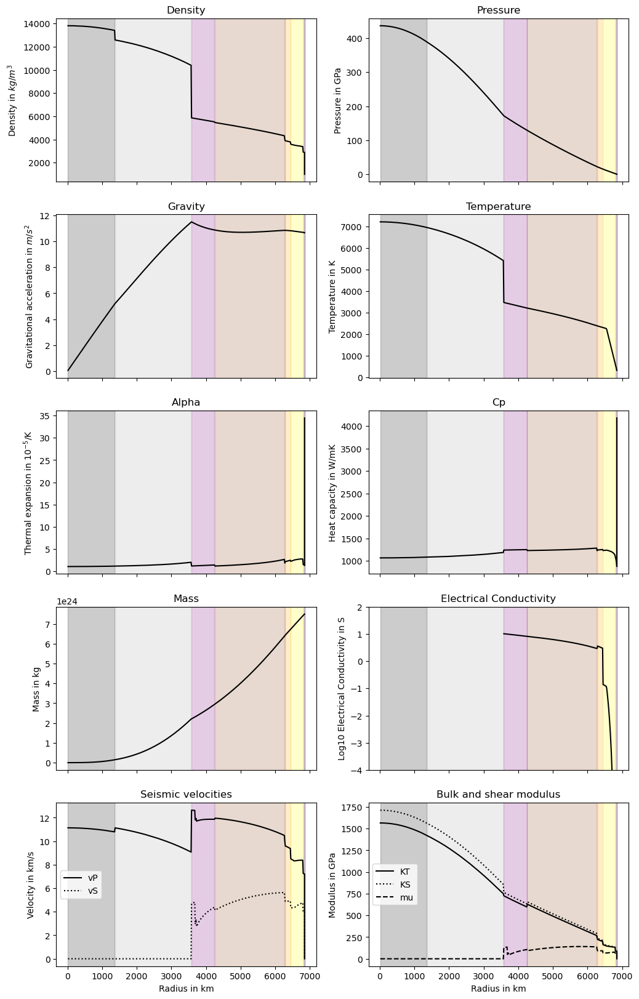

In [21]:
# To  TOI-700 d
if __name__ == "__main__":
    
    mass_obs = 1.25
    radius_obs = 1.073
    temp_obs = 308
    
    P_p=1.2*10**5
    mass_err=0.2*mass_obs
    radius_err=0.032
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)     
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [78]:
mass_obs = 1.25
radius_obs = 1.073
temp_obs = 308
    
P_p=1.2*10**5

In [79]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50,0.10 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5419.702366092569 3470.2216506331056 2195001.463651671 11669.204089546256 1124.599547502815 5419.702366092569


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.005 R_E, M=0.8210 M_E, χ²=0.0543
[2/216] Fe=10, H2O=5 -> R=1.039 R_E, M=0.8241 M_E, χ²=0.0910
[3/216] Fe=10, H2O=10 -> R=1.060 R_E, M=0.8239 M_E, χ²=0.1126
[4/216] Fe=10, H2O=15 -> R=1.077 R_E, M=0.8238 M_E, χ²=0.1308
[5/216] Fe=10, H2O=20 -> R=1.094 R_E, M=0.8238 M_E, χ²=0.1482
[6/216] Fe=10, H2O=25 -> R=1.111 R_E, M=0.8238 M_E, χ²=0.1655
[7/216] Fe=10, H2O=30 -> R=1.126 R_E, M=0.8238 M_E, χ²=0.1818
[8/216] Fe=10, H2O=35 -> R=1.141 R_E, M=0.8238 M_E, χ²=0.1970
[9/216] Fe=10, H2O=40 -> R=1.153 R_E, M=0.8238 M_E, χ²=0.2104
[10/216] Fe=10, H2O=45 -> R=1.167 R_E, M=0.8237 M_E, χ²=0.2248
[11/216] Fe=10, H2O=50 -> R=1.180 R_E, M=0.8237 M_E, χ²=0.2387
[12/216] Fe=10, H2O=55 -> R=1.193 R_E, M=0.8236 M_E, χ²=0.2520
[13/216] Fe=10, H2O=60 -> R=1.205 R_E, M=0.8235 M_E, χ²=0.2650
[14/216] Fe=10, H2O=65 -> R=1.217 R_E, M=0.8234 M_E, χ²=0.2776
[15/216] Fe=10, H2O=70 -> R=1.229 R_E, M=0.8233 M_E, χ²=0.2894
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_24996\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=0.963 R_E, M=0.8222 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0117
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=0.973 R_E, M=0.8220 M_E, χ²=0.0212
[2/77] Fe=25.5, H2O=0.025 -> R=0.972 R_E, M=0.8218 M_E, χ²=0.0205
[3/77] Fe=25.5, H2O=0.05 -> R=0.972 R_E, M=0.8216 M_E, χ²=0.0204
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=0.972 R_E, M=0.8214 M_E, χ²=0.0203
[5/77] Fe=25.5, H2O=0.1 -> R=0.972 R_E, M=0.8212 M_E, χ²=0.0201
[6/77] Fe=25.5, H2O=0.125 -> R=0.972 R_E, M=0.8210 M_E, χ²=0.0200
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=0.975 R_E, M=0.8241 M_E, χ²=0.0240
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=0.975 R_E, M=0.8245 M_E, χ²=0.0246
[9

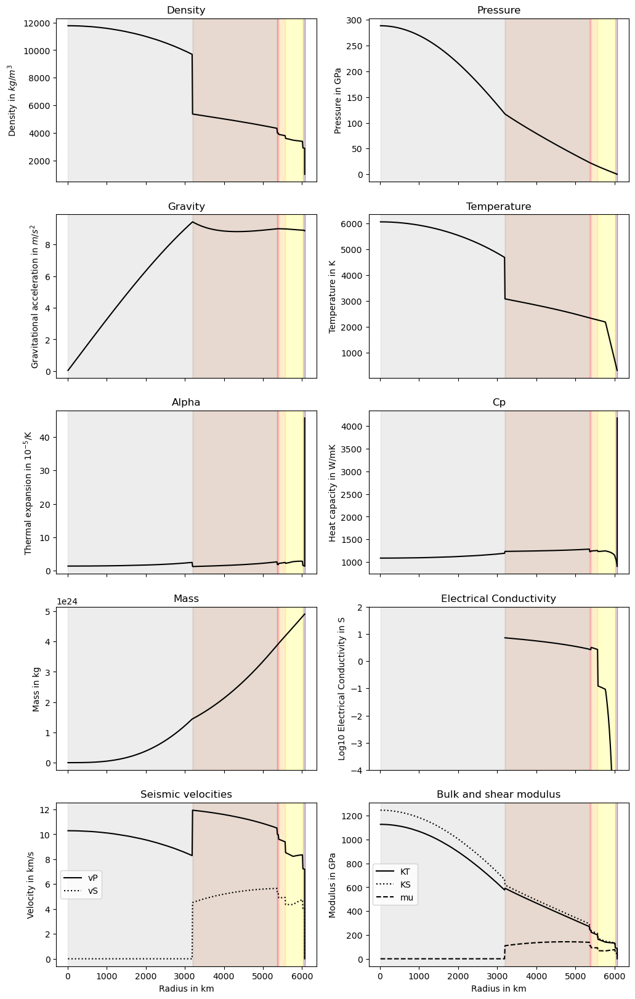

In [24]:
# To  TOI-700 e 
if __name__ == "__main__":
    mass_obs = 0.818
    radius_obs = 0.953
    temp_obs = 323
    
    P_p=0.82*10**5
    
    mass_err=0.2*mass_obs
    radius_err=0.028
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)     

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [80]:
mass_obs = 0.818
radius_obs = 0.953
temp_obs = 323
    
P_p=0.82*10**5

In [81]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

4688.537915146329 3085.907814358555 3186988.8616269343 11097.504649385688 1115.9073109086953 4688.537915146329


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.450 R_E, M=3.0312 M_E, χ²=0.0648
[2/216] Fe=10, H2O=5 -> R=1.494 R_E, M=3.0427 M_E, χ²=0.0370
[3/216] Fe=10, H2O=10 -> R=1.524 R_E, M=3.0420 M_E, χ²=0.0184
[4/216] Fe=10, H2O=15 -> R=1.547 R_E, M=3.0416 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 15.0000 wt%
χ² mínimo = 0.0073
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=15.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 12.7500 to 17.2500 (step=0.2250)
Total number of combinations: 7 × 22 = 154
Testing 154 combinations.
[1/154] Fe=8.5, H2O=12.75 -> R=1.541 R_E, M=3.0412 M_E, χ²=0.0091
[2/154] Fe=8.5, H2O=12.975 -> R=1.542 R_E, M=3.0412 M_E, χ²=0.0086
[3/154] Fe=8.5, H2O=13.2 -> R=1.543 R_E, M=3.0411 M_E, χ²=0.0083
[4/154] Fe=8.5, H2O=13.424999999999999 -> R=1.544 R_E, M=3.0411 M_E, χ²=0.0079
[5/154] Fe=8.5, H2O=13.649999999999999 -> R=1.545 R_E

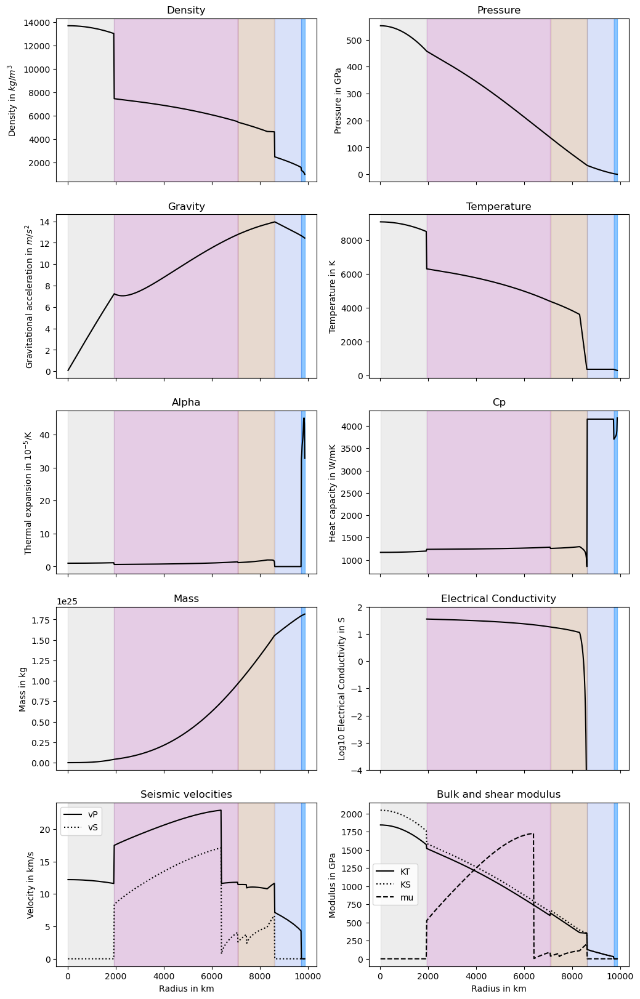

In [27]:
# To  TOI-715 b
if __name__ == "__main__":
    mass_obs = 3.02
    radius_obs = 1.55
    temp_obs = 306
    
    P_p=1.6*10**5
    mass_err=0.2*mass_obs
    radius_err=0.064
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [82]:
mass_obs = 3.02
radius_obs = 1.55
temp_obs = 306
    
P_p=1.6*10**5

In [83]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 14.55, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8507.00145016438 6300.5480803511855 1924238.9241989919 13489.00214022731 1176.9275270155429 8507.00145016438


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.111 R_E, M=1.1642 M_E, χ²=0.0582
[2/216] Fe=10, H2O=5 -> R=1.150 R_E, M=1.1688 M_E, χ²=0.0959
[3/216] Fe=10, H2O=10 -> R=1.172 R_E, M=1.1684 M_E, χ²=0.1164
[4/216] Fe=10, H2O=15 -> R=1.192 R_E, M=1.1683 M_E, χ²=0.1358
[5/216] Fe=10, H2O=20 -> R=1.211 R_E, M=1.1683 M_E, χ²=0.1537
[6/216] Fe=10, H2O=25 -> R=1.229 R_E, M=1.1683 M_E, χ²=0.1703
[7/216] Fe=10, H2O=30 -> R=1.244 R_E, M=1.1682 M_E, χ²=0.1847
[8/216] Fe=10, H2O=35 -> R=1.260 R_E, M=1.1682 M_E, χ²=0.1998
[9/216] Fe=10, H2O=40 -> R=1.275 R_E, M=1.1682 M_E, χ²=0.2142
[10/216] Fe=10, H2O=45 -> R=1.289 R_E, M=1.1681 M_E, χ²=0.2281
[11/216] Fe=10, H2O=50 -> R=1.303 R_E, M=1.1681 M_E, χ²=0.2407
[12/216] Fe=10, H2O=55 -> R=1.315 R_E, M=1.1680 M_E, χ²=0.2527
[13/216] Fe=10, H2O=60 -> R=1.328 R_E, M=1.1678 M_E, χ²=0.2647
[14/216] Fe=10, H2O=65 -> R=1.340 R_E, M=1.1677 M_E, χ²=0.2765
[15/216] Fe=10, H2O=70 -> R=1.352 R_E, M=1.1675 M_E, χ²=0.2881
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_24996\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.064 R_E, M=1.1661 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0144
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.075 R_E, M=1.1658 M_E, χ²=0.0243
[2/77] Fe=25.5, H2O=0.025 -> R=1.074 R_E, M=1.1655 M_E, χ²=0.0235
[3/77] Fe=25.5, H2O=0.05 -> R=1.074 R_E, M=1.1652 M_E, χ²=0.0234
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.074 R_E, M=1.1649 M_E, χ²=0.0232
[5/77] Fe=25.5, H2O=0.1 -> R=1.074 R_E, M=1.1646 M_E, χ²=0.0231
[6/77] Fe=25.5, H2O=0.125 -> R=1.074 R_E, M=1.1643 M_E, χ²=0.0230
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.077 R_E, M=1.1690 M_E, χ²=0.0271
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.078 R_E, M=1.1696 M_E, χ²=0.0277
[9

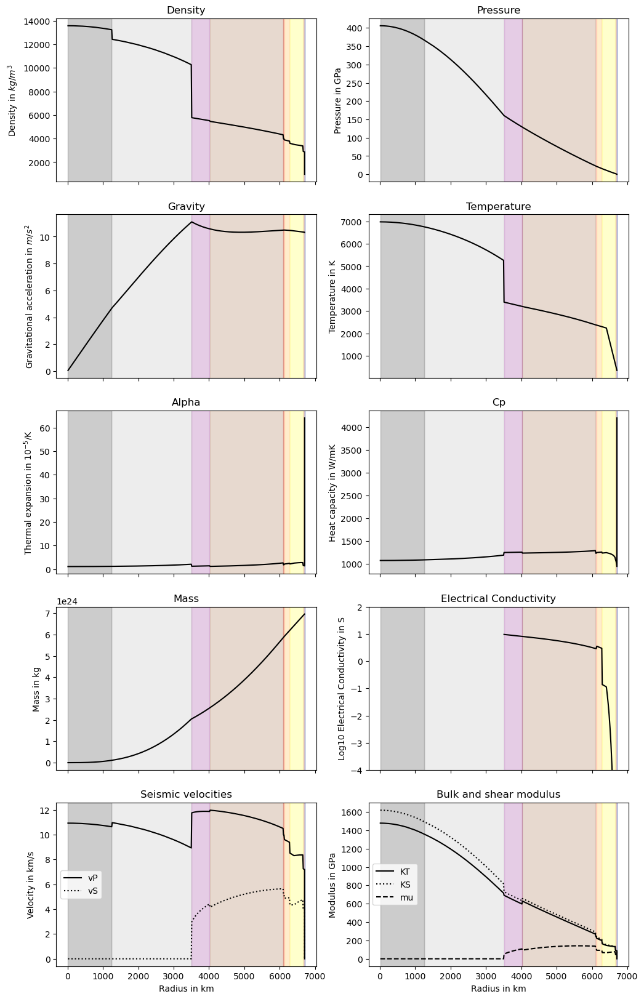

In [30]:
# To  Teegarden's Star b
if __name__ == "__main__":
    
    # Seus dados observados
    mass_obs = 1.16
    radius_obs = 1.05
    temp_obs = 353
    
    P_p=1.12*10**5
    mass_err=0.12
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [84]:
mass_obs = 1.16
radius_obs = 1.05
temp_obs = 353
    
P_p=1.12*10**5

In [85]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 34.50,0.1 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5261.527244483774 3397.8321198891626 2235415.0593215935 11526.963692003677 1122.1900355443377 5261.527244483774


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.080 R_E, M=1.0538 M_E, χ²=0.0587
[2/216] Fe=10, H2O=5 -> R=1.113 R_E, M=1.0575 M_E, χ²=0.0912
[3/216] Fe=10, H2O=10 -> R=1.134 R_E, M=1.0574 M_E, χ²=0.1119
[4/216] Fe=10, H2O=15 -> R=1.153 R_E, M=1.0573 M_E, χ²=0.1306
[5/216] Fe=10, H2O=20 -> R=1.171 R_E, M=1.0573 M_E, χ²=0.1487
[6/216] Fe=10, H2O=25 -> R=1.189 R_E, M=1.0573 M_E, χ²=0.1654
[7/216] Fe=10, H2O=30 -> R=1.204 R_E, M=1.0573 M_E, χ²=0.1802
[8/216] Fe=10, H2O=35 -> R=1.218 R_E, M=1.0573 M_E, χ²=0.1946
[9/216] Fe=10, H2O=40 -> R=1.233 R_E, M=1.0573 M_E, χ²=0.2091
[10/216] Fe=10, H2O=45 -> R=1.247 R_E, M=1.0573 M_E, χ²=0.2229
[11/216] Fe=10, H2O=50 -> R=1.261 R_E, M=1.0572 M_E, χ²=0.2361
[12/216] Fe=10, H2O=55 -> R=1.273 R_E, M=1.0571 M_E, χ²=0.2484
[13/216] Fe=10, H2O=60 -> R=1.285 R_E, M=1.0570 M_E, χ²=0.2604
[14/216] Fe=10, H2O=65 -> R=1.297 R_E, M=1.0569 M_E, χ²=0.2720
[15/216] Fe=10, H2O=70 -> R=1.309 R_E, M=1.0568 M_E, χ²=0.2834
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_7068\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.034 R_E, M=1.0555 M_E, χ²=0.0151
[74/216] Fe=30, H2O=5 -> R=1.069 R_E, M=1.0586 M_E, χ²=0.0484
[75/216] Fe=30, H2O=10 -> R=1.091 R_E, M=1.0586 M_E, χ²=0.0697
[76/216] Fe=30, H2O=15 -> R=1.111 R_E, M=1.0586 M_E, χ²=0.0897
[77/216] Fe=30, H2O=20 -> R=1.130 R_E, M=1.0586 M_E, χ²=0.1082
[78/216] Fe=30, H2O=25 -> R=1.146 R_E, M=1.0587 M_E, χ²=0.1242
[79/216] Fe=30, H2O=30 -> R=1.163 R_E, M=1.0587 M_E, χ²=0.1401
[80/216] Fe=30, H2O=35 -> R=1.178 R_E, M=1.0587 M_E, χ²=0.1554
[81/216] Fe=30, H2O=40 -> R=1.193 R_E, M=1.0586 M_E, χ²=0.1697
[82/216] Fe=30, H2O=45 -> R=1.206 R_E, M=1.0586 M_E, χ²=0.1827
[83/216] Fe=30, H2O=50 -> R=1.219 R_E, M=1.0585 M_E, χ²=0.1953
[84/216] Fe=30, H2O=55 -> R=1.232 R_E, M=1.0584 M_E, χ²=0.2077
[85/216] Fe=30, H2O=60 -> R=1.244 R_E, M=1.0582 M_E, χ²=0.2199
[86/216] Fe=30, H2O=65 -> R=1.256 R_E, M=1.0580 M_E, χ²=0.2318
[87/216] Fe=30, H2O=70 -> R=1.267 R_E, M=1.0576 M_E, χ²=0.2423
[88/216] Fe=30, H2O=75 -> R=1.293 R_E, M=0.9872 M_E, χ²=0

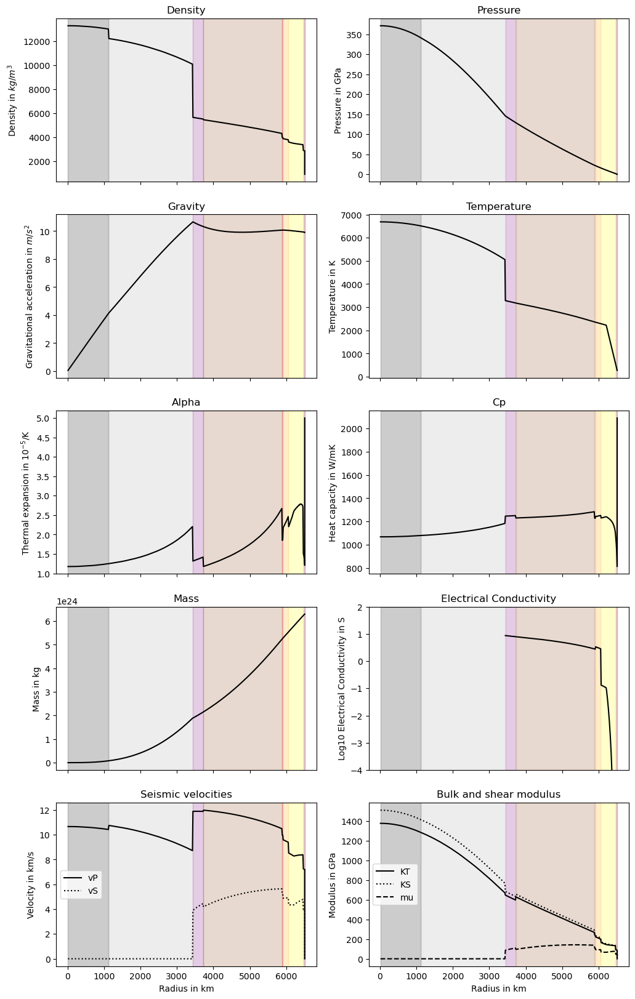

In [9]:
# To  Teegarden's Star c
if __name__ == "__main__":
    mass_obs = 1.05
    radius_obs = 1.02
    temp_obs = 273
    
    P_p=1.03*10**5
    mass_err=0.14
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [86]:
mass_obs = 1.05
radius_obs = 1.02
temp_obs = 273
    
P_p=1.03*10**5

In [87]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 35.0, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5056.48579516631 3285.6477574745263 2294424.6630223608 11344.521224596221 1119.077609013541 5056.48579516631


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.498 R_E, M=3.4227 M_E, χ²=0.0979
[2/216] Fe=10, H2O=5 -> R=1.546 R_E, M=3.4362 M_E, χ²=0.0691
[3/216] Fe=10, H2O=10 -> R=1.575 R_E, M=3.4352 M_E, χ²=0.0515
[4/216] Fe=10, H2O=15 -> R=1.601 R_E, M=3.4346 M_E, χ²=0.0364
[5/216] Fe=10, H2O=20 -> R=1.623 R_E, M=3.4344 M_E, χ²=0.0235
[6/216] Fe=10, H2O=25 -> R=1.642 R_E, M=3.4343 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 25.0000 wt%
χ² mínimo = 0.0128
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=25.0000
Range Fe: 8.5000 to 11.5000 (step=0.5000)
Range H2O: 21.2500 to 28.7500 (step=0.3750)
Total number of combinations: 7 × 21 = 147
Testing 147 combinations.
[1/147] Fe=8.5, H2O=21.25 -> R=1.633 R_E, M=3.4337 M_E, χ²=0.0180
[2/147] Fe=8.5, H2O=21.625 -> R=1.634 R_E, M=3.4337 M_E, χ²=0.0172
[3/147] Fe=8.5, H2O=22.0 -> R=1.635 R_E, M=3.4337 M_E, χ²=0.0163
[4/147] 

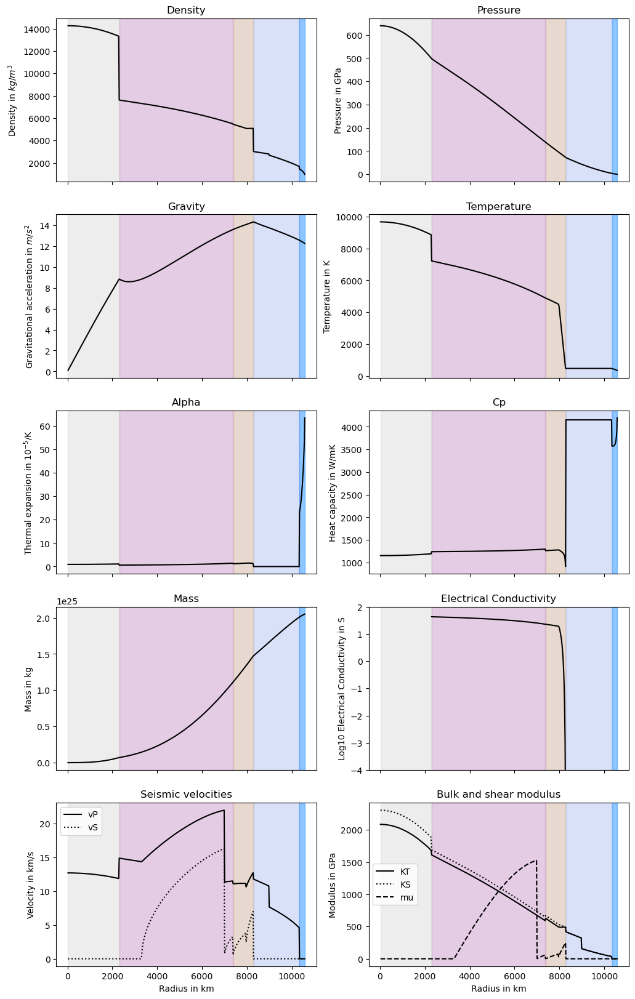

In [12]:
# To  Wolf 1061 c
if __name__ == "__main__":
    mass_obs = 3.41
    radius_obs = 1.66
    temp_obs = 352
    
    P_p=1.55*10**5
    mass_err=0.43
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)   

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [88]:
mass_obs = 3.41
radius_obs = 1.66
temp_obs = 352
    
P_p=1.55*10**5

In [89]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50,28.375 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8855.729468066147 7216.657168593409 2282498.8084766744 13956.654320572554 1167.3348100862424 8855.729468066147


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.138 R_E, M=1.2646 M_E, χ²=0.0534
[2/216] Fe=10, H2O=5 -> R=1.173 R_E, M=1.2691 M_E, χ²=0.0863
[3/216] Fe=10, H2O=10 -> R=1.195 R_E, M=1.2689 M_E, χ²=0.1067
[4/216] Fe=10, H2O=15 -> R=1.216 R_E, M=1.2688 M_E, χ²=0.1261
[5/216] Fe=10, H2O=20 -> R=1.235 R_E, M=1.2688 M_E, χ²=0.1437
[6/216] Fe=10, H2O=25 -> R=1.252 R_E, M=1.2689 M_E, χ²=0.1591
[7/216] Fe=10, H2O=30 -> R=1.268 R_E, M=1.2688 M_E, χ²=0.1739
[8/216] Fe=10, H2O=35 -> R=1.284 R_E, M=1.2688 M_E, χ²=0.1887
[9/216] Fe=10, H2O=40 -> R=1.299 R_E, M=1.2688 M_E, χ²=0.2026
[10/216] Fe=10, H2O=45 -> R=1.313 R_E, M=1.2687 M_E, χ²=0.2156
[11/216] Fe=10, H2O=50 -> R=1.326 R_E, M=1.2687 M_E, χ²=0.2278
[12/216] Fe=10, H2O=55 -> R=1.339 R_E, M=1.2686 M_E, χ²=0.2397
[13/216] Fe=10, H2O=60 -> R=1.351 R_E, M=1.2684 M_E, χ²=0.2513
[14/216] Fe=10, H2O=65 -> R=1.364 R_E, M=1.2683 M_E, χ²=0.2629
[15/216] Fe=10, H2O=70 -> R=1.376 R_E, M=1.2681 M_E, χ²=0.2743
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_7068\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[73/216] Fe=30, H2O=0 -> R=1.089 R_E, M=1.2666 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 30.0000 wt%
x_H2O_tot = 0.0000 wt%
χ² mínimo = 0.0101
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=30.0000, H2O=0.0000
Range Fe: 25.5000 to 34.5000 (step=1.5000)
Range H2O: 0.0000 to 0.2500 (step=0.0250)
Total number of combinations: 7 × 11 = 77
Testing 77 combinations.
[1/77] Fe=25.5, H2O=0.0 -> R=1.100 R_E, M=1.2663 M_E, χ²=0.0196
[2/77] Fe=25.5, H2O=0.025 -> R=1.100 R_E, M=1.2660 M_E, χ²=0.0188
[3/77] Fe=25.5, H2O=0.05 -> R=1.100 R_E, M=1.2657 M_E, χ²=0.0186
[4/77] Fe=25.5, H2O=0.07500000000000001 -> R=1.099 R_E, M=1.2654 M_E, χ²=0.0185
[5/77] Fe=25.5, H2O=0.1 -> R=1.099 R_E, M=1.2650 M_E, χ²=0.0183
[6/77] Fe=25.5, H2O=0.125 -> R=1.099 R_E, M=1.2647 M_E, χ²=0.0183
[7/77] Fe=25.5, H2O=0.15000000000000002 -> R=1.103 R_E, M=1.2697 M_E, χ²=0.0224
[8/77] Fe=25.5, H2O=0.17500000000000002 -> R=1.103 R_E, M=1.2703 M_E, χ²=0.0230
[9

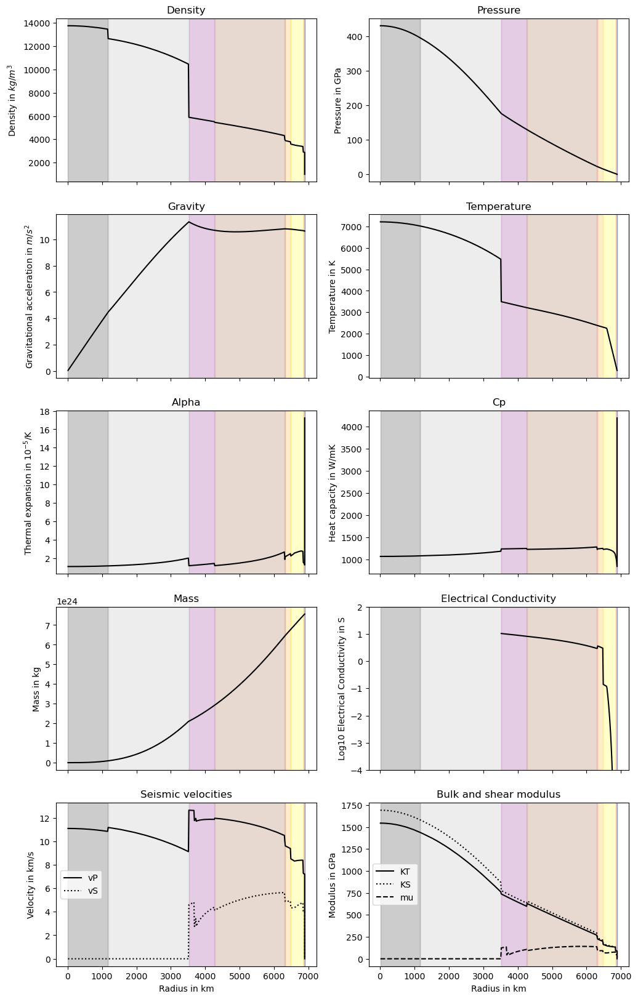

In [15]:
# To  Wolf 1069 b
if __name__ == "__main__":
    
    # Seus dados observados
    mass_obs = 1.26
    radius_obs = 1.08
    temp_obs = 290
    
    P_p=1.18*10**5
    mass_err=0.21
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)  
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [90]:
mass_obs = 1.26
radius_obs = 1.08
temp_obs = 290
    
P_p=1.18*10**5

In [91]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 33.0, 0.10, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

5473.403719664117 3494.3535575835003 2330331.3934356105 11752.925124765301 1124.3970704504827 5473.403719664117


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.555 R_E, M=3.9447 M_E, χ²=0.1409
[2/216] Fe=10, H2O=5 -> R=1.601 R_E, M=3.9594 M_E, χ²=0.1155
[3/216] Fe=10, H2O=10 -> R=1.631 R_E, M=3.9586 M_E, χ²=0.0991
[4/216] Fe=10, H2O=15 -> R=1.657 R_E, M=3.9581 M_E, χ²=0.0847
[5/216] Fe=10, H2O=20 -> R=1.679 R_E, M=3.9579 M_E, χ²=0.0727
[6/216] Fe=10, H2O=25 -> R=1.699 R_E, M=3.9579 M_E, χ²=0.0617
[7/216] Fe=10, H2O=30 -> R=1.718 R_E, M=3.9578 M_E, χ²=0.0511
[8/216] Fe=10, H2O=35 -> ERRO: cannot access local variable 'rho' where it is not associated with a value
[9/216] Fe=10, H2O=40 -> R=1.756 R_E, M=3.9577 M_E, χ²=0.0308
[10/216] Fe=10, H2O=45 -> R=1.774 R_E, M=3.9576 M_E, χ²=0.0209
[11/216] Fe=10, H2O=50 -> R=1.793 R_E, M=3.9573 M_E, χ²=0.01 Excellent fit

=== Best fit ===
x_Fe_tot = 10.0000 wt%
x_H2O_tot = 50.0000 wt%
χ² mínimo = 0.0119
(Search interrupted - excellent fit found)

 STEP 2: Refinement

=== REFINEMENT ===
Searching around Fe=10.0000, H2O=50.0000
Range

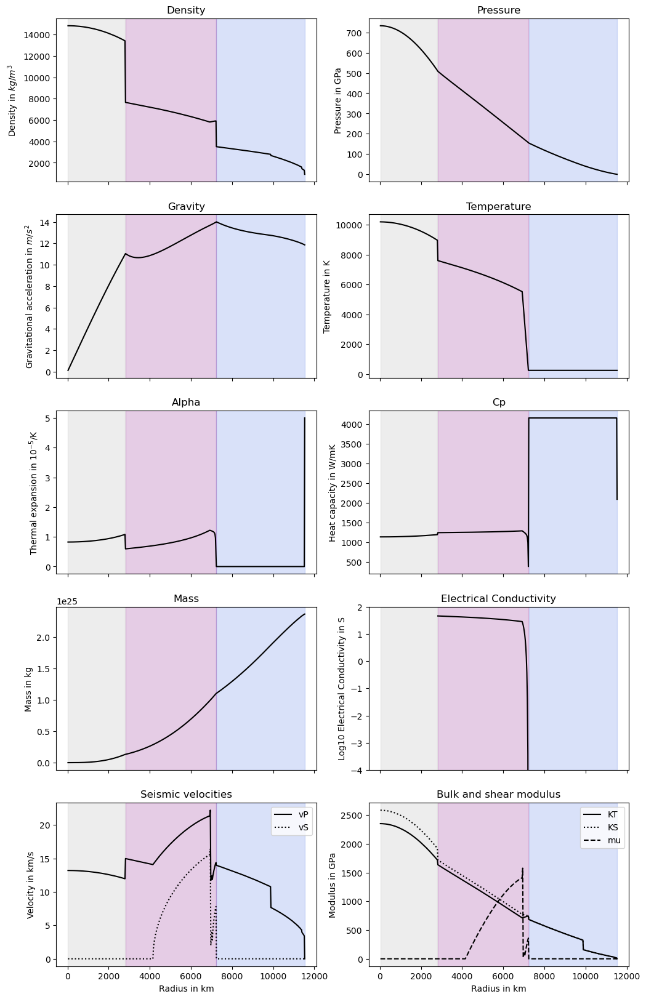

In [18]:
# To  tau Cet f
if __name__ == "__main__":
    mass_obs = 3.93
    radius_obs = 1.81
    temp_obs = 251
    
    P_p=1.46*10**5
    mass_err=1.37
    radius_err=0.2*radius_obs
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    
    
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [92]:
mass_obs = 3.93
radius_obs = 1.81
temp_obs = 251
    
P_p=1.46*10**5

In [93]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 8.50, 53.750 , temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

8957.61392691306 7595.87624022059 2797270.1721251598 14359.599051692407 1153.9440227572027 8957.61392691306


STEP 1: Coarse search
Testing 216 combinations.
[1/216] Fe=10, H2O=0 -> R=1.915 R_E, M=8.9544 M_E, χ²=0.1921
[2/216] Fe=10, H2O=5 -> R=1.974 R_E, M=8.9910 M_E, χ²=0.1673
[3/216] Fe=10, H2O=10 -> R=2.007 R_E, M=8.9876 M_E, χ²=0.1534
[4/216] Fe=10, H2O=15 -> R=2.036 R_E, M=8.9863 M_E, χ²=0.1411
[5/216] Fe=10, H2O=20 -> R=2.064 R_E, M=8.9861 M_E, χ²=0.1295
[6/216] Fe=10, H2O=25 -> R=2.090 R_E, M=8.9861 M_E, χ²=0.1182
[7/216] Fe=10, H2O=30 -> R=2.116 R_E, M=8.9859 M_E, χ²=0.1073
[8/216] Fe=10, H2O=35 -> R=2.142 R_E, M=8.9858 M_E, χ²=0.0967
[9/216] Fe=10, H2O=40 -> R=2.166 R_E, M=8.9855 M_E, χ²=0.0864
[10/216] Fe=10, H2O=45 -> R=2.190 R_E, M=8.9851 M_E, χ²=0.0763
[11/216] Fe=10, H2O=50 -> R=2.213 R_E, M=8.9844 M_E, χ²=0.0664
[12/216] Fe=10, H2O=55 -> R=2.237 R_E, M=8.9837 M_E, χ²=0.0567
[13/216] Fe=10, H2O=60 -> R=2.259 R_E, M=8.9827 M_E, χ²=0.0472
[14/216] Fe=10, H2O=65 -> R=2.282 R_E, M=8.9814 M_E, χ²=0.0378
[15/216] Fe=10, H2O=70 -> R=2.304 R_E, M=8.9799 M_E, χ²=0.0286
[16/216] Fe=10, H2

C:\Users\vitor\AppData\Local\Temp\ipykernel_7068\471959050.py:74: RuntimeWarning: invalid value encountered in scalar power
  Rm = ( Mm*3.0 / (4.0*math.pi*rho_m) + Rc**3 )**(1/3) # first guess rocky shell radius


[111/154] Fe=11.0, H2O=68.0 -> R=2.292 R_E, M=8.9813 M_E, χ²=0.0338
[112/154] Fe=11.0, H2O=69.2 -> R=2.297 R_E, M=8.9810 M_E, χ²=0.0316
[113/154] Fe=11.0, H2O=70.4 -> R=2.302 R_E, M=8.9806 M_E, χ²=0.0294
[114/154] Fe=11.0, H2O=71.60000000000001 -> R=2.307 R_E, M=8.9801 M_E, χ²=0.0272
[115/154] Fe=11.0, H2O=72.80000000000001 -> R=2.313 R_E, M=8.9797 M_E, χ²=0.0251
[116/154] Fe=11.0, H2O=74.00000000000001 -> R=2.318 R_E, M=8.9792 M_E, χ²=0.0229
[117/154] Fe=11.0, H2O=75.20000000000002 -> R=2.323 R_E, M=8.9786 M_E, χ²=0.0208
[118/154] Fe=11.0, H2O=76.40000000000002 -> R=2.329 R_E, M=8.9781 M_E, χ²=0.0186
[119/154] Fe=11.0, H2O=77.60000000000002 -> R=2.334 R_E, M=8.9776 M_E, χ²=0.0166
[120/154] Fe=11.0, H2O=78.80000000000003 -> R=2.339 R_E, M=8.9769 M_E, χ²=0.0145
[121/154] Fe=11.0, H2O=80.00000000000003 -> R=2.344 R_E, M=8.9763 M_E, χ²=0.0126
[122/154] Fe=11.0, H2O=81.20000000000003 -> R=2.350 R_E, M=8.9756 M_E, χ²=0.0107
[123/154] Fe=11.0, H2O=82.40000000000003 -> R=2.355 R_E, M=8.9750 M

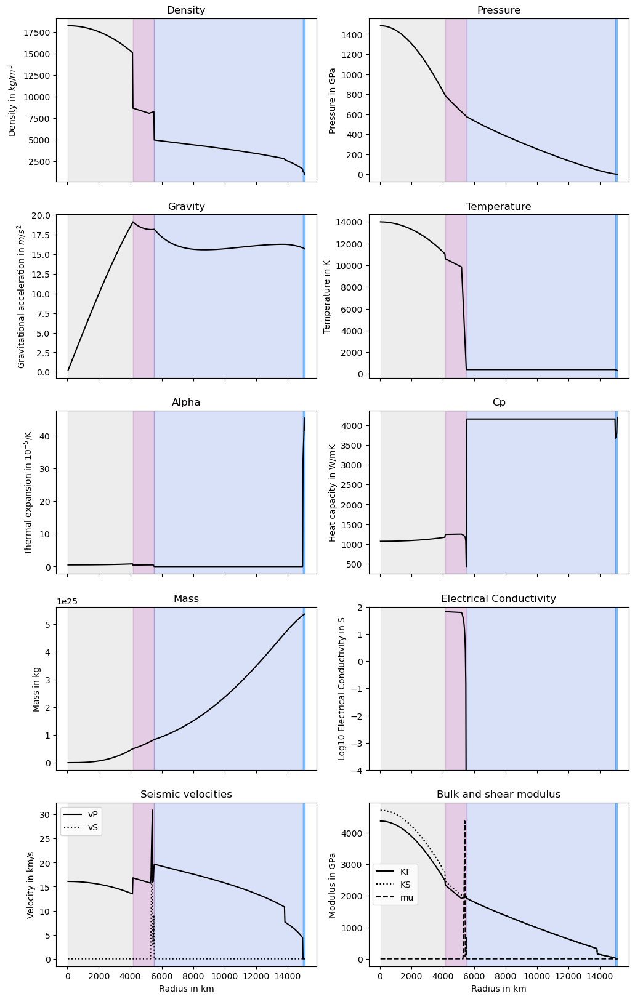

In [21]:
# To  K2-18 b
if __name__ == "__main__":
    mass_obs = 8.92
    radius_obs = 2.37
    temp_obs = 317
    
    P_p=2.56*10**5
    
    mass_err=1.7
    radius_err=0.22
    print("STEP 1: Coarse search")
    best_Fe, best_H2O, results = grid_search_rows(
        mass_obs, radius_obs, temp_obs, P_p, mass_err, radius_err,
        fe_range=(10, 70, 5), h2o_range=(0, 90, 5)) 

    print("\n STEP 2: Refinement")
    best_Fe, best_H2O, results_fine = refine_search(
        mass_obs, radius_obs,
        best_Fe, best_H2O, temp_obs, P_p, mass_err, radius_err,delta_Fe=0.15*best_Fe, delta_H2O=0.15*best_H2O,
                  step_Fe=0.05*best_Fe, step_H2O=0.05*best_H2O)    

Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, best_Fe, best_H2O, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")


visualization(Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat)

print(D/(radius_obs*R_t*1000), rho_core_mean)

In [94]:
mass_obs = 8.92
radius_obs = 2.37
temp_obs = 317
    
P_p=2.56*10**5

In [95]:
Rp_E,Rc_E,Rm_E,MOI,radius,density,gravity,pressure,temperature,alpha,cp,mass,elcond,vP,vS,KT,KS,mu,mat = interior_structure(mass_obs, 9.50, 84.80, temp_obs, P_p)
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")
# 1. Identify the liquid outer core (mat == 7)
outer_core_indices = np.where(mat == 7)[0]
inner_core_indices = np.where(mat == 8)[0]

#2. Outer core radius (CMB)
if len(outer_core_indices) > 0:
    Rc = radius[outer_core_indices[-1]]  # last point of the outer core = CMB
    Ric = radius[outer_core_indices[0]] if len(inner_core_indices) > 0 else 0  
else:
    # If there is no outer core, use all the core indices.
    all_core_indices = np.where((mat == 7) | (mat == 8))[0]
    Rc = radius[all_core_indices[-1]]
    Ric = 0

#3. Thickness of the outer core (where the dynamo operates)
D = Rc - Ric

# 4. Average properties of the OUTER CORE (mat == 7)
if len(outer_core_indices) > 0:
    rho_core_mean = np.mean(density[outer_core_indices])
    cp_core_mean = np.mean(cp[outer_core_indices])
    T_cmb = temperature[outer_core_indices[-1]]
else:
    print("The planet does not have a liquid outer core")

# manto silicatado: olivina ... pos-perovskita (inclua a crosta com mat >= 1 se quiser)
mantle_idx = np.where((mat >= 2) & (mat <= 6))[0]

T_base_manto = temperature[mantle_idx[0]]    # base do manto (lado do manto no CMB)
T_topo_manto = temperature[mantle_idx[-1]]   # topo do manto, logo abaixo da crosta

# base da litosfera = onde a adiabata do manto comeca (profundidade Dlid)
Dlid = 300e3                                  # m, default do ROWS; use o seu valor
i_lid = np.argmin(np.abs(radius - (radius[-1] - Dlid)))
T_lid = temperature[i_lid]

# os dois lados do CMB
T_cmb_nucleo = temperature[outer_core_indices[-1]]       # o seu T_cmb atual (lado do nucleo)
T_cmb_manto  = temperature[outer_core_indices[-1] + 1]   # lado do manto

print(T_cmb_nucleo, T_cmb_manto, D, rho_core_mean, cp_core_mean, T_cmb)

11054.395817940498 10595.756766267921 4138560.777683109 17204.232765157296 1100.663279802432 11054.395817940498
